# Visualization of 4 Core GENeSYS Scenarios

This notebook visualizes results from the 4 core scenarios (carbon price as key driver):
- **Go RES** (scenario_004): 500 EUR/tCO2 in 2040
- **NECPEssentials** (scenario_001): 250 EUR/tCO2 in 2040
- **REPowerEU++** (scenario_002): 350 EUR/tCO2 in 2040
- **Trinity** (scenario_003): 400 EUR/tCO2 in 2040

All scenarios use 30% charging markup and 1.0x technology cost.

In [257]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml
import re
from pathlib import Path
from typing import Dict, List, Optional, Tuple
from scipy.ndimage import gaussian_filter1d

# Configure matplotlib
plt.rcParams.update({
    'text.usetex': False,
    'font.family': 'serif',
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'figure.figsize': (12, 8),
    'axes.facecolor': '#f0f0f0',
    'figure.facecolor': 'white',
})
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})

# Base path
BASE_PATH = Path.cwd()
print(f"Base path: {BASE_PATH}")

Base path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM


In [258]:
# Scenario configuration â€” custom palette
# dark-slate-grey / steel-blue / honey-bronze / brown-red
# NOTE: Go RES now points to scenario_000 (new run 2026-02-11)
SCENARIOS = {
    'scenario_000': {'name': 'Go RES', 'carbon_price_2040': 500, 'color': '#1b4965'},
    'scenario_001': {'name': 'NECPEssentials', 'carbon_price_2040': 250, 'color': '#e09f3e'},
    'scenario_002': {'name': 'REPowerEU++', 'carbon_price_2040': 350, 'color': '#2a9d8f'},
    'scenario_003': {'name': 'Trinity', 'carbon_price_2040': 400, 'color': '#c1121f'},
}

# Results path (v2 = re-run with Crossover=-1 for vertex solution)
RESULTS_PATH = BASE_PATH / 'results' / 'uncertainty_scenarios_v2'
print(f"Results path: {RESULTS_PATH}")
print(f"Exists: {RESULTS_PATH.exists()}")

# Year mapping (investment period = 4 years, starting from 2020)
# Index 1 = 2020, Index 2 = 2024, etc.
YEAR_MAPPING = {i: 2020 + (i-1) * 4 for i in range(1, 15)}
YEAR_TO_INDEX = {v: k for k, v in YEAR_MAPPING.items()}
print(f"Year mapping: {YEAR_MAPPING}")

Results path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_scenarios_v2
Exists: True
Year mapping: {1: 2020, 2: 2024, 3: 2028, 4: 2032, 5: 2036, 6: 2040, 7: 2044, 8: 2048, 9: 2052, 10: 2056, 11: 2060, 12: 2064, 13: 2068, 14: 2072}


## Load Data

In [259]:
def load_yaml_file(filepath: Path) -> Dict:
    """Load a YAML file."""
    with open(filepath, 'r') as f:
        return yaml.safe_load(f)

def load_yaml_unsafe(filepath: Path) -> Dict:
    """Load a YAML file with UnsafeLoader (needed for numpy scalar tags)."""
    with open(filepath, 'r') as f:
        return yaml.load(f, Loader=yaml.UnsafeLoader)

def find_latest_result_file(scenario_folder: Path, variable: str) -> Optional[Path]:
    """Find the latest result file for a given variable."""
    pattern = f"*_{variable}_dict.yaml"
    files = list(scenario_folder.glob(pattern))
    if not files:
        return None
    return max(files, key=lambda x: x.stat().st_mtime)

def parse_cartesian_index(key_str: str) -> Optional[tuple]:
    """
    Parse CartesianIndex string format from Julia YAML output.
    Example: 'CartesianIndex(11, 1, 36)' -> (11, 1, 36)
    """
    if isinstance(key_str, str) and key_str.startswith('CartesianIndex('):
        match = re.search(r'CartesianIndex\(([^)]+)\)', key_str)
        if match:
            nums = [int(x.strip()) for x in match.group(1).split(',')]
            return tuple(nums)
    return None

def load_scenario_results(results_path: Path, scenarios: Dict) -> Dict:
    """Load h_dict and f_dict results for all scenarios."""
    results = {}

    for scenario_id, config in scenarios.items():
        scenario_folder = results_path / scenario_id

        if not scenario_folder.exists():
            print(f"Warning: Scenario folder not found: {scenario_folder}")
            continue

        h_file = find_latest_result_file(scenario_folder, 'h')
        f_file = find_latest_result_file(scenario_folder, 'f')
        if h_file:
            results[scenario_id] = {
                'h': load_yaml_file(h_file),
                'f': load_yaml_file(f_file) if f_file else {},
                'config': config
            }
            print(f"Loaded {scenario_id} ({config['name']}): h={h_file.name}, f={'yes' if f_file else 'no'}")
        else:
            print(f"Warning: No h_dict found for {scenario_id}")

    return results

# Load results
results = load_scenario_results(RESULTS_PATH, SCENARIOS)
print(f"\nLoaded {len(results)} scenarios")


Loaded scenario_000 (Go RES): h=scenario_000_cs_2026-02-16_18-37-25_h_dict.yaml, f=yes
Loaded scenario_001 (NECPEssentials): h=scenario_001_cs_2026-02-16_19-48-42_h_dict.yaml, f=yes
Loaded scenario_002 (REPowerEU++): h=scenario_002_cs_2026-02-16_21-26-02_h_dict.yaml, f=yes
Loaded scenario_003 (Trinity): h=scenario_003_cs_2026-02-16_22-46-04_h_dict.yaml, f=yes

Loaded 4 scenarios


In [260]:
def load_odpair_mapping(base_path: Path) -> Tuple[Dict, Dict]:
    """
    Load odpair and geographic element mappings.
    Uses scenario_000 as reference (network topology is shared across scenarios).
    
    Returns:
        Tuple of (odpair_map, geoid2country)
    """
    scenario_path = base_path / 'input_data' / 'uncertainty_scenarios' / 'scenario_000'
    
    odpair_map = {}
    geoid2country = {}
    
    # Load Odpair
    odpair_file = scenario_path / 'Odpair.yaml'
    if odpair_file.exists():
        odpair_data = load_yaml_file(odpair_file)
        if isinstance(odpair_data, list):
            for entry in odpair_data:
                if isinstance(entry, dict):
                    odpair_id = entry.get('id')
                    origin = entry.get('from')
                    dest = entry.get('to')
                    if odpair_id is not None and origin is not None and dest is not None:
                        odpair_map[int(odpair_id)] = (int(origin), int(dest))
    
    # Load GeographicElement
    geo_file = scenario_path / 'GeographicElement.yaml'
    if geo_file.exists():
        geo_data = load_yaml_file(geo_file)
        if isinstance(geo_data, list):
            for entry in geo_data:
                if isinstance(entry, dict):
                    geo_id = entry.get('id')
                    country = entry.get('country')
                    if geo_id is not None and country is not None:
                        geoid2country[int(geo_id)] = str(country)
    
    return odpair_map, geoid2country

# Load mappings
odpair_map, geoid2country = load_odpair_mapping(BASE_PATH)
print(f"Loaded {len(odpair_map)} OD pairs, {len(geoid2country)} geographic elements")

Loaded 2244 OD pairs, 81 geographic elements


## Figure 1: BEV OD Matrices with Deltas

In [261]:
def extract_bev_by_od(h_dict: Dict, odpair_map: Dict, geoid2country: Dict,
                      target_year: int = 2040, bev_tech_id: int = 1) -> pd.DataFrame:
    """
    Extract BEV counts by OD pair for a specific year.
    h_dict key format: CartesianIndex(year_idx, odpair_id, tech_id, generation) or tuple string
    """
    od_vehicles = {}
    target_year_idx = YEAR_TO_INDEX.get(target_year)
    
    for key, value in h_dict.items():
        if isinstance(value, str):
            value = float(value)
        
        if value < 0.01:
            continue
        
        # Try parsing as CartesianIndex first
        parsed = parse_cartesian_index(key)
        if parsed:
            year_idx, odpair_id, tech_id, gen = parsed
            if year_idx != target_year_idx or tech_id != bev_tech_id:
                continue
        elif isinstance(key, str):
            # Fallback: try parsing as tuple string
            key_clean = key.strip('()').split(',')
            year = int(key_clean[0].strip())
            odpair_id = int(key_clean[1].strip())
            tech_id = int(key_clean[2].strip())
            if year != target_year or tech_id != bev_tech_id:
                continue
        else:
            continue
        
        if odpair_id not in odpair_map:
            continue
        
        origin_geoid, dest_geoid = odpair_map[odpair_id]
        origin_country = geoid2country.get(origin_geoid)
        dest_country = geoid2country.get(dest_geoid)
        
        if origin_country is None or dest_country is None:
            continue
        
        od_key = (origin_country, dest_country)
        od_vehicles[od_key] = od_vehicles.get(od_key, 0.0) + value
    
    data = [{'origin_country': k[0], 'dest_country': k[1], 'bev_vehicles': v}
            for k, v in od_vehicles.items()]
    
    return pd.DataFrame(data)

def create_od_matrix(h_dict: Dict, odpair_map: Dict, geoid2country: Dict,
                     target_year: int = 2040) -> pd.DataFrame:
    """Create OD matrix from h_dict."""
    od_df = extract_bev_by_od(h_dict, odpair_map, geoid2country, target_year)
    
    if od_df.empty:
        return pd.DataFrame()
    
    countries = sorted(set(od_df['origin_country']) | set(od_df['dest_country']))
    matrix = pd.DataFrame(0.0, index=countries, columns=countries)
    
    for _, row in od_df.iterrows():
        matrix.loc[row['origin_country'], row['dest_country']] = row['bev_vehicles']
    
    return matrix

In [262]:
def plot_bev_od_matrices_with_deltas(results: Dict, odpair_map: Dict, geoid2country: Dict,
                                      target_year: int = 2040,
                                      reference_scenario: str = 'scenario_000',
                                      figsize: Tuple[int, int] = (18, 10),
                                      save_path: Optional[Path] = None):
    """
    Plot BEV OD matrices showing absolute values (top) and deltas from reference (bottom).
    Top row uses a sequential colormap; bottom row uses a diverging colormap.
    """
    matrices = {}
    for scenario_id, data in results.items():
        matrix = create_od_matrix(data['h'], odpair_map, geoid2country, target_year)
        if not matrix.empty:
            matrices[scenario_id] = matrix
    
    if reference_scenario not in matrices:
        print(f"Reference scenario '{reference_scenario}' not found!")
        return
    
    ref_matrix = matrices[reference_scenario]
    ref_name = results[reference_scenario]['config']['name']
    other_scenarios = [s for s in matrices.keys() if s != reference_scenario]
    
    # Separate scales for top (absolute) and bottom (delta)
    abs_vmax = max(m.values.max() for m in matrices.values())
    delta_vmax = 0
    for scenario_id in other_scenarios:
        delta = matrices[scenario_id] - ref_matrix
        delta_vmax = max(delta_vmax, abs(delta.values.min()), abs(delta.values.max()))
    
    fig, axes = plt.subplots(2, len(other_scenarios) + 1, figsize=figsize)
    fig.subplots_adjust(right=0.88, wspace=0.3, hspace=0.35)
    
    cmap_abs = 'YlOrRd'       # sequential for absolute values
    cmap_delta = 'RdBu_r'     # diverging for deltas
    
    # --- Top row: absolute values ---
    ax = axes[0, 0]
    im_abs = ax.imshow(ref_matrix.values, cmap=cmap_abs, aspect='auto',
                       vmin=0, vmax=abs_vmax)
    ax.set_xticks(range(len(ref_matrix.columns)))
    ax.set_xticklabels(ref_matrix.columns, rotation=45, ha='right', fontsize=12)
    ax.set_yticks(range(len(ref_matrix.index)))
    ax.set_yticklabels(ref_matrix.index, fontsize=12)
    ax.set_title(f'{ref_name} (Reference)\nTotal: {ref_matrix.sum().sum():.0f}', fontsize=14)
    
    for idx, scenario_id in enumerate(other_scenarios):
        ax = axes[0, idx + 1]
        matrix = matrices[scenario_id]
        name = results[scenario_id]['config']['name']
        
        im_abs = ax.imshow(matrix.values, cmap=cmap_abs, aspect='auto',
                           vmin=0, vmax=abs_vmax)
        ax.set_xticks(range(len(matrix.columns)))
        ax.set_xticklabels(matrix.columns, rotation=45, ha='right', fontsize=12)
        ax.set_yticks(range(len(matrix.index)))
        ax.set_yticklabels(matrix.index, fontsize=12)
        ax.set_title(f'{name}\nTotal: {matrix.sum().sum():.0f}', fontsize=14)
    
    # --- Bottom row: deltas ---
    ax = axes[1, 0]
    ax.text(0.5, 0.5, f'Reference:\n{ref_name}',
            ha='center', va='center', fontsize=14, transform=ax.transAxes)
    ax.axis('off')
    
    for idx, scenario_id in enumerate(other_scenarios):
        ax = axes[1, idx + 1]
        matrix = matrices[scenario_id]
        name = results[scenario_id]['config']['name']
        
        delta = matrix - ref_matrix
        im_delta = ax.imshow(delta.values, cmap=cmap_delta, aspect='auto',
                             vmin=-delta_vmax, vmax=delta_vmax)
        
        ax.set_xticks(range(len(delta.columns)))
        ax.set_xticklabels(delta.columns, rotation=45, ha='right', fontsize=12)
        ax.set_yticks(range(len(delta.index)))
        ax.set_yticklabels(delta.index, fontsize=12)
        
        total_delta = delta.sum().sum()
        sign = '+' if total_delta >= 0 else ''
        ax.set_title(f'{name} $-$ {ref_name}\nNet: {sign}{total_delta:.0f}', fontsize=14)
    
    # Two separate colorbars
    cbar_ax_abs = fig.add_axes([0.90, 0.55, 0.02, 0.32])
    cbar_abs = fig.colorbar(im_abs, cax=cbar_ax_abs)
    cbar_abs.set_label('BEV vehicles', fontsize=11)
    
    cbar_ax_delta = fig.add_axes([0.90, 0.12, 0.02, 0.32])
    cbar_delta = fig.colorbar(im_delta, cax=cbar_ax_delta)
    cbar_delta.set_label('$\Delta$ BEV vehicles', fontsize=11)
    
    plt.suptitle(f'BEV Fleet by OD ({target_year}): Absolute Values (top) and Differences from Reference (bottom)',
                 fontsize=16, y=0.98)
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
        print(f"Saved to {save_path}")
    
    plt.show()
    
    print("\n=== Scenario Comparison Summary ===")
    ref_total = ref_matrix.sum().sum()
    print(f"Reference ({ref_name}): {ref_total:.0f} BEVs")
    for scenario_id in other_scenarios:
        name = results[scenario_id]['config']['name']
        other_total = matrices[scenario_id].sum().sum()
        diff = other_total - ref_total
        pct = (diff / ref_total) * 100 if ref_total > 0 else 0
        sign = '+' if diff >= 0 else ''
        print(f"{name}: {other_total:.0f} BEVs ({sign}{diff:.0f}, {sign}{pct:.1f}%)")

<>:91: SyntaxWarning: invalid escape sequence '\D'
<>:91: SyntaxWarning: invalid escape sequence '\D'
C:\Users\simuser\AppData\Local\Temp\ipykernel_23268\3157107043.py:91: SyntaxWarning: invalid escape sequence '\D'
  cbar_delta.set_label('$\Delta$ BEV vehicles', fontsize=11)


Saved to c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\bev_od_matrices_4scenarios_2040.pdf


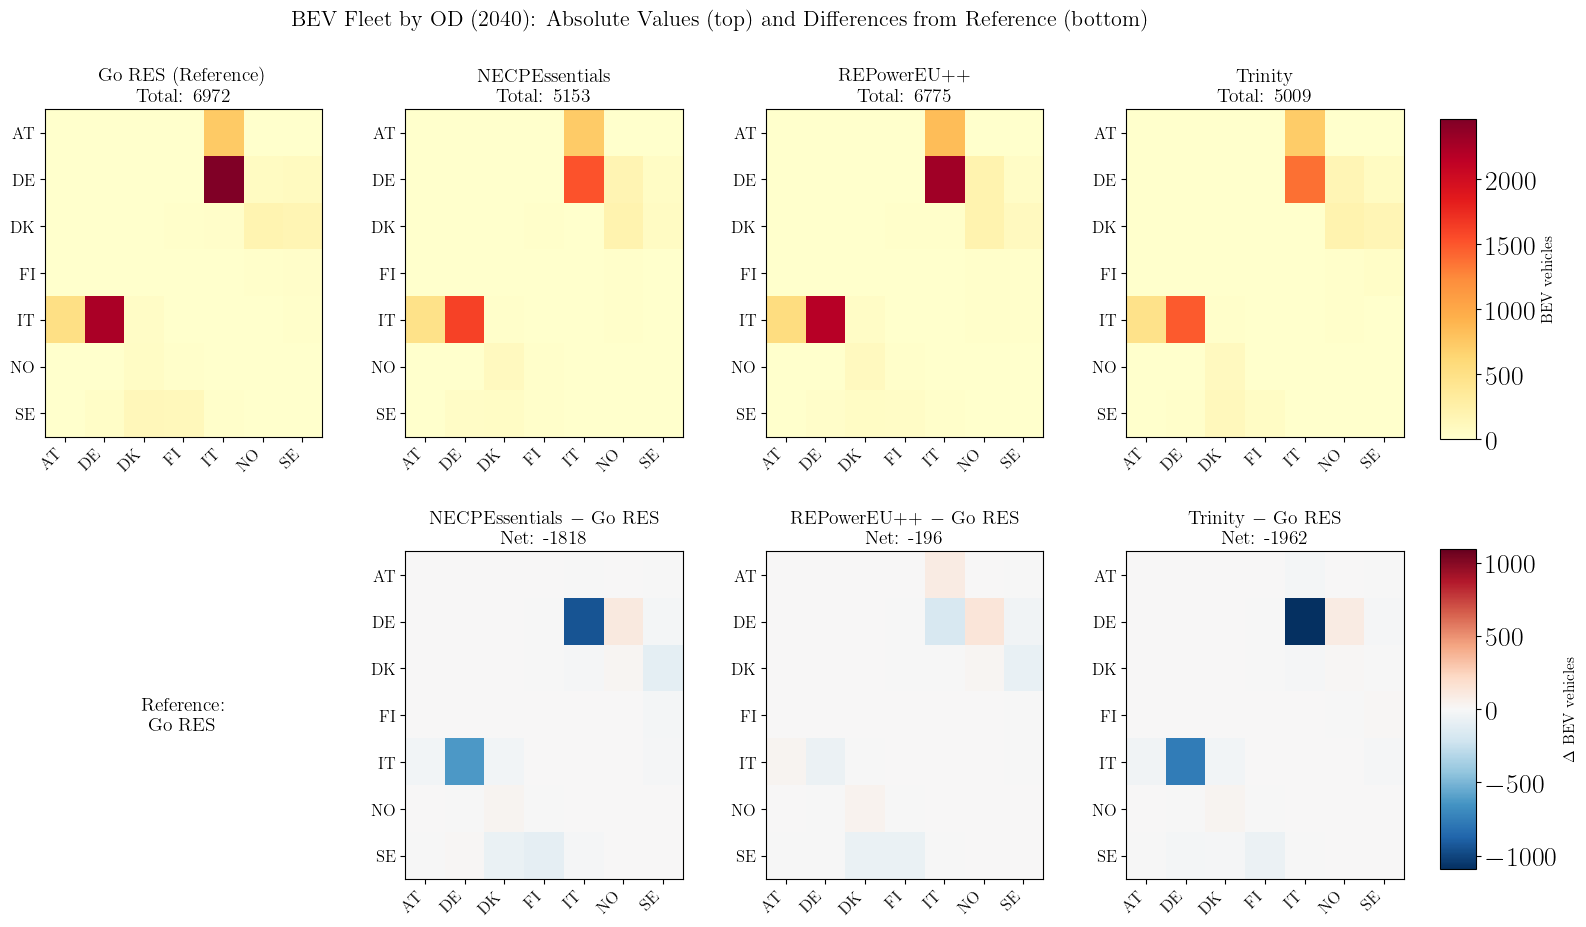


=== Scenario Comparison Summary ===
Reference (Go RES): 6972 BEVs
NECPEssentials: 5153 BEVs (-1818, -26.1%)
REPowerEU++: 6775 BEVs (-196, -2.8%)
Trinity: 5009 BEVs (-1962, -28.1%)


In [263]:
# Plot BEV OD matrices with deltas
if results:
    plot_bev_od_matrices_with_deltas(
        results, odpair_map, geoid2country,
        target_year=2040,
        reference_scenario='scenario_000',
        save_path=BASE_PATH / 'figures' / 'bev_od_matrices_4scenarios_2040.pdf'
    )
else:
    print("No results loaded. Please run the optimization first.")

## Figure 2: BEV Fleet Growth Comparison

In [264]:
def extract_fleet_by_year(h_dict: Dict, bev_tech_id: int = 1, f_dict: Dict = None, active_only: bool = False) -> Dict[int, float]:
    """
    Extract total BEV fleet by year from h_dict.
    If active_only=True and f_dict is provided, only count vehicles on OD pairs with freight.
    """
    fleet_by_year = {}

    # If active_only, pre-compute BEV freight per (year, odpair)
    bev_freight = {}
    if active_only and f_dict:
        import re as _re
        f_tuple_re = _re.compile(r"\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)")
        for key, value in f_dict.items():
            if isinstance(value, str):
                value = float(value)
            if value < 1e-6:
                continue
            m = f_tuple_re.match(str(key))
            if m:
                year = int(m.group(1))
                odpair_id = int(m.group(3))
                tv_id = int(m.group(6))
                if tv_id == bev_tech_id:
                    bev_freight[(year, odpair_id)] = bev_freight.get((year, odpair_id), 0) + value

    for key, value in h_dict.items():
        if isinstance(value, str):
            value = float(value)

        if value < 0.01:
            continue

        odpair_id = None
        # Try CartesianIndex format first
        parsed = parse_cartesian_index(key)
        if parsed:
            year_idx, odpair_id, tech_id, gen = parsed
            year = YEAR_MAPPING.get(year_idx, year_idx)
        elif isinstance(key, str):
            key_clean = key.strip('()').split(',')
            year = int(key_clean[0].strip())
            odpair_id = int(key_clean[1].strip())
            tech_id = int(key_clean[2].strip())
        else:
            continue

        if tech_id != bev_tech_id:
            continue

        # Filter idle vehicles if requested
        if active_only and f_dict and odpair_id is not None:
            if bev_freight.get((year, odpair_id), 0) < 1e-6:
                continue  # Skip idle vehicles

        if year not in fleet_by_year:
            fleet_by_year[year] = 0.0
        fleet_by_year[year] += value

    return fleet_by_year

def plot_bev_fleet_growth_comparison(results: Dict,
                                      years: List[int] = None,
                                      figsize: Tuple[int, int] = (10, 5.5),
                                      save_path: Optional[Path] = None,
                                      active_only: bool = False):
    """
    Plot bar chart comparing BEV fleet growth across scenarios.
    If active_only=True, only count vehicles on OD pairs with BEV freight.
    """
    if years is None:
        years = [2024, 2032, 2040, 2048, 2056]

    fleet_data = {}
    for scenario_id, data in results.items():
        fleet_by_year = extract_fleet_by_year(data['h'], f_dict=data.get('f'), active_only=active_only)
        fleet_data[scenario_id] = fleet_by_year

    scenarios = list(results.keys())
    n_scenarios = len(scenarios)
    n_years = len(years)

    x = np.arange(n_years)
    width = 0.8 / n_scenarios

    fig, ax = plt.subplots(figsize=figsize)

    for i, scenario_id in enumerate(scenarios):
        config = results[scenario_id]['config']
        fleet = fleet_data[scenario_id]
        values = [fleet.get(y, 0) for y in years]

        bars = ax.bar(x + i * width - (n_scenarios - 1) * width / 2,
                      values, width,
                      label=config['name'],
                      color=config['color'], alpha=0.85,
                      edgecolor='white', linewidth=0.5)

    title_suffix = " (active only)" if active_only else ""
    ax.set_xlabel('Year', fontsize=13)
    ax.set_ylabel(f'BEV fleet (vehicles){title_suffix}', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(years, fontsize=12)
    ax.tick_params(axis='y', labelsize=11)
    ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
    ax.grid(True, alpha=0.2, axis='y')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}k'))
    ax.set_axisbelow(True)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
        print(f"Saved to {save_path} (+ .svg)")

    plt.show()

    print(f"\n=== BEV Fleet by Year and Scenario{title_suffix} ===")
    print(f"{'Year':<8}", end='')
    for scenario_id in scenarios:
        name = results[scenario_id]['config']['name']
        print(f"{name:<18}", end='')
    print()
    print("-" * (8 + 18 * n_scenarios))

    for year in years:
        print(f"{year:<8}", end='')
        for scenario_id in scenarios:
            val = fleet_data[scenario_id].get(year, 0)
            print(f"{val:>14,.0f}    ", end='')
        print()


Saved to c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\bev_fleet_growth_4scenarios.pdf (+ .svg)


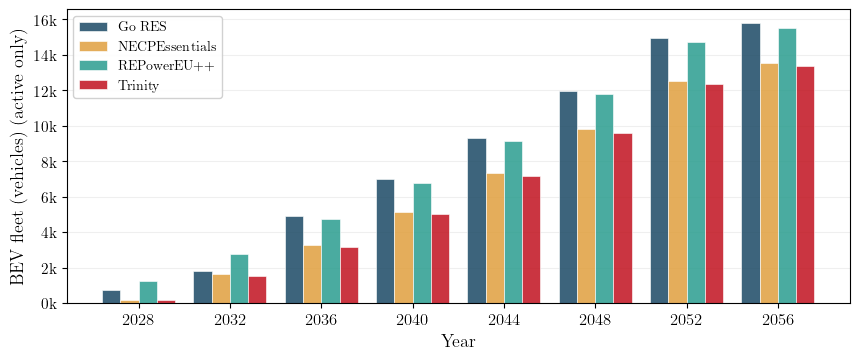


=== BEV Fleet by Year and Scenario (active only) ===
Year    Go RES            NECPEssentials    REPowerEU++       Trinity           
--------------------------------------------------------------------------------
2028               729               170             1,233               160    
2032             1,827             1,626             2,771             1,509    
2036             4,900             3,264             4,723             3,134    
2040             6,972             5,153             6,775             5,009    
2044             9,324             7,314             9,152             7,154    
2048            11,979             9,792            11,786             9,619    
2052            14,966            12,539            14,746            12,349    
2056            15,800            13,562            15,522            13,387    


In [265]:
# Plot BEV fleet growth comparison (ACTIVE vehicles only)
if results:
    plot_bev_fleet_growth_comparison(
        results,
        years=[2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056],
        figsize=(9, 4),
        save_path=BASE_PATH / 'figures' / 'bev_fleet_growth_4scenarios.pdf',
        active_only=True
    )
else:
    print("No results loaded. Please run the optimization first.")


## Summary Statistics

In [266]:
# Print summary statistics for each scenario
if results:
    print("=" * 80)
    print("SUMMARY: BEV Fleet in 2040 by Scenario")
    print("=" * 80)
    
    for scenario_id, data in results.items():
        config = data['config']
        fleet = extract_fleet_by_year(data['h'])
        
        fleet_2040 = fleet.get(2040, 0)
        fleet_2056 = fleet.get(2056, 0)
        
        print(f"\n{config['name']} (Carbon price: {config['carbon_price_2040']} EUR/tCO2):")
        print(f"  BEV fleet in 2040: {fleet_2040:,.0f} vehicles")
        print(f"  BEV fleet in 2056: {fleet_2056:,.0f} vehicles")
        
        if fleet_2040 > 0:
            growth = (fleet_2056 - fleet_2040) / fleet_2040 * 100
            print(f"  Growth 2040->2056: {growth:+.1f}%")

SUMMARY: BEV Fleet in 2040 by Scenario

Go RES (Carbon price: 500 EUR/tCO2):
  BEV fleet in 2040: 6,972 vehicles
  BEV fleet in 2056: 15,800 vehicles
  Growth 2040->2056: +126.6%

NECPEssentials (Carbon price: 250 EUR/tCO2):
  BEV fleet in 2040: 5,153 vehicles
  BEV fleet in 2056: 13,562 vehicles
  Growth 2040->2056: +163.2%

REPowerEU++ (Carbon price: 350 EUR/tCO2):
  BEV fleet in 2040: 6,775 vehicles
  BEV fleet in 2056: 15,522 vehicles
  Growth 2040->2056: +129.1%

Trinity (Carbon price: 400 EUR/tCO2):
  BEV fleet in 2040: 5,009 vehicles
  BEV fleet in 2056: 13,387 vehicles
  Growth 2040->2056: +167.2%


## Figure 3: Charging Load by Latitude Comparison

In [267]:
def load_geo_latitude_mapping(base_path: Path) -> Dict[int, float]:
    """
    Load geographic element latitude data.
    Uses scenario_000 as reference (network topology is shared across scenarios).
    
    Returns:
        Dict mapping geo_id -> latitude
    """
    geo_file = base_path / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'GeographicElement.yaml'
    
    geo_id_to_lat = {}
    
    if geo_file.exists():
        geo_data = load_yaml_file(geo_file)
        if isinstance(geo_data, list):
            for entry in geo_data:
                if isinstance(entry, dict):
                    if entry.get('type') == 'node' and 'coordinate_lat' in entry:
                        geo_id_to_lat[entry['id']] = entry['coordinate_lat']
    else:
        print(f"Warning: GeographicElement.yaml not found at {geo_file}")
    
    return geo_id_to_lat

def calculate_charging_by_latitude_from_q(q_dict: Dict, geo_id_to_lat: Dict, 
                                           target_year: int) -> List[Tuple[float, float]]:
    """
    Calculate BEV charging (GWh) aggregated by latitude for a specific year.
    Uses q_fuel_infr_plus_dict which has structure: CartesianIndex(year_idx, f_l_idx, geo_id)
    """
    SCALING_FACTOR = 1000  # Energy values are scaled in kW
    charging_by_lat = {}
    
    target_year_idx = YEAR_TO_INDEX.get(target_year)
    if target_year_idx is None:
        print(f"Warning: Year {target_year} not found in year mapping")
        return []
    
    for key_str, energy_value_scaled in q_dict.items():
        try:
            parsed = parse_cartesian_index(key_str)
            if parsed is None:
                continue
            
            # q_fuel_infr_plus structure: (year_idx, f_l_idx, geo_id)
            year_idx = parsed[0]
            f_l_idx = parsed[1]  # 1=fast charging (BEV), 2=slow (BEV), 3=diesel (ICEV)
            geo_id = parsed[2]
            
            energy_value = float(energy_value_scaled) if isinstance(energy_value_scaled, str) else energy_value_scaled
            
            # Filter: only target year, only BEV charging (f_l_idx 1 or 2)
            if year_idx != target_year_idx or f_l_idx not in [1, 2] or energy_value <= 0:
                continue
            
            if geo_id not in geo_id_to_lat:
                continue
            
            lat = geo_id_to_lat[geo_id]
            energy_kwh = energy_value * SCALING_FACTOR
            
            if lat not in charging_by_lat:
                charging_by_lat[lat] = 0.0
            charging_by_lat[lat] += energy_kwh
            
        except Exception as e:
            continue
    
    # Convert to list of (lat, gwh) sorted by latitude
    result = [(lat, kwh / 1e6) for lat, kwh in charging_by_lat.items()]  # Convert to GWh
    result.sort(key=lambda x: x[0])
    return result

# Load latitude mapping
geo_id_to_lat = load_geo_latitude_mapping(BASE_PATH)
print(f"Loaded {len(geo_id_to_lat)} node locations with latitude data")

Loaded 81 node locations with latitude data


In [268]:
def load_scenario_q_results(results_path: Path, scenarios: Dict) -> Dict:
    """Load q_fuel_infr_plus_dict results for all scenarios."""
    results_with_q = {}
    
    for scenario_id, config in scenarios.items():
        scenario_folder = results_path / scenario_id
        
        if not scenario_folder.exists():
            continue
        
        q_file = find_latest_result_file(scenario_folder, 'q_fuel_infr_plus')
        if q_file:
            results_with_q[scenario_id] = {
                'q': load_yaml_file(q_file),
                'config': config
            }
            print(f"Loaded q_fuel_infr_plus for {scenario_id} ({config['name']})")
        else:
            print(f"Warning: No q_fuel_infr_plus_dict found for {scenario_id}")
    
    return results_with_q

# Load q_fuel_infr_plus results (infrastructure charging capacity by location)
q_results = load_scenario_q_results(RESULTS_PATH, SCENARIOS)
print(f"\nLoaded q_fuel_infr_plus for {len(q_results)} scenarios")

Loaded q_fuel_infr_plus for scenario_000 (Go RES)
Loaded q_fuel_infr_plus for scenario_001 (NECPEssentials)
Loaded q_fuel_infr_plus for scenario_002 (REPowerEU++)
Loaded q_fuel_infr_plus for scenario_003 (Trinity)

Loaded q_fuel_infr_plus for 4 scenarios


In [269]:
def plot_charging_by_latitude_comparison(q_results: Dict, geo_id_to_lat: Dict,
                                          target_year: int = 2040,
                                          figsize: Tuple[int, int] = (14, 8),
                                          save_path: Optional[Path] = None):
    """
    Plot charging infrastructure capacity by latitude comparing all 4 GENeSYS scenarios.
    """
    lat_data = {}
    for scenario_id, data in q_results.items():
        charging_data = calculate_charging_by_latitude_from_q(data['q'], geo_id_to_lat, target_year)
        if charging_data:
            lat_data[scenario_id] = charging_data
            total_gwh = sum(x[1] for x in charging_data)
            print(f"{data['config']['name']}: {len(charging_data)} locations, {total_gwh:.2f} GWh total")
    
    if not lat_data:
        print("No latitude data found!")
        return
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Scenario order (sorted by carbon price, highest first)
    scenario_order = ['scenario_000', 'scenario_003', 'scenario_002', 'scenario_001']
    
    for scenario_id in scenario_order:
        if scenario_id not in lat_data:
            continue
        
        config = q_results[scenario_id]['config']
        data = lat_data[scenario_id]
        
        if len(data) < 3:
            continue
        
        lats = np.array([x[0] for x in data])
        gwh = np.array([x[1] for x in data])
        
        sort_idx = np.argsort(lats)
        lat_sorted = lats[sort_idx]
        gwh_sorted = gwh[sort_idx]
        
        gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
        
        total_gwh = sum(gwh)
        label = f"{config['name']} - {total_gwh:.1f} GWh"
        
        ax.fill_between(lat_sorted, 0, gwh_smoothed, color=config['color'], alpha=0.25)
        ax.plot(lat_sorted, gwh_smoothed, color=config['color'], linewidth=2.5, label=label)
    
    # Add country reference lines
    country_lats = {'IT': 42.5, 'AT': 47.5, 'DE': 51.0, 'DK': 56.0, 'SE': 62.0, 'NO': 64.0}
    
    ylim = ax.get_ylim()
    for country, lat in country_lats.items():
        ax.axvline(lat, color='gray', linestyle=':', alpha=0.4, linewidth=1)
        ax.text(lat, ylim[1] * 0.95, country, ha='center', va='top', 
                fontsize=10, fontweight='bold', color='#555',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    
    ax.set_xlabel('Latitude (deg N)', fontsize=14)
    ax.set_ylabel('Charging Infrastructure Capacity (GWh)', fontsize=14)
    ax.set_title(f'BEV Charging Infrastructure by Latitude - Year {target_year}\n'
                 f'Comparison of 4 GENeSYS-MOD Scenarios (30% charging markup, 1.0x tech cost)', 
                 fontsize=14)
    ax.legend(loc='upper right', fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(40, 70)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
        print(f"\nSaved to {save_path}")
    
    plt.show()
    
    print("\n" + "=" * 70)
    print(f"CHARGING BY LATITUDE SUMMARY (Year {target_year})")
    print("=" * 70)
    for scenario_id in scenario_order:
        if scenario_id not in lat_data:
            continue
        config = q_results[scenario_id]['config']
        total = sum(x[1] for x in lat_data[scenario_id])
        print(f"{config['name']}: {total:.2f} GWh")

In [270]:
def plot_charging_by_latitude_multi_year(q_results: Dict, geo_id_to_lat: Dict,
                                          years: List[int] = [2032, 2040, 2048],
                                          figsize: Tuple[int, int] = (16, 10),
                                          max_gwh: float = 30,  # Fixed x-axis scale
                                          save_path: Optional[Path] = None):
    """
    Plot charging infrastructure by latitude for multiple years side-by-side.
    Axes flipped: latitude on Y-axis (north at top), GWh on X-axis.
    """
    n_years = len(years)
    fig, axes = plt.subplots(1, n_years, figsize=figsize, sharey=True)
    if n_years == 1:
        axes = [axes]
    
    # Scenario order (sorted by carbon price, highest first)
    scenario_order = ['scenario_000', 'scenario_003', 'scenario_002', 'scenario_001']
    
    # Country reference latitudes
    country_lats = {'IT': 42.5, 'AT': 47.5, 'DE': 51.0, 'DK': 56.0, 'SE': 62.0, 'NO': 64.0}
    
    # First pass: calculate data
    all_lat_data = {}
    for year in years:
        all_lat_data[year] = {}
        for scenario_id, data in q_results.items():
            charging_data = calculate_charging_by_latitude_from_q(data['q'], geo_id_to_lat, year)
            if charging_data:
                all_lat_data[year][scenario_id] = charging_data
    
    # Second pass: plot
    for i, (year, ax) in enumerate(zip(years, axes)):
        lat_data = all_lat_data[year]
        
        for scenario_id in scenario_order:
            if scenario_id not in lat_data:
                continue
            
            config = q_results[scenario_id]['config']
            data = lat_data[scenario_id]
            
            if len(data) < 3:
                continue
            
            lats = np.array([x[0] for x in data])
            gwh = np.array([x[1] for x in data])
            
            # Sort by latitude
            sort_idx = np.argsort(lats)
            lat_sorted = lats[sort_idx]
            gwh_sorted = gwh[sort_idx]
            
            # Apply Gaussian smoothing
            gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
            
            label = config['name'] if i == 0 else None
            
            # Plot with flipped axes: x=GWh, y=latitude
            ax.fill_betweenx(lat_sorted, 0, gwh_smoothed, color=config['color'], alpha=0.2)
            ax.plot(gwh_smoothed, lat_sorted, color=config['color'], linewidth=1.5, label=label)
        
        # Add horizontal country reference lines
        for country, lat in country_lats.items():
            ax.axhline(lat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        
        ax.set_title(f'{year}', fontsize=16, fontweight='bold')
        ax.set_xlabel('Charging Capacity (GWh)', fontsize=12)
        ax.set_xlim(0, max_gwh)  # Fixed scale
        ax.set_ylim(40, 68)
        ax.grid(True, alpha=0.3, axis='x')
        ax.tick_params(axis='both', labelsize=11)
    
    # Y-axis label only on leftmost panel
    axes[0].set_ylabel('Latitude (Â°N)', fontsize=14)
    
    # Add country labels on the right side of rightmost panel
    ax_right = axes[-1]
    for country, lat in country_lats.items():
        ax_right.text(1.02, lat, country, transform=ax_right.get_yaxis_transform(),
                     fontsize=11, fontweight='bold', va='center', ha='left',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', 
                              edgecolor='#888', alpha=0.9))
    
    # Add legend below the plots
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=11, 
               bbox_to_anchor=(0.5, -0.02), frameon=True)
    
    plt.suptitle('BEV Charging Infrastructure by Latitude\n'
                 'Comparison of 4 GENeSYS-MOD Scenarios (30% markup, 1.0x tech cost)', 
                 fontsize=15, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.12, wspace=0.08)
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
        print(f"Saved to {save_path}")
    
    plt.show()
    
    # Print summary
    print("\n" + "=" * 80)
    print("CHARGING BY LATITUDE SUMMARY")
    print("=" * 80)
    print(f"{'Scenario':<25}", end='')
    for year in years:
        print(f"{year:>12} GWh", end='')
    print()
    print("-" * (25 + 15 * len(years)))
    
    for scenario_id in scenario_order:
        if scenario_id not in q_results:
            continue
        config = q_results[scenario_id]['config']
        print(f"{config['name']}"[:24].ljust(25), end='')
        for year in years:
            if scenario_id in all_lat_data[year]:
                total = sum(x[1] for x in all_lat_data[year][scenario_id])
                print(f"{total:>12.1f}    ", end='')
            else:
                print(f"{'N/A':>12}    ", end='')
        print()

Saved to c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\charging_by_latitude_multi_year.pdf


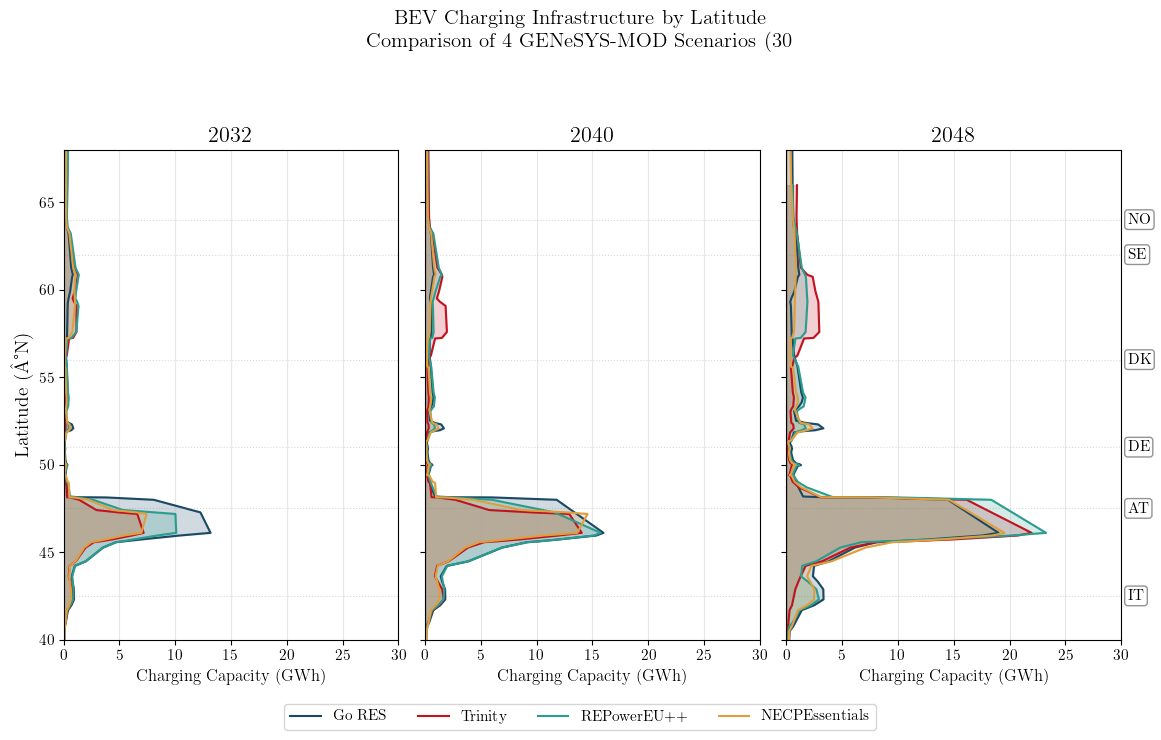


CHARGING BY LATITUDE SUMMARY
Scenario                         2032 GWh        2040 GWh        2048 GWh
----------------------------------------------------------------------
Go RES                           92.9           130.3           166.8    
Trinity                          63.1           117.1           153.5    
REPowerEU++                      93.6           128.7           164.7    
NECPEssentials                   66.2           119.2           153.2    


In [271]:
# Plot charging by latitude - multi-year horizontal comparison (north at top)
if q_results and geo_id_to_lat:
    plot_charging_by_latitude_multi_year(
        q_results, geo_id_to_lat,
        years=[2032, 2040, 2048],
        figsize=(12, 7),
        save_path=BASE_PATH / 'figures' / 'charging_by_latitude_multi_year.pdf'
    )
else:
    print("Missing data for latitude comparison")

## Section 4.3: Mandatory Breaks vs. Unconstrained Charging

Compare charging load distribution when charging is constrained to mandatory break locations vs. unconstrained (free siting).

In [272]:
# Load breaks-only results
BREAKS_PATH = BASE_PATH / 'results' / 'uncertainty_scenarios_breaks_only'
print(f"Breaks-only results path: {BREAKS_PATH}")
print(f"Exists: {BREAKS_PATH.exists()}")

# Load h_dict for breaks-only
breaks_results = load_scenario_results(BREAKS_PATH, SCENARIOS)
print(f"\nLoaded breaks-only h_dict for {len(breaks_results)} scenarios")

# Load q_fuel_infr_plus for breaks-only
breaks_q_results = load_scenario_q_results(BREAKS_PATH, SCENARIOS)
print(f"Loaded breaks-only q_fuel_infr_plus for {len(breaks_q_results)} scenarios")

# Load summary stats for cost comparison
print("\n=== Objective Value Comparison ===")
print(f"{'Scenario':<20} {'Unconstrained':>18} {'Breaks Only':>18} {'Diff':>12} {'Rel.Diff':>10}")
print("-" * 80)
for scenario_id, config in SCENARIOS.items():
    unc_stats_file = RESULTS_PATH / scenario_id / 'summary_stats.yaml'
    brk_stats_file = BREAKS_PATH / scenario_id / 'summary_stats.yaml'
    
    unc_val = None
    brk_val = None
    
    if unc_stats_file.exists():
        unc_data = load_yaml_file(unc_stats_file)
        unc_val = float(unc_data.get('objective_value', 0))
    
    if brk_stats_file.exists():
        brk_data = load_yaml_file(brk_stats_file)
        brk_val = float(brk_data.get('objective_value', 0))
    
    if unc_val is not None and brk_val is not None:
        diff = brk_val - unc_val
        rel = diff / unc_val * 100
        print(f"{config['name']:<20} {unc_val:>18.6e} {brk_val:>18.6e} {diff:>12.2e} {rel:>9.4f}%")
    else:
        print(f"{config['name']:<20} {'N/A':>18} {'N/A':>18}")

Breaks-only results path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_scenarios_breaks_only
Exists: True
Loaded scenario_000 (Go RES): h=scenario_000_cs_2026-02-14_20-51-10_h_dict.yaml, f=yes
Loaded scenario_001 (NECPEssentials): h=scenario_001_cs_2026-02-14_22-29-10_h_dict.yaml, f=yes
Loaded scenario_002 (REPowerEU++): h=scenario_002_cs_2026-02-14_23-47-28_h_dict.yaml, f=yes
Loaded scenario_003 (Trinity): h=scenario_003_cs_2026-02-15_01-16-54_h_dict.yaml, f=yes

Loaded breaks-only h_dict for 4 scenarios
Loaded q_fuel_infr_plus for scenario_000 (Go RES)
Loaded q_fuel_infr_plus for scenario_001 (NECPEssentials)
Loaded q_fuel_infr_plus for scenario_002 (REPowerEU++)
Loaded q_fuel_infr_plus for scenario_003 (Trinity)
Loaded breaks-only q_fuel_infr_plus for 4 scenarios

=== Objective Value Comparison ===
Scenario                  Unconstrained        Breaks Only         Diff   Rel.Diff
---------

In [273]:
def plot_breaks_vs_unconstrained_latitude(q_results: Dict, breaks_q_results: Dict,
                                           geo_id_to_lat: Dict,
                                           target_year: int = 2040,
                                           figsize: Tuple[int, int] = (16, 10),
                                           save_path: Optional[Path] = None):
    """
    Plot charging by latitude: unconstrained (solid) vs. breaks-only (dashed)
    for all 4 scenarios side-by-side.
    """
    scenario_order = ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']
    n_scenarios = len(scenario_order)
    
    fig, axes = plt.subplots(1, n_scenarios, figsize=figsize, sharey=True)
    
    country_lats = {'IT': 42.5, 'AT': 47.5, 'DE': 51.0, 'DK': 56.0, 'SE': 62.0, 'NO': 64.0}
    
    for i, scenario_id in enumerate(scenario_order):
        ax = axes[i]
        config = SCENARIOS[scenario_id]
        
        for run_type, q_res, ls, alpha_fill, lw in [
            ('Unconstrained', q_results, '-', 0.2, 2.5),
            ('Breaks only', breaks_q_results, '--', 0.1, 2.0),
        ]:
            if scenario_id not in q_res:
                continue
            
            charging_data = calculate_charging_by_latitude_from_q(
                q_res[scenario_id]['q'], geo_id_to_lat, target_year)
            
            if not charging_data or len(charging_data) < 3:
                continue
            
            lats = np.array([x[0] for x in charging_data])
            gwh = np.array([x[1] for x in charging_data])
            sort_idx = np.argsort(lats)
            lat_sorted = lats[sort_idx]
            gwh_sorted = gwh[sort_idx]
            gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
            
            label = run_type if i == 0 else None
            ax.fill_betweenx(lat_sorted, 0, gwh_smoothed,
                            color=config['color'], alpha=alpha_fill)
            ax.plot(gwh_smoothed, lat_sorted, color=config['color'],
                   linewidth=lw, linestyle=ls, label=label)
        
        # Country reference lines
        for country, lat in country_lats.items():
            ax.axhline(lat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        
        ax.set_title(config['name'], fontsize=14, fontweight='bold')
        ax.set_xlabel('Charging Capacity (GWh)', fontsize=12)
        ax.set_ylim(40, 68)
        ax.grid(True, alpha=0.3, axis='x')
        ax.tick_params(axis='both', labelsize=11)
    
    axes[0].set_ylabel('Latitude (Â°N)', fontsize=14)
    
    # Country labels on right
    ax_right = axes[-1]
    for country, lat in country_lats.items():
        ax_right.text(1.02, lat, country, transform=ax_right.get_yaxis_transform(),
                     fontsize=11, fontweight='bold', va='center', ha='left',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                              edgecolor='#888', alpha=0.9))
    
    # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color='#555', linewidth=2.5, linestyle='-', label='Unconstrained'),
        Line2D([0], [0], color='#555', linewidth=2.0, linestyle='--', label='Breaks only'),
    ]
    fig.legend(handles=legend_elements, loc='lower center', ncol=2, fontsize=12,
               bbox_to_anchor=(0.5, -0.02), frameon=True)
    
    plt.suptitle(f'Charging Infrastructure by Latitude â€” Unconstrained vs. Mandatory Breaks ({target_year})',
                 fontsize=15, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.10, wspace=0.08)
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
        print(f"Saved to {save_path} (+ .svg)")
    
    plt.show()

Saved to c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\breaks_vs_unconstrained_4scenarios_2040.pdf (+ .svg)


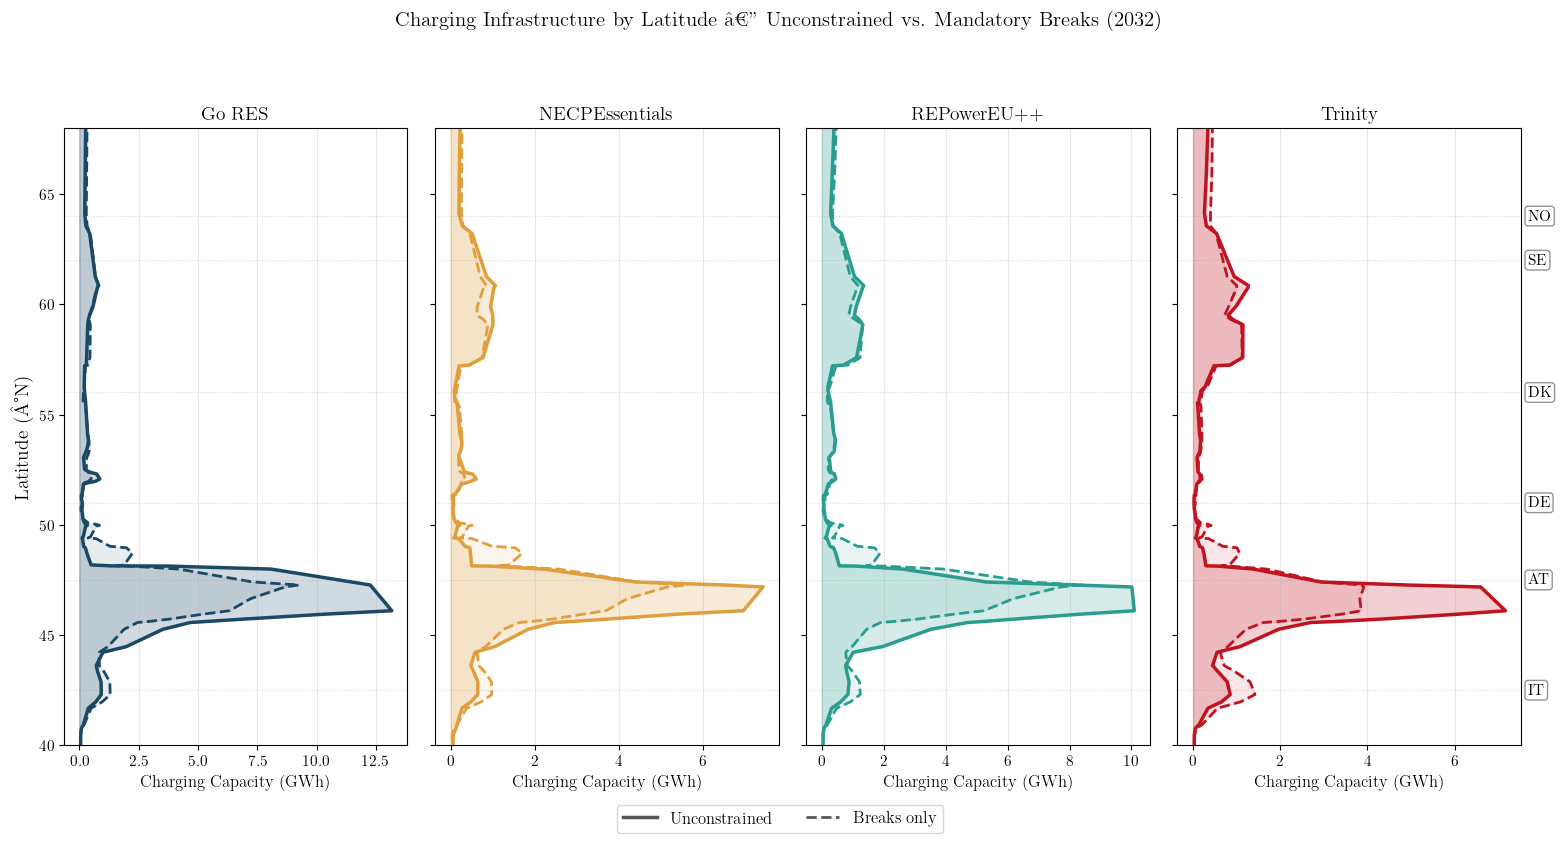

In [274]:
# Plot breaks vs unconstrained comparison for 2040
if breaks_q_results and q_results and geo_id_to_lat:
    plot_breaks_vs_unconstrained_latitude(
        q_results, breaks_q_results, geo_id_to_lat,
        target_year=2032,
        figsize=(16, 8),
        save_path=BASE_PATH / 'figures' / 'breaks_vs_unconstrained_4scenarios_2040.pdf'
    )
else:
    print("Missing data for breaks comparison")

In [275]:
# BEV fleet comparison: unconstrained vs breaks-only
print("=" * 90)
print("BEV FLEET COMPARISON: Unconstrained vs. Mandatory Breaks")
print("=" * 90)
print(f"{'Scenario':<20} {'Year':>6} {'Unconstrained':>15} {'Breaks Only':>15} {'Delta':>10} {'Rel.':>8}")
print("-" * 90)

for scenario_id in SCENARIOS:
    config = SCENARIOS[scenario_id]
    if scenario_id in results and scenario_id in breaks_results:
        fleet_unc = extract_fleet_by_year(results[scenario_id]['h'])
        fleet_brk = extract_fleet_by_year(breaks_results[scenario_id]['h'])
        for year in [2032, 2040, 2048, 2056]:
            unc = fleet_unc.get(year, 0)
            brk = fleet_brk.get(year, 0)
            delta = brk - unc
            rel = delta / unc * 100 if unc > 0 else 0
            print(f"{config['name']:<20} {year:>6} {unc:>15,.0f} {brk:>15,.0f} {delta:>+10,.0f} {rel:>+7.1f}%")
        print()

BEV FLEET COMPARISON: Unconstrained vs. Mandatory Breaks
Scenario               Year   Unconstrained     Breaks Only      Delta     Rel.
------------------------------------------------------------------------------------------
Go RES                 2032           3,096           3,096         -0    -0.0%
Go RES                 2040           6,972           6,972         -0    -0.0%
Go RES                 2048          11,979          11,979         -0    -0.0%
Go RES                 2056          15,800          16,066       +266    +1.7%

NECPEssentials         2032           1,626           1,618         -7    -0.5%
NECPEssentials         2040           5,153           5,144         -9    -0.2%
NECPEssentials         2048           9,792           9,781        -11    -0.1%
NECPEssentials         2056          13,562          13,551        -11    -0.1%

REPowerEU++            2032           2,937           2,671       -266    -9.0%
REPowerEU++            2040           6,775       

## Charging Cost Analysis (EUR/kWh)

Calculate the effective weighted average charging cost faced by fleet operators, comparing unconstrained vs. breaks-only allocation.

In [276]:
# ============================================================================
# LEVELIZED FUELING COST (EUR/kWh) — BEV Charging + Diesel Fueling
# ============================================================================
# Mirrors the objective function cost structure:
#
# BEV charging:
#   1. Energy cost:  s × 1000 × elec_price_per_kWh   (FuelCost.yaml, fuel=electricity)
#   2. Infrastructure (annual, per kW installed):
#      - O&M:     q_fuel_infr_plus × om_costs_per_kW       (FuelingInfrTypes.yaml)
#      - CAPEX:   q_fuel_infr_plus × cost_per_kW            (= 0.0 in current data)
#      - Network: q_fuel_infr_plus × network_cost_per_kW    (NetworkConnectionCosts.yaml)
#
# Diesel fueling:
#   Energy cost only: s × 1000 × diesel_price_per_kWh  (FuelCost.yaml, fuel=diesel)
#   Infrastructure assumed pre-existing (sunk cost)

import re
from collections import defaultdict

RESULT_TO_INPUT = {
    'scenario_000': 'scenario_000',  # Go RES
    'scenario_001': 'scenario_001',  # NECPEssentials
    'scenario_002': 'scenario_002',  # REPowerEU++
    'scenario_003': 'scenario_003',  # Trinity
}

INPUT_DATA_PATH = BASE_PATH / 'input_data' / 'uncertainty_scenarios'

# --- Paths to s_dict files (tuple-format keys from breaks_comparison_full) ---
S_DICT_PATHS_FOR_COST = {
    'scenario_000': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'go_res_without_breaks' / 'go_res_without_breaks_2026-01-13_16-38-24_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'go_res_with_breaks' / 'go_res_with_breaks_2026-01-13_16-29-55_s_dict.yaml',
    },
    'scenario_001': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'necp_without_breaks' / 'necp_without_breaks_2026-01-13_16-55-29_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'necp_with_breaks' / 'necp_with_breaks_2026-01-13_16-47-08_s_dict.yaml',
    },
    'scenario_002': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'repower_without_breaks' / 'repower_without_breaks_2026-01-13_17-12-34_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'repower_with_breaks' / 'repower_with_breaks_2026-01-13_17-04-08_s_dict.yaml',
    },
    'scenario_003': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'trinity_without_breaks' / 'trinity_without_breaks_2026-01-13_17-31-34_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'trinity_with_breaks' / 'trinity_with_breaks_2026-01-13_17-22-59_s_dict.yaml',
    },
}

# Regex for s_dict tuple keys: (year, (prod, odpair, path, geo), tv_id, (fuel_id, infr_type), gen)
_S_KEY_RE = re.compile(
    r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
)

# Regex for q_fuel_infr_plus keys: (year, (fuel_id, infr_type), geo_id)
_Q_KEY_RE = re.compile(
    r'\((\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
)


def load_fuel_costs_all(input_path, scenario_input_id, target_year=2040):
    """Load fuel prices for BOTH electricity and diesel from FuelCost.yaml.
    Returns: (elec_price_map, diesel_price_map)
      elec_price_map:  {(location_id, infr_type_id): EUR/kWh}
      diesel_price_map: {(location_id, infr_type_id): EUR/kWh}
    """
    fc_file = input_path / scenario_input_id / 'FuelCost.yaml'
    year_idx = target_year - 2020
    elec_map = {}
    diesel_map = {}
    if fc_file.exists():
        fc_data = load_yaml_file(fc_file)
        for entry in fc_data:
            loc = entry['location']
            infr_type = entry.get('fueling_infr_type_id', 0)
            costs = entry['cost_per_kWh']
            if year_idx >= len(costs):
                continue
            price = costs[year_idx]
            if entry.get('fuel') == 'electricity':
                elec_map[(loc, infr_type)] = price
            elif entry.get('fuel') == 'diesel':
                diesel_map[(loc, infr_type)] = price
    return elec_map, diesel_map


def load_infra_cost_params(input_path, scenario_input_id, target_year=2040):
    """Load infrastructure cost parameters from FuelingInfrTypes.yaml and NetworkConnectionCosts.yaml.
    Returns: (om_by_infr_type, capex_by_infr_type, network_by_location)
    """
    year_idx = target_year - 2020

    # FuelingInfrTypes → O&M and CAPEX per infr_type (electricity only)
    fit_file = input_path / scenario_input_id / 'FuelingInfrTypes.yaml'
    om_by_type = {}
    capex_by_type = {}
    if fit_file.exists():
        fit_data = load_yaml_file(fit_file)
        for entry in fit_data:
            if entry.get('fuel') != 'electricity':
                continue
            iid = entry['id']
            if 'om_costs' in entry and year_idx < len(entry['om_costs']):
                om_by_type[iid] = entry['om_costs'][year_idx]
            if 'cost_per_kW' in entry and year_idx < len(entry['cost_per_kW']):
                capex_by_type[iid] = entry['cost_per_kW'][year_idx]

    # NetworkConnectionCosts → network_cost_per_kW per location
    nc_file = input_path / scenario_input_id / 'NetworkConnectionCosts.yaml'
    network_by_loc = {}
    if nc_file.exists():
        nc_data = load_yaml_file(nc_file)
        for entry in nc_data:
            loc = entry['location']
            if 'network_cost_per_kW' in entry and year_idx < len(entry['network_cost_per_kW']):
                network_by_loc[loc] = entry['network_cost_per_kW'][year_idx]

    return om_by_type, capex_by_type, network_by_loc


def scan_s_by_fuel(s_file, target_year):
    """Scan s_dict, aggregate energy by (geo_id, infr_type) for BEV and diesel separately.
    BEV:    tv_id=1, fuel_id=0 (electricity)
    Diesel: tv_id=0, fuel_id=1 (diesel)
    Returns: (bev_energy, diesel_energy, bev_count, diesel_count)
    """
    bev_energy = defaultdict(float)
    diesel_energy = defaultdict(float)
    bev_count = 0
    diesel_count = 0
    with open(s_file, 'r') as f:
        for line in f:
            m = _S_KEY_RE.match(line.strip())
            if not m:
                continue
            year = int(m.group(1))
            if year != target_year:
                continue
            tv_id = int(m.group(6))
            geo_id = int(m.group(5))
            fuel_id = int(m.group(7))
            infr_type = int(m.group(8))
            val = float(line.split(':')[-1].strip().strip('"'))
            if val < 1e-8:
                continue
            if tv_id == 1 and fuel_id == 0:  # BEV + electricity
                bev_energy[(geo_id, infr_type)] += val
                bev_count += 1
            elif tv_id == 0 and fuel_id == 1:  # ICEV + diesel
                diesel_energy[(geo_id, infr_type)] += val
                diesel_count += 1
    return dict(bev_energy), dict(diesel_energy), bev_count, diesel_count


def scan_q_fuel_infr_plus(s_file, target_year):
    """Load electric charging capacity from q_fuel_infr_plus_dict.
    Key format: (year, (fuel_id, infr_type), geo_id): "value"
    Returns: {(geo_id, infr_type): capacity_kW}"""
    q_file = Path(str(s_file).replace('_s_dict.yaml', '_q_fuel_infr_plus_dict.yaml'))
    if not q_file.exists():
        print(f"  Warning: q_fuel_infr_plus not found: {q_file.name}")
        return {}
    capacity = {}
    with open(q_file, 'r') as f:
        for line in f:
            m = _Q_KEY_RE.match(line.strip())
            if not m:
                continue
            year = int(m.group(1))
            if year != target_year:
                continue
            fuel_id = int(m.group(2))
            infr_type = int(m.group(3))
            geo_id = int(m.group(4))
            if fuel_id != 0:  # electricity only
                continue
            if infr_type not in (1, 2):
                continue
            val = float(line.split(':')[-1].strip().strip('"'))
            if val > 1e-8:
                capacity[(geo_id, infr_type)] = val
    return capacity


def compute_full_fueling_cost(s_file, elec_price_map, diesel_price_map,
                              om_by_type, capex_by_type, network_by_loc,
                              target_year):
    """Compute levelized fueling costs for BEV (energy + infra) and diesel (energy only)."""
    SCALING = 1000  # model s unit → kWh

    # 1. Scan s_dict for both fuels
    bev_geo, diesel_geo, _, _ = scan_s_by_fuel(s_file, target_year)

    # 2. BEV energy cost
    bev_energy_cost = 0.0
    bev_total_energy = 0.0
    for (geo_id, infr_type), s_raw in bev_geo.items():
        energy_kwh = s_raw * SCALING
        price = elec_price_map.get((geo_id, infr_type))
        if price is None:
            continue
        bev_energy_cost += energy_kwh * price
        bev_total_energy += energy_kwh
    bev_energy_avg = bev_energy_cost / bev_total_energy if bev_total_energy > 0 else 0.0

    # 3. BEV infrastructure cost
    capacity = scan_q_fuel_infr_plus(s_file, target_year)
    total_om = 0.0
    total_capex = 0.0
    total_network = 0.0
    total_cap_kw = 0.0
    for (geo_id, infr_type), cap_kw in capacity.items():
        total_cap_kw += cap_kw
        total_om      += cap_kw * om_by_type.get(infr_type, 0.0)
        total_capex   += cap_kw * capex_by_type.get(infr_type, 0.0)
        total_network += cap_kw * network_by_loc.get(geo_id, 0.0)
    total_infra = total_om + total_capex + total_network
    bev_infra_per_kwh = total_infra / bev_total_energy if bev_total_energy > 0 else 0.0
    bev_total_avg = bev_energy_avg + bev_infra_per_kwh

    # 4. Diesel energy cost (no new infrastructure needed)
    diesel_energy_cost = 0.0
    diesel_total_energy = 0.0
    for (geo_id, infr_type), s_raw in diesel_geo.items():
        energy_kwh = s_raw * SCALING
        price = diesel_price_map.get((geo_id, infr_type))
        if price is None:
            continue
        diesel_energy_cost += energy_kwh * price
        diesel_total_energy += energy_kwh
    diesel_avg = diesel_energy_cost / diesel_total_energy if diesel_total_energy > 0 else 0.0

    return {
        'bev_energy_avg': bev_energy_avg,
        'bev_infra_per_kwh': bev_infra_per_kwh,
        'bev_total_avg': bev_total_avg,
        'bev_total_energy_gwh': bev_total_energy / 1e6,
        'bev_capacity_mw': total_cap_kw / 1000,
        'bev_om_per_kwh': total_om / bev_total_energy if bev_total_energy > 0 else 0,
        'bev_capex_per_kwh': total_capex / bev_total_energy if bev_total_energy > 0 else 0,
        'bev_network_per_kwh': total_network / bev_total_energy if bev_total_energy > 0 else 0,
        'diesel_avg': diesel_avg,
        'diesel_total_energy_gwh': diesel_total_energy / 1e6,
    }


# --- Calculate for all 4 scenarios ---
TARGET_COST_YEAR = 2032

print("=" * 140)
print(f"LEVELIZED FUELING COST COMPARISON (EUR/kWh) — Year {TARGET_COST_YEAR}")
print("BEV: energy + infrastructure (O&M + CAPEX + network)  |  Diesel: energy only (infrastructure pre-existing)")
print("=" * 140)
print(f"{'Scenario':<20}  {'── BEV Energy ──':^24}  {'── BEV Infra ──':^24}  {'── BEV Total ──':^24}  {'── Diesel ──':^24}")
print(f"{'':20}  {'unc':>10} {'brk':>10}  {'unc':>10} {'brk':>10}  {'unc':>10} {'brk':>10}  {'unc':>10} {'brk':>10}")
print("-" * 140)

cost_results_full = {}
for scenario_id, config in SCENARIOS.items():
    input_id = RESULT_TO_INPUT[scenario_id]
    elec_map, diesel_map = load_fuel_costs_all(INPUT_DATA_PATH, input_id, target_year=TARGET_COST_YEAR)
    om_by_type, capex_by_type, network_by_loc = load_infra_cost_params(
        INPUT_DATA_PATH, input_id, target_year=TARGET_COST_YEAR)

    s_paths = S_DICT_PATHS_FOR_COST.get(scenario_id, {})
    run_results = {}
    for run_type in ['unc', 'brk']:
        s_file = s_paths.get(run_type)
        if s_file is not None and s_file.exists():
            run_results[run_type] = compute_full_fueling_cost(
                s_file, elec_map, diesel_map, om_by_type, capex_by_type,
                network_by_loc, TARGET_COST_YEAR)
        else:
            print(f"  Warning: s_dict not found for {scenario_id} {run_type}")

    cost_results_full[scenario_id] = run_results
    if 'unc' in run_results and 'brk' in run_results:
        u, b = run_results['unc'], run_results['brk']
        print(f"{config['name']:<20}"
              f"  {u['bev_energy_avg']:>9.4f} {b['bev_energy_avg']:>9.4f}"
              f"   {u['bev_infra_per_kwh']:>9.4f} {b['bev_infra_per_kwh']:>9.4f}"
              f"   {u['bev_total_avg']:>9.4f} {b['bev_total_avg']:>9.4f}"
              f"   {u['diesel_avg']:>9.4f} {b['diesel_avg']:>9.4f}")

# --- Summary with deltas ---
print()
print(f"COST DELTAS (breaks − unconstrained) — Year {TARGET_COST_YEAR}")
print(f"{'Scenario':<20} {'BEV Δ(EUR/kWh)':>14} {'BEV Δ(%)':>10} {'Diesel Δ':>12} {'BEV vs Diesel':>14}")
print("-" * 80)
for scenario_id, config in SCENARIOS.items():
    r = cost_results_full.get(scenario_id, {})
    if 'unc' in r and 'brk' in r:
        u, b = r['unc'], r['brk']
        bev_delta = b['bev_total_avg'] - u['bev_total_avg']
        bev_rel = bev_delta / u['bev_total_avg'] * 100 if u['bev_total_avg'] > 0 else 0
        diesel_delta = b['diesel_avg'] - u['diesel_avg']
        # BEV vs Diesel: ratio of BEV total to diesel (>1 means BEV more expensive per kWh)
        bev_vs_diesel = u['bev_total_avg'] / u['diesel_avg'] if u['diesel_avg'] > 0 else 0
        print(f"{config['name']:<20} {bev_delta:>+13.4f} {bev_rel:>+9.2f}% {diesel_delta:>+11.4f} {bev_vs_diesel:>13.1f}x")

# --- Energy volume comparison ---
print()
print(f"ENERGY VOLUMES (GWh) — Year {TARGET_COST_YEAR}")
print(f"{'Scenario':<20} {'BEV unc':>10} {'BEV brk':>10} {'Diesel unc':>12} {'Diesel brk':>12} {'BEV Cap(MW)':>12}")
print("-" * 85)
for scenario_id, config in SCENARIOS.items():
    r = cost_results_full.get(scenario_id, {})
    if 'unc' in r and 'brk' in r:
        u, b = r['unc'], r['brk']
        print(f"{config['name']:<20}"
              f" {u['bev_total_energy_gwh']:>9.3f} {b['bev_total_energy_gwh']:>9.3f}"
              f"  {u['diesel_total_energy_gwh']:>11.3f} {b['diesel_total_energy_gwh']:>11.3f}"
              f"  {u['bev_capacity_mw']:>11.1f}")

# --- Infrastructure breakdown ---
print()
print(f"BEV INFRASTRUCTURE BREAKDOWN (EUR/kWh) — Year {TARGET_COST_YEAR}")
print(f"{'Scenario':<20} {'Run':>5} {'O&M':>10} {'CAPEX':>10} {'Network':>10} {'Total Infra':>12}")
print("-" * 75)
for scenario_id, config in SCENARIOS.items():
    for run_type in ['unc', 'brk']:
        r = cost_results_full.get(scenario_id, {}).get(run_type)
        if r:
            print(f"{config['name']:<20} {run_type:>5}"
                  f"  {r['bev_om_per_kwh']:>9.4f}"
                  f"  {r['bev_capex_per_kwh']:>9.4f}"
                  f"  {r['bev_network_per_kwh']:>9.4f}"
                  f"  {r['bev_infra_per_kwh']:>11.4f}")

# --- Combined average fueling price (BEV levelized + diesel energy-only, weighted by energy) ---
print()
print(f"COMBINED AVERAGE FUELING PRICE (EUR/kWh) — Year {TARGET_COST_YEAR}")
print("Weighted average: BEV (energy + infra) + Diesel (energy only), weighted by energy volume")
print(f"{'':<20} {'unc':>10} {'brk':>10} {'delta':>12} {'rel':>10}")
print("-" * 70)
for scenario_id, config in SCENARIOS.items():
    r = cost_results_full.get(scenario_id, {})
    if 'unc' in r and 'brk' in r:
        avgs = {}
        for rt in ['unc', 'brk']:
            d = r[rt]
            bev_e = d['bev_total_energy_gwh'] * 1e6   # back to kWh
            diesel_e = d['diesel_total_energy_gwh'] * 1e6
            total_cost = d['bev_total_avg'] * bev_e + d['diesel_avg'] * diesel_e
            total_energy = bev_e + diesel_e
            avgs[rt] = total_cost / total_energy if total_energy > 0 else 0.0
        delta = avgs['brk'] - avgs['unc']
        rel = delta / avgs['unc'] * 100 if avgs['unc'] > 0 else 0
        print(f"{config['name']:<20} {avgs['unc']:>9.4f} {avgs['brk']:>9.4f} {delta:>+11.4f} {rel:>+9.2f}%")

print()
print("Notes:")
print("  - BEV energy prices include 30% charging markup (embedded in FuelCost.yaml)")
print("  - CAPEX (cost_per_kW) = 0.0 in current data for electric charging")
print("  - Diesel infra cost excluded (pre-existing, sunk cost assumption)")
print("  - 'BEV vs Diesel' ratio compares per-kWh cost (NOT per-km — BEV is ~3x more efficient)")

LEVELIZED FUELING COST COMPARISON (EUR/kWh) — Year 2032
BEV: energy + infrastructure (O&M + CAPEX + network)  |  Diesel: energy only (infrastructure pre-existing)
Scenario                  ── BEV Energy ──          ── BEV Infra ──           ── BEV Total ──             ── Diesel ──      
                             unc        brk         unc        brk         unc        brk         unc        brk
--------------------------------------------------------------------------------------------------------------------------------------------
Go RES                   0.2036    0.2117      0.0060    0.0051      0.2096    0.2168      0.0314    0.0314
NECPEssentials           0.1801    0.1788      0.0055    0.0056      0.1856    0.1844      0.0557    0.0557
REPowerEU++              0.1721    0.1713      0.0054    0.0055      0.1775    0.1768      0.0557    0.0557
Trinity                  0.1712    0.1733      0.0052    0.0054      0.1764    0.1787      0.0624    0.0624

COST DELTAS (breaks − unc

Saved to c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\charging_cost_comparison_2040.pdf (+ .svg)


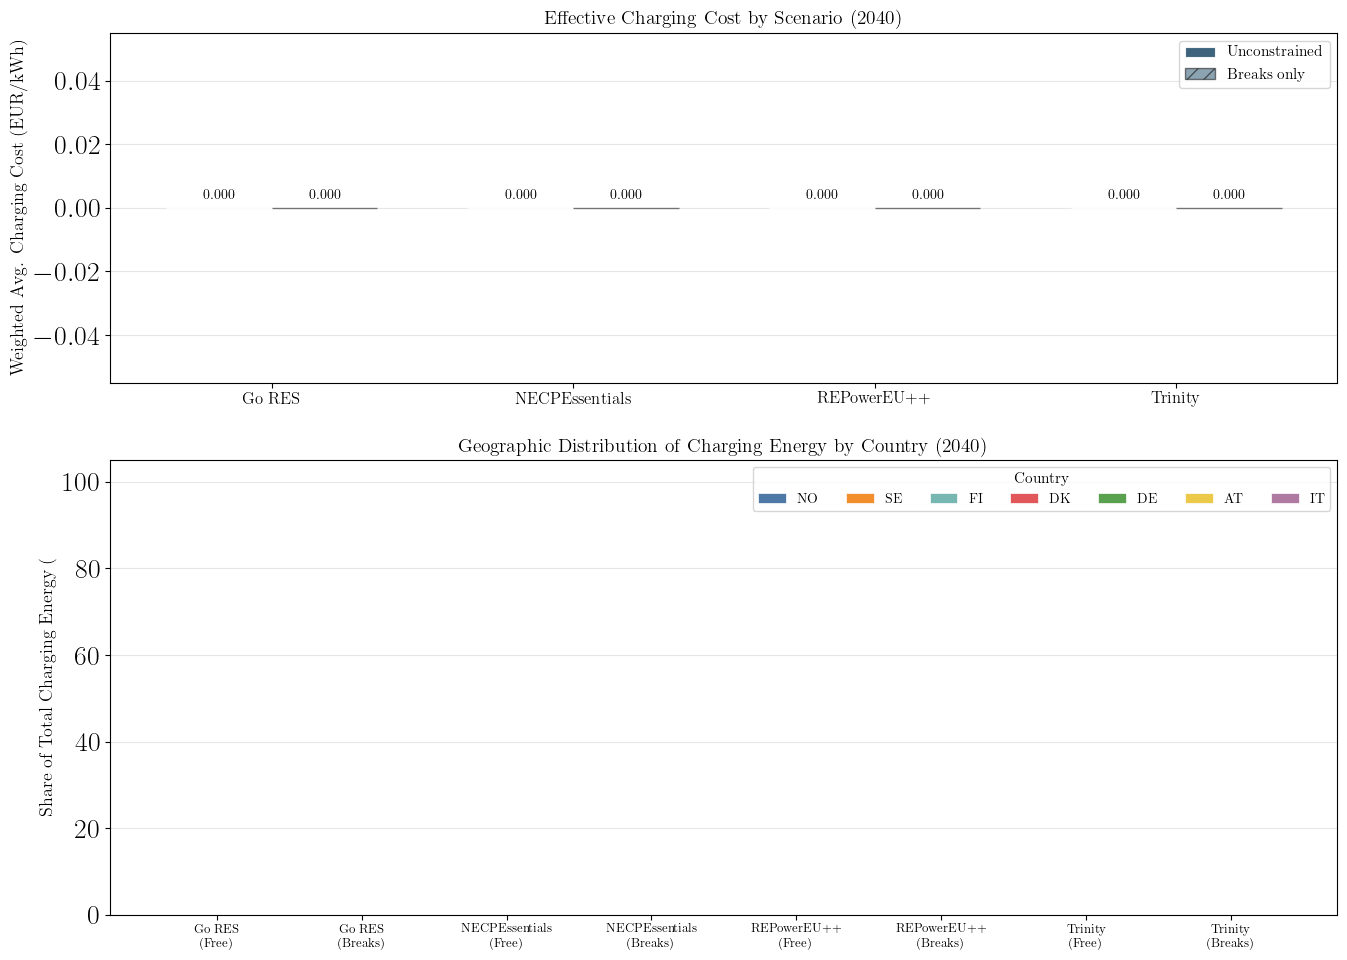

In [277]:
# Alias: cost_results_full was computed in the cell above
cost_results = cost_results_full

def plot_charging_cost_comparison(cost_results: Dict, scenarios: Dict,
                                   geoid2country: Dict,
                                   figsize: Tuple[int, int] = (16, 10),
                                   save_path: Optional[Path] = None):
    """
    Plot charging cost comparison:
      Top: grouped bar chart of weighted avg EUR/kWh per scenario (unconstrained vs breaks)
      Bottom: stacked bar showing energy-weighted average cost by country for each scenario
    """
    scenario_order = ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize, height_ratios=[1, 1.3])
    
    # === Top panel: weighted average EUR/kWh ===
    x = np.arange(len(scenario_order))
    width = 0.35
    
    unc_vals = []
    brk_vals = []
    names = []
    colors = []
    
    for sid in scenario_order:
        config = scenarios[sid]
        names.append(config['name'])
        colors.append(config['color'])
        costs = cost_results.get(sid, {})
        unc_vals.append(costs.get('unc', {}).get('avg', 0))
        brk_vals.append(costs.get('brk', {}).get('avg', 0))
    
    bars1 = ax1.bar(x - width/2, unc_vals, width, label='Unconstrained',
                    color=[c for c in colors], alpha=0.85, edgecolor='white', linewidth=0.8)
    bars2 = ax1.bar(x + width/2, brk_vals, width, label='Breaks only',
                    color=[c for c in colors], alpha=0.5, edgecolor='black',
                    linewidth=1.0, hatch='//')
    
    # Add value labels on bars
    for bar in bars1:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)
    for bar in bars2:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)
    
    ax1.set_ylabel('Weighted Avg. Charging Cost (EUR/kWh)', fontsize=13)
    ax1.set_xticks(x)
    ax1.set_xticklabels(names, fontsize=12)
    ax1.legend(fontsize=11, loc='upper right')
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_axisbelow(True)
    ax1.set_title('Effective Charging Cost by Scenario (2040)', fontsize=14, fontweight='bold')
    
    # === Bottom panel: cost by country ===
    # Aggregate energy and cost by country for each scenario+run
    country_order = ['NO', 'SE', 'FI', 'DK', 'DE', 'AT', 'IT']
    
    # Build per-country data
    bar_labels = []
    bar_colors = []
    country_data = {c: [] for c in country_order}
    
    for sid in scenario_order:
        config = scenarios[sid]
        costs = cost_results.get(sid, {})
        
        for run_type, run_label in [('unc', 'Free'), ('brk', 'Breaks')]:
            bar_labels.append(f"{config['name']}\n({run_label})")
            bar_colors.append(config['color'] if run_type == 'unc' else config['color'])
            
            by_loc = costs.get(run_type, {}).get('by_loc', {})
            total_energy = sum(d['energy'] for d in by_loc.values())
            
            for country in country_order:
                # Sum energy for all geo_ids in this country
                country_energy = sum(
                    d['energy'] for gid, d in by_loc.items()
                    if geoid2country.get(gid) == country
                )
                share = country_energy / total_energy * 100 if total_energy > 0 else 0
                country_data[country].append(share)
    
    x2 = np.arange(len(bar_labels))
    bar_width = 0.7
    
    # Stacked bar
    country_colors = {
        'NO': '#4e79a7', 'SE': '#f28e2c', 'FI': '#76b7b2',
        'DK': '#e15759', 'DE': '#59a14f', 'AT': '#edc949', 'IT': '#af7aa1'
    }
    
    bottom = np.zeros(len(bar_labels))
    for country in country_order:
        values = country_data[country]
        ax2.bar(x2, values, bar_width, bottom=bottom, label=country,
               color=country_colors[country], edgecolor='white', linewidth=0.5)
        bottom += np.array(values)
    
    # Add hatching for breaks-only bars
    for i, label in enumerate(bar_labels):
        if '(Breaks)' in label:
            ax2.patches[i].set_hatch('//')
    
    ax2.set_ylabel('Share of Total Charging Energy (%)', fontsize=13)
    ax2.set_xticks(x2)
    ax2.set_xticklabels(bar_labels, fontsize=9, rotation=0, ha='center')
    ax2.legend(title='Country', fontsize=10, title_fontsize=11,
              loc='upper right', ncol=len(country_order))
    ax2.set_title('Geographic Distribution of Charging Energy by Country (2040)', 
                  fontsize=14, fontweight='bold')
    ax2.set_ylim(0, 105)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_axisbelow(True)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
        print(f"Saved to {save_path} (+ .svg)")
    
    plt.show()

# Plot the comparison
if cost_results:
    plot_charging_cost_comparison(
        cost_results, SCENARIOS, geoid2country,
        figsize=(14, 10),
        save_path=BASE_PATH / 'figures' / 'charging_cost_comparison_2040.pdf'
    )
else:
    print("Run cell 27 first to compute cost_results")

## Route-Level Impact Analysis

Identify which OD pairs are most affected by the mandatory breaks constraint, then evaluate the cost implications for those specific routes.

In [278]:
# Per-country charging cost breakdown
print("=" * 110)
print("CHARGING COST BY COUNTRY (EUR/kWh) â€” Year 2032")
print("=" * 110)

country_order = ['NO', 'SE', 'FI', 'DK', 'DE', 'AT', 'IT']

for scenario_id in ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']:
    config = SCENARIOS[scenario_id]
    costs = cost_results.get(scenario_id, {})
    
    print(f"\n--- {config['name']} ---")
    print(f"{'Country':<8} {'Unc. EUR/kWh':>14} {'Unc. GWh':>12} {'Brk. EUR/kWh':>14} {'Brk. GWh':>12} {'Cost Delta':>12}")
    print("-" * 75)
    
    for country in country_order:
        for run_type in ['unc', 'brk']:
            by_loc = costs.get(run_type, {}).get('by_loc', {})
            # Aggregate by country
            c_energy = sum(d['energy'] for gid, d in by_loc.items() 
                          if geoid2country.get(gid) == country)
            c_cost = sum(d['cost'] for gid, d in by_loc.items()
                        if geoid2country.get(gid) == country)
            if run_type == 'unc':
                unc_e = c_energy
                unc_c = c_cost
                unc_avg = c_cost / c_energy if c_energy > 0 else 0
            else:
                brk_e = c_energy
                brk_c = c_cost
                brk_avg = c_cost / c_energy if c_energy > 0 else 0
        
        delta = brk_avg - unc_avg if unc_avg > 0 else 0
        print(f"{country:<8} {unc_avg:>14.4f} {unc_e/1e6:>11.2f} {brk_avg:>14.4f} {brk_e/1e6:>11.2f} {delta:>+11.4f}")
    
    # Total row
    unc_total = costs.get('unc', {})
    brk_total = costs.get('brk', {})
    print(f"{'TOTAL':<8} {unc_total.get('avg',0):>14.4f} {unc_total.get('total_energy',0)/1e6:>11.2f} "
          f"{brk_total.get('avg',0):>14.4f} {brk_total.get('total_energy',0)/1e6:>11.2f} "
          f"{brk_total.get('avg',0) - unc_total.get('avg',0):>+11.4f}")

CHARGING COST BY COUNTRY (EUR/kWh) â€” Year 2032

--- Go RES ---
Country    Unc. EUR/kWh     Unc. GWh   Brk. EUR/kWh     Brk. GWh   Cost Delta
---------------------------------------------------------------------------
NO               0.0000        0.00         0.0000        0.00     +0.0000
SE               0.0000        0.00         0.0000        0.00     +0.0000
FI               0.0000        0.00         0.0000        0.00     +0.0000
DK               0.0000        0.00         0.0000        0.00     +0.0000
DE               0.0000        0.00         0.0000        0.00     +0.0000
AT               0.0000        0.00         0.0000        0.00     +0.0000
IT               0.0000        0.00         0.0000        0.00     +0.0000
TOTAL            0.0000        0.00         0.0000        0.00     +0.0000

--- NECPEssentials ---
Country    Unc. EUR/kWh     Unc. GWh   Brk. EUR/kWh     Brk. GWh   Cost Delta
---------------------------------------------------------------------------
NO 

In [279]:
def compute_bev_delta_by_od(h_unc: Dict, h_brk: Dict,
                            odpair_map: Dict, geoid2country: Dict,
                            target_year: int = 2032) -> pd.DataFrame:
    """
    Compare BEV fleet by OD pair between unconstrained and breaks-only.
    Expects raw h_dict (not the full results dict).
    h_dict key format: "(year, odpair_id, tech_id, generation)" where tech_id 1 = BEV
    """
    def extract_bev_by_odpair(h_dict):
        bev = {}
        for key, value in h_dict.items():
            if isinstance(value, str):
                value = float(value)
            if value < 0.001:
                continue
            
            # Try CartesianIndex format
            parsed = parse_cartesian_index(key)
            if parsed:
                year_idx, odpair_id, tech_id, gen = parsed
                year = YEAR_MAPPING.get(year_idx, year_idx)
            elif isinstance(key, str):
                # Tuple string format: "(year, odpair_id, tech_id, generation)"
                key_clean = key.strip('()').split(',')
                if len(key_clean) < 4:
                    continue
                year = int(key_clean[0].strip())
                odpair_id = int(key_clean[1].strip())
                tech_id = int(key_clean[2].strip())
            else:
                continue
            
            if year != target_year or tech_id != 1:  # 1 = BEV
                continue
            
            bev[odpair_id] = bev.get(odpair_id, 0.0) + value
        return bev
    
    bev_unc = extract_bev_by_odpair(h_unc)
    bev_brk = extract_bev_by_odpair(h_brk)
    
    print(f"  Found {len(bev_unc)} OD pairs with BEVs (unconstrained), "
          f"{len(bev_brk)} (breaks-only)")
    
    all_odpairs = set(bev_unc.keys()) | set(bev_brk.keys())
    
    rows = []
    for odpair_id in all_odpairs:
        unc = bev_unc.get(odpair_id, 0)
        brk = bev_brk.get(odpair_id, 0)
        delta = brk - unc
        
        origin_geo, dest_geo = odpair_map.get(odpair_id, (None, None))
        origin_country = geoid2country.get(origin_geo, '?')
        dest_country = geoid2country.get(dest_geo, '?')
        
        rows.append({
            'odpair_id': odpair_id,
            'origin_geo': origin_geo,
            'dest_geo': dest_geo,
            'origin_country': origin_country,
            'dest_country': dest_country,
            'od_label': f"{origin_country}\u2192{dest_country}",
            'bev_unc': unc,
            'bev_brk': brk,
            'delta': delta,
            'abs_delta': abs(delta),
            'rel_delta': delta / unc * 100 if unc > 0.1 else 0,
        })
    
    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.sort_values('abs_delta', ascending=False)
    return df

# Compute for Go RES scenario (reference)
scenario_id = 'scenario_000'
config = SCENARIOS[scenario_id]

delta_df = compute_bev_delta_by_od(
    results[scenario_id]['h'], breaks_results[scenario_id]['h'],
    odpair_map, geoid2country, target_year=2032
)

print(f"\n=== {config['name']}: OD Pairs Most Affected by Breaks Constraint (2032) ===\n")
print(f"Total OD pairs with BEVs: {len(delta_df[delta_df['bev_unc'] > 0.1])}")
print(f"OD pairs where breaks changes BEV count: {len(delta_df[delta_df['abs_delta'] > 0.5])}")
print()

# Show top 20 most affected
top_n = 20
print(f"Top {top_n} most affected OD pairs:")
print(f"{'OD Pair':<12} {'Route':<12} {'Unc.':>8} {'Breaks':>8} {'Delta':>8} {'Rel.':>8}")
print("-" * 60)
for _, row in delta_df.head(top_n).iterrows():
    print(f"{row['od_label']:<12} {row['odpair_id']:<12} "
          f"{row['bev_unc']:>8.1f} {row['bev_brk']:>8.1f} "
          f"{row['delta']:>+8.1f} {row['rel_delta']:>+7.1f}%")

  Found 978 OD pairs with BEVs (unconstrained), 921 (breaks-only)

=== Go RES: OD Pairs Most Affected by Breaks Constraint (2032) ===

Total OD pairs with BEVs: 944
OD pairs where breaks changes BEV count: 390

Top 20 most affected OD pairs:
OD Pair      Route            Unc.   Breaks    Delta     Rel.
------------------------------------------------------------
DE→IT        879               0.0     42.1    +42.1    +0.0%
AT→IT        6                40.3      0.0    -40.3  -100.0%
IT→AT        1809             41.4     79.5    +38.1   +91.9%
DE→IT        919               0.0     34.5    +34.5    +0.0%
DE→IT        609               0.0     33.6    +33.6    +0.0%
AT→IT        3                33.6      0.0    -33.6  -100.0%
IT→DE        2139             29.9      0.0    -29.9  -100.0%
DE→IT        575               0.0     29.4    +29.4    +0.0%
DE→IT        541               0.0     29.0    +29.0    +0.0%
DE→IT        952               0.0     28.4    +28.4    +0.0%
DE→IT        92

In [280]:
# Aggregate delta by country-pair across ALL 4 scenarios
print("=" * 100)
print("BEV DELTA BY COUNTRY PAIR â€” Breaks vs. Unconstrained (2032)")
print("=" * 100)

all_deltas = {}
for scenario_id in ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']:
    config = SCENARIOS[scenario_id]
    if scenario_id not in results or scenario_id not in breaks_results:
        continue
    
    df = compute_bev_delta_by_od(
        results[scenario_id]['h'], breaks_results[scenario_id]['h'],
        odpair_map, geoid2country, target_year=2032
    )
    all_deltas[scenario_id] = df
    
    # Aggregate by country pair
    cp_agg = df.groupby('od_label').agg(
        bev_unc=('bev_unc', 'sum'),
        bev_brk=('bev_brk', 'sum'),
        delta=('delta', 'sum'),
        n_routes=('odpair_id', 'count'),
    ).sort_values('delta')
    
    print(f"\n--- {config['name']} ---")
    print(f"{'Country Pair':<12} {'N routes':>8} {'BEV Unc':>10} {'BEV Brk':>10} {'Delta':>10} {'Rel.':>8}")
    print("-" * 60)
    # Show pairs with |delta| > 1
    significant = cp_agg[cp_agg['delta'].abs() > 1]
    for od_label, row in significant.iterrows():
        rel = row['delta'] / row['bev_unc'] * 100 if row['bev_unc'] > 0 else 0
        print(f"{od_label:<12} {row['n_routes']:>8} {row['bev_unc']:>10.1f} "
              f"{row['bev_brk']:>10.1f} {row['delta']:>+10.1f} {rel:>+7.1f}%")
    
    net = cp_agg['delta'].sum()
    print(f"{'NET':<12} {'':>8} {cp_agg['bev_unc'].sum():>10.1f} "
          f"{cp_agg['bev_brk'].sum():>10.1f} {net:>+10.1f}")

BEV DELTA BY COUNTRY PAIR â€” Breaks vs. Unconstrained (2032)
  Found 978 OD pairs with BEVs (unconstrained), 921 (breaks-only)

--- Go RES ---
Country Pair N routes    BEV Unc    BEV Brk      Delta     Rel.
------------------------------------------------------------
AT→IT            40.0      346.1      170.0     -176.1   -50.9%
SE→DK            31.0       95.0       36.6      -58.4   -61.5%
IT→DE           270.0      951.6      923.0      -28.7    -3.0%
IT→DK             6.0       20.6        4.3      -16.3   -79.2%
DK→SE            36.0      144.2      136.0       -8.2    -5.7%
DK→NO            30.0      129.0      122.6       -6.4    -5.0%
NO→DK            25.0       38.8       33.5       -5.3   -13.7%
FI→SE             8.0       19.6       18.4       -1.2    -6.2%
SE→FI             8.0       91.1       94.1       +3.0    +3.3%
SE→DE            63.0       13.7       18.2       +4.5   +32.4%
DK→IT             6.0        2.3        9.2       +6.9  +303.3%
DE→NO            74.0      

<>:74: SyntaxWarning: invalid escape sequence '\D'
<>:74: SyntaxWarning: invalid escape sequence '\D'
C:\Users\simuser\AppData\Local\Temp\ipykernel_23268\3428851437.py:74: SyntaxWarning: invalid escape sequence '\D'
  plt.colorbar(im, ax=ax, shrink=0.8, label='$\Delta$ BEV fleet')


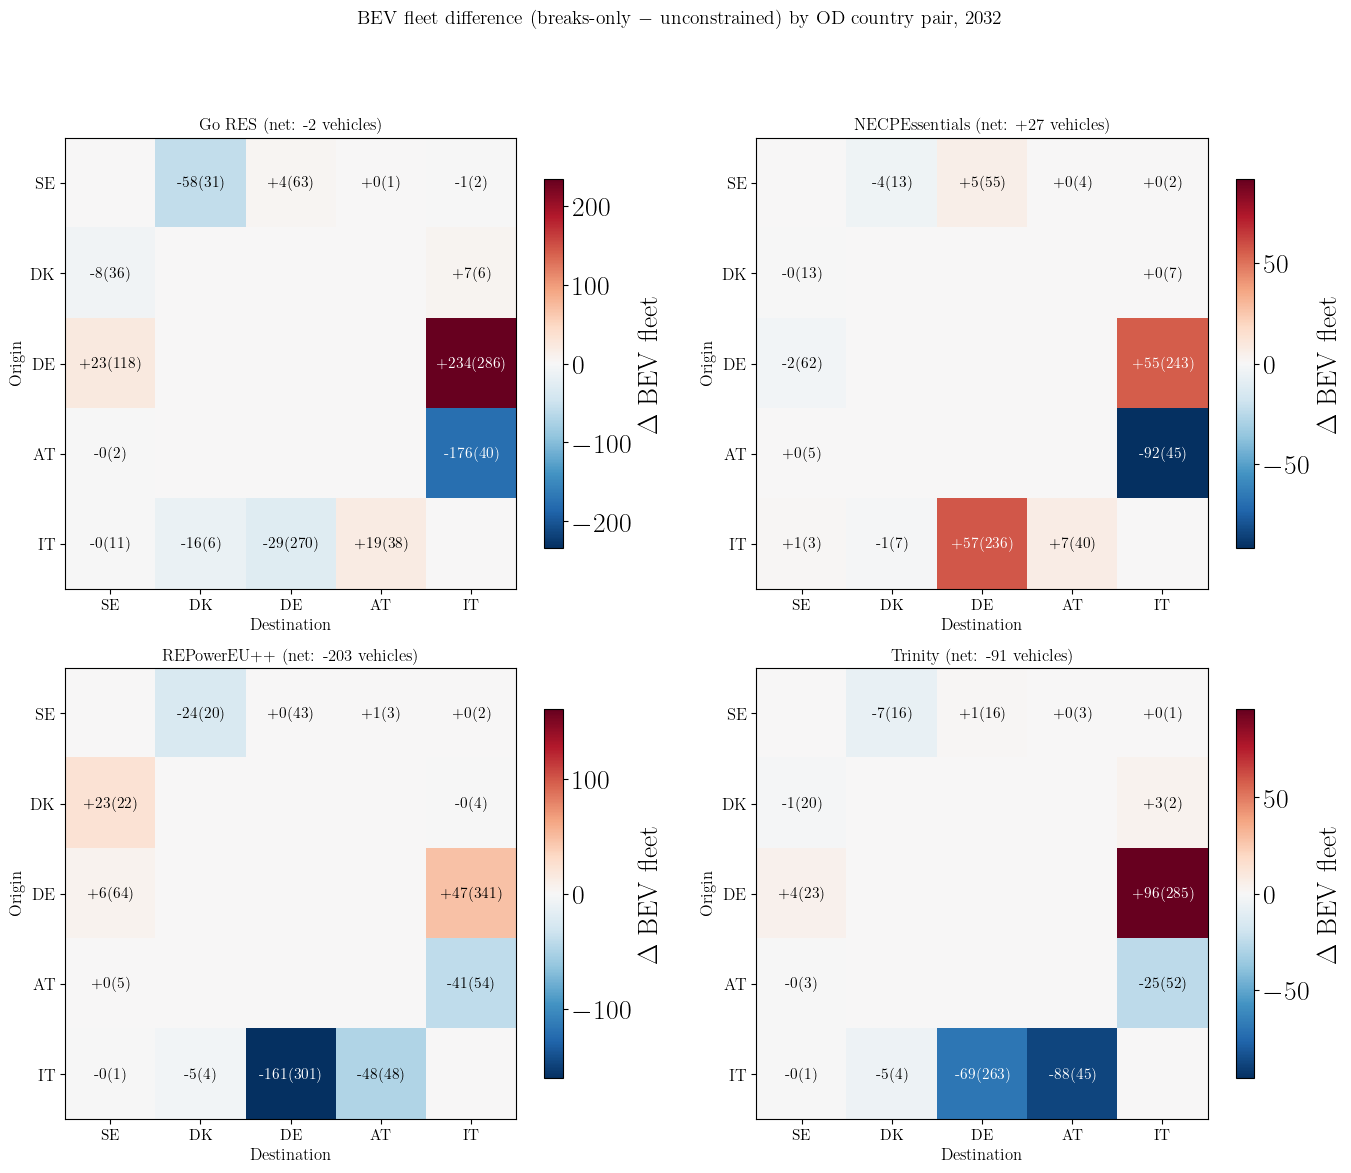

Saved to figures/bev_od_matrix_delta_4scenarios_2032.pdf


In [281]:
# ============================================================================
# OD Matrix Heatmap: BEV fleet delta (Breaks - Unconstrained) by country pair
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Country ordering along the corridor (north → south)
COUNTRY_ORDER = ['SE', 'DK', 'DE', 'AT', 'IT']

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('BEV fleet difference (breaks-only − unconstrained) by OD country pair, 2032',
             fontsize=14, fontweight='bold', y=0.98)

for idx, scenario_id in enumerate(['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']):
    ax = axes[idx // 2, idx % 2]
    config = SCENARIOS[scenario_id]
    
    if scenario_id not in all_deltas or all_deltas[scenario_id].empty:
        ax.set_title(f"{config['name']} — no data")
        ax.axis('off')
        continue
    
    df = all_deltas[scenario_id].copy()
    
    # Aggregate delta by (origin_country, dest_country)
    pair_agg = df.groupby(['origin_country', 'dest_country']).agg(
        delta=('delta', 'sum'),
        bev_unc=('bev_unc', 'sum'),
        n_routes=('odpair_id', 'count'),
    ).reset_index()
    
    # Build matrix
    countries = [c for c in COUNTRY_ORDER if c in set(pair_agg['origin_country']) | set(pair_agg['dest_country'])]
    n = len(countries)
    matrix = np.zeros((n, n))
    count_matrix = np.zeros((n, n), dtype=int)
    
    c2i = {c: i for i, c in enumerate(countries)}
    for _, row in pair_agg.iterrows():
        oi = c2i.get(row['origin_country'])
        di = c2i.get(row['dest_country'])
        if oi is not None and di is not None:
            matrix[oi, di] = row['delta']
            count_matrix[oi, di] = int(row['n_routes'])
    
    # Symmetric color scale
    vmax = max(abs(matrix.min()), abs(matrix.max()), 1)
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    
    im = ax.imshow(matrix, cmap='RdBu_r', norm=norm, aspect='equal')
    
    # Labels
    ax.set_xticks(range(n))
    ax.set_xticklabels(countries, fontsize=11)
    ax.set_yticks(range(n))
    ax.set_yticklabels(countries, fontsize=12)
    ax.set_xlabel('Destination', fontsize=12)
    ax.set_ylabel('Origin', fontsize=12)
    
    # Annotate each cell with delta value and route count
    for i in range(n):
        for j in range(n):
            val = matrix[i, j]
            cnt = count_matrix[i, j]
            if cnt == 0:
                continue
            color = 'white' if abs(val) > vmax * 0.6 else 'black'
            ax.text(j, i, f"{val:+.0f}({cnt})",
                    ha='center', va='center', fontsize=11, fontweight='bold', color=color)
    
    net_delta = matrix.sum()
    ax.set_title(f"{config['name']}  (net: {net_delta:+.0f} vehicles)", fontsize=12, fontweight='bold')
    plt.colorbar(im, ax=ax, shrink=0.8, label='$\Delta$ BEV fleet')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(BASE_PATH / 'figures' / 'bev_od_matrix_delta_4scenarios_2032.pdf', bbox_inches='tight', dpi=150)
plt.savefig(BASE_PATH / 'figures' / 'bev_od_matrix_delta_4scenarios_2032.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved to figures/bev_od_matrix_delta_4scenarios_2032.pdf")


In [282]:
# ============================================================================
# Route-level effective charging cost using s variable (per-route energy)
# ============================================================================
# Uses s_dict from breaks_comparison_full which has proper tuple keys:
#   (year, (prod, odpair, path, geo), tv_id, (fuel_id, infr_type), gen): energy

import re
from collections import defaultdict

# --- BEV specific consumption (kWh/km) by year ---
SPEC_CONS_BY_YEAR = {2028: 1.75, 2032: 1.60, 2036: 1.44, 2040: 1.29, 2044: 1.25, 2048: 1.21}

# --- Paths to s_dict files with proper tuple-format keys ---
S_DICT_PATHS = {
    'scenario_000': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'go_res_without_breaks' / 'go_res_without_breaks_2026-01-13_16-38-24_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'go_res_with_breaks' / 'go_res_with_breaks_2026-01-13_16-29-55_s_dict.yaml',
    },
    'scenario_001': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'necp_without_breaks' / 'necp_without_breaks_2026-01-13_16-55-29_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'necp_with_breaks' / 'necp_with_breaks_2026-01-13_16-47-08_s_dict.yaml',
    },
    'scenario_002': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'repower_without_breaks' / 'repower_without_breaks_2026-01-13_17-12-34_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'repower_with_breaks' / 'repower_with_breaks_2026-01-13_17-04-08_s_dict.yaml',
    },
    'scenario_003': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'trinity_without_breaks' / 'trinity_without_breaks_2026-01-13_17-31-34_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'trinity_with_breaks' / 'trinity_with_breaks_2026-01-13_17-22-59_s_dict.yaml',
    },
}

S_KEY_PATTERN = re.compile(
    r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
)

def scan_s_dict_for_routes(s_file: Path, target_odpairs: set,
                           target_years: list = None) -> Dict[int, Dict[int, Dict[int, float]]]:
    """Scan s_dict line-by-line, extract per-route energy at each geo node.
    Filters for electricity (fuel_id > 0), aggregates across generations + infr types.
    Returns: {year: {odpair_id: {geo_id: total_energy}}}"""
    if target_years is None:
        target_years = [2032]
    target_years_set = set(target_years)
    result = {y: defaultdict(lambda: defaultdict(float)) for y in target_years}
    with open(s_file, 'r') as f:
        for line in f:
            m = S_KEY_PATTERN.match(line.strip())
            if not m:
                continue
            year, odpair, geo, fuel_id = int(m.group(1)), int(m.group(3)), int(m.group(5)), int(m.group(7))
            if year not in target_years_set or odpair not in target_odpairs or fuel_id == 0:
                continue
            val = float(line.split(':')[-1].strip().strip('"'))
            if val > 1e-6:
                result[year][odpair][geo] += val
    return {y: dict(d) for y, d in result.items()}

def compute_route_effective_cost_from_s(route_energy: Dict[int, float],
                                         price_map: Dict, geoid2country: Dict):
    """effective_cost = sum(local_price * energy_at_node) / sum(energy_at_node)"""
    SCALING = 1000
    total_cost, total_energy = 0.0, 0.0
    for geo_id, energy_mwh in route_energy.items():
        energy_kwh = energy_mwh * SCALING
        price = max(price_map.get((geo_id, 1), 0), price_map.get((geo_id, 2), 0))
        total_cost += price * energy_kwh
        total_energy += energy_kwh
    avg = total_cost / total_energy if total_energy > 0 else 0
    return avg, total_energy

# --- Load path + odpair data ---
def load_path_sequences(base_path: Path) -> Dict[int, dict]:
    path_file = base_path / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'Path.yaml'
    path_seqs = {}
    if path_file.exists():
        for entry in load_yaml_file(path_file):
            path_seqs[entry['id']] = {'sequence': entry['sequence'], 'length': entry.get('length', 0)}
    return path_seqs

def load_odpair_path_mapping(base_path: Path) -> Dict[int, int]:
    od_file = base_path / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'Odpair.yaml'
    od_to_path = {}
    if od_file.exists():
        for entry in load_yaml_file(od_file):
            od_to_path[entry['id']] = entry['path_id']
    return od_to_path

path_seqs = load_path_sequences(BASE_PATH)
od_to_path = load_odpair_path_mapping(BASE_PATH)
print(f"Loaded {len(path_seqs)} paths, {len(od_to_path)} odpair->path mappings")

# --- Compute for Go RES, years 2032 and 2040 ---
ref_sid = 'scenario_000'
ref_input_id = RESULT_TO_INPUT[ref_sid]
TARGET_YEARS = [2032, 2040]

# Load prices for each year
price_maps = {}
for yr in TARGET_YEARS:
    price_maps[yr] = load_fuel_costs(INPUT_DATA_PATH, ref_input_id, target_year=yr)

# Get ALL odpairs
all_odpair_ids = set(od_to_path.keys())

print(f"\nScanning s_dict for all {len(all_odpair_ids)} routes, years {TARGET_YEARS}...")
s_paths = S_DICT_PATHS[ref_sid]
energy_unc_by_year = scan_s_dict_for_routes(s_paths['unc'], all_odpair_ids, TARGET_YEARS)
energy_brk_by_year = scan_s_dict_for_routes(s_paths['brk'], all_odpair_ids, TARGET_YEARS)

for yr in TARGET_YEARS:
    n_unc = len(energy_unc_by_year.get(yr, {}))
    n_brk = len(energy_brk_by_year.get(yr, {}))
    print(f"  Year {yr}: unc={n_unc} routes, brk={n_brk} routes")

# --- Display for each year ---
for yr in TARGET_YEARS:
    price_map = price_maps[yr]
    e_unc_all = energy_unc_by_year.get(yr, {})
    e_brk_all = energy_brk_by_year.get(yr, {})
    spec_cons = SPEC_CONS_BY_YEAR.get(yr, 1.4)  # kWh/km
    
    # Compute effective cost for ALL routes that have data in both runs
    route_costs = []
    for od_id in set(list(e_unc_all.keys()) + list(e_brk_all.keys())):
        e_unc = e_unc_all.get(od_id, {})
        e_brk = e_brk_all.get(od_id, {})
        avg_unc, tot_unc = compute_route_effective_cost_from_s(e_unc, price_map, geoid2country)
        avg_brk, tot_brk = compute_route_effective_cost_from_s(e_brk, price_map, geoid2country)
        delta = avg_brk - avg_unc if avg_unc > 0 and avg_brk > 0 else 0
        route_costs.append({
            'odpair_id': od_id, 'avg_unc': avg_unc, 'avg_brk': avg_brk,
            'delta_price': delta, 'tot_unc': tot_unc, 'tot_brk': tot_brk,
        })
    
    df_costs = pd.DataFrame(route_costs)
    if df_costs.empty:
        print(f"\n--- Year {yr}: no data ---")
        continue
    
    # Filter to routes with data in both runs
    df_both = df_costs[(df_costs['avg_unc'] > 0) & (df_costs['avg_brk'] > 0)].copy()
    df_both['abs_delta'] = df_both['delta_price'].abs()
    df_both = df_both.sort_values('abs_delta', ascending=False)
    
    print(f"\n{'='*140}")
    print(f"YEAR {yr} - {SCENARIOS[ref_sid]['name']} - Effective EUR/kWh from s variable  |  spec_cons = {spec_cons} kWh/km")
    print(f"{'='*140}")
    print(f"Routes with data in both runs: {len(df_both)}")
    print(f"Mean effective EUR/kWh  unc: {df_both['avg_unc'].mean():.4f}  brk: {df_both['avg_brk'].mean():.4f}  "
          f"delta: {df_both['delta_price'].mean():+.4f}")
    print(f"Median delta: {df_both['delta_price'].median():+.4f}")
    print()
    
    header = (f"{'OD':>6}  {'Route':<20} {'Length':>7} {'EUR/kWh unc':>12} {'EUR/kWh brk':>12} "
              f"{'delta':>10} {'delta %':>8} {'EUR/trip unc':>13} {'EUR/trip brk':>13} {'cost delta':>11}")
    print(header)
    print("-" * len(header))
    for _, row in df_both.head(15).iterrows():
        od_id = int(row['odpair_id'])
        path_id = od_to_path.get(od_id)
        if path_id and path_id in path_seqs:
            path_info = path_seqs[path_id]
            countries = '->'.join(dict.fromkeys(geoid2country.get(g, '?') for g in path_info['sequence']))
            length = path_info['length']
        else:
            countries = '?'
            length = 0
        # EUR/trip = route_length_km * spec_cons_kWh_per_km * effective_EUR_per_kWh
        energy_per_trip = length * spec_cons  # kWh
        cost_unc = energy_per_trip * row['avg_unc']
        cost_brk = energy_per_trip * row['avg_brk']
        cost_delta = cost_brk - cost_unc
        delta_pct = (row['delta_price'] / row['avg_unc'] * 100) if row['avg_unc'] > 0 else 0
        print(f"{od_id:>6}  {countries:<20} {length:>6.0f}km {row['avg_unc']:>11.4f} {row['avg_brk']:>11.4f} "
              f"{row['delta_price']:>+9.4f} {delta_pct:>+7.1f}% {cost_unc:>12.2f}€ {cost_brk:>12.2f}€ {cost_delta:>+10.2f}€")

# Keep df_top10 for cell 34 visualization (year 2032)
yr_viz = 2032
e_unc_viz = energy_unc_by_year.get(yr_viz, {})
e_brk_viz = energy_brk_by_year.get(yr_viz, {})
price_viz = price_maps[yr_viz]

# Use delta_df from cell 31 for top routes, but recompute with s-based costs
top10 = delta_df.head(10).copy()
top10_data = []
for _, row in top10.iterrows():
    odpair_id = row['odpair_id']
    path_id = od_to_path.get(odpair_id)
    if path_id is None or path_id not in path_seqs:
        continue
    path_info = path_seqs[path_id]
    countries = ' -> '.join(dict.fromkeys(geoid2country.get(g, '?') for g in path_info['sequence']))
    avg_unc, _ = compute_route_effective_cost_from_s(e_unc_viz.get(odpair_id, {}), price_viz, geoid2country)
    avg_brk, _ = compute_route_effective_cost_from_s(e_brk_viz.get(odpair_id, {}), price_viz, geoid2country)
    delta_price = avg_brk - avg_unc if avg_unc > 0 and avg_brk > 0 else 0
    top10_data.append({
        'label': f"{row['od_label']}\n({path_info['length']:.0f}km)",
        'odpair_id': odpair_id, 'od_label': row['od_label'],
        'delta_bev': row['delta'], 'bev_unc': row['bev_unc'], 'bev_brk': row['bev_brk'],
        'avg_unc': avg_unc, 'avg_brk': avg_brk, 'delta_price': delta_price,
        'countries': countries, 'length': path_info['length'],
    })
df_top10 = pd.DataFrame(top10_data)
print(f"\nPrepared {len(df_top10)} routes for visualization (year {yr_viz})")

Loaded 2244 paths, 2244 odpair->path mappings


NameError: name 'load_fuel_costs' is not defined

In [284]:
# Visualize top 10 routes: BEV delta + effective charging cost comparison
if df_top10.empty:
    print("No data â€” run previous cell first")
else:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), height_ratios=[1, 1])
    
    x = np.arange(len(df_top10))
    width = 0.35
    
    # --- Top: BEV fleet comparison ---
    ax1.bar(x - width/2, df_top10['bev_unc'], width, label='Unconstrained',
            color='#335c67', alpha=0.85, edgecolor='white')
    ax1.bar(x + width/2, df_top10['bev_brk'], width, label='Breaks only',
            color='#335c67', alpha=0.45, edgecolor='black', hatch='//')
    
    for i, row in df_top10.iterrows():
        y_pos = max(row['bev_unc'], row['bev_brk']) + 0.5
        ax1.text(i, y_pos, f"{row['delta_bev']:+.1f}", ha='center', va='bottom',
                fontsize=9, fontweight='bold',
                color='#c1121f' if row['delta_bev'] < 0 else '#2d6a4f')
    
    ax1.set_ylabel('BEV Fleet (vehicles)', fontsize=12)
    ax1.set_xticks(x)
    ax1.set_xticklabels(df_top10['label'], fontsize=9)
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_axisbelow(True)
    ax1.set_title(f'{SCENARIOS[ref_sid]["name"]}: Top 10 Most Affected Routes â€” BEV Fleet (2040)',
                  fontsize=14, fontweight='bold')
    
    # --- Bottom: Effective EUR/kWh (unconstrained vs breaks) ---
    ax2.bar(x - width/2, df_top10['avg_unc'], width, label='Unconstrained',
            color='#e09f3e', alpha=0.85, edgecolor='white')
    ax2.bar(x + width/2, df_top10['avg_brk'], width, label='Breaks only',
            color='#e09f3e', alpha=0.45, edgecolor='black', hatch='//')
    
    # Value labels
    for i, row in df_top10.iterrows():
        ax2.text(i - width/2, row['avg_unc'] + 0.003, f"{row['avg_unc']:.3f}",
                ha='center', va='bottom', fontsize=8)
        ax2.text(i + width/2, row['avg_brk'] + 0.003, f"{row['avg_brk']:.3f}",
                ha='center', va='bottom', fontsize=8)
    
    # Delta label between the bars
    for i, row in df_top10.iterrows():
        mid_y = max(row['avg_unc'], row['avg_brk']) + 0.015
        ax2.text(i, mid_y, f"Î”{row['delta_price']:+.4f}",
                ha='center', va='bottom', fontsize=8, fontweight='bold',
                color='#c1121f' if row['delta_price'] > 0 else '#2d6a4f')
    
    ax2.set_ylabel('Effective Charging Cost\n(EUR/kWh)', fontsize=12)
    ax2.set_xticks(x)
    ax2.set_xticklabels(df_top10['label'], fontsize=9)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_axisbelow(True)
    ax2.set_title('Effective Charging Cost Along Route Path\n'
                  'Î£(local_price Ã— energy_at_node) / Î£(energy_at_node)',
                  fontsize=13, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(BASE_PATH / 'figures' / 'top10_affected_routes_cost_2040.pdf',
                bbox_inches='tight', dpi=300)
    plt.savefig(BASE_PATH / 'figures' / 'top10_affected_routes_cost_2040.svg',
                bbox_inches='tight')
    print("Saved to figures/top10_affected_routes_cost_2040.pdf (+ .svg)")
    plt.show()

NameError: name 'df_top10' is not defined

In [285]:
# ============================================================
# Vehicle Investment Cost Analysis: h_plus * capital_cost
# Comparing unconstrained vs breaks-only charging
# ============================================================

# --- Load TechVehicle capital costs ---
tv_yaml_path = BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'TechVehicle.yaml'
tv_data = load_yaml_file(tv_yaml_path)

# capital_cost arrays: 41 entries (annual, 2020-2060)
# Python index = year - 2020
capex_by_tv = {}
for tv in tv_data:
    capex_by_tv[tv['id']] = {
        'name': tv['name'],
        'capital_cost': tv['capital_cost'],  # list, index = year - 2020
    }

print('TechVehicle CAPEX (selected years):')
for tv_id, info in capex_by_tv.items():
    cc = info['capital_cost']
    print(f"  {info['name']} (id={tv_id}):")
    for y in [2020, 2032, 2040, 2048, 2060]:
        idx = y - 2020
        print(f"    {y}: {cc[idx]:>12,.0f} EUR")

# --- Parse h_plus key: (year, odpair_id, tv_id, generation) ---
_HPLUS_KEY_RE = re.compile(
    r'\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\)'
)

def parse_h_plus_dict(raw_dict):
    """Parse h_plus_dict YAML into {(year, odpair_id, tv_id, gen): n_vehicles}."""
    parsed = {}
    for k, v in raw_dict.items():
        m = _HPLUS_KEY_RE.match(str(k))
        if m:
            year, od_id, tv_id, gen = int(m.group(1)), int(m.group(2)), int(m.group(3)), int(m.group(4))
            parsed[(year, od_id, tv_id, gen)] = float(v)
    return parsed


def compute_vehicle_investment(h_plus_parsed, capex_by_tv):
    """
    Compute vehicle investment cost = sum of h_plus * capital_cost.
    Returns: {year: {tv_id: total_cost_EUR}}
    """
    result = {}
    for (year, od_id, tv_id, gen), n_vehicles in h_plus_parsed.items():
        if gen != year:
            continue  # CAPEX only in purchase year
        if tv_id not in capex_by_tv:
            continue
        cc_array = capex_by_tv[tv_id]['capital_cost']
        idx = year - 2020
        if idx < 0 or idx >= len(cc_array):
            continue
        cost = n_vehicles * cc_array[idx]
        
        if year not in result:
            result[year] = {}
        result[year][tv_id] = result[year].get(tv_id, 0.0) + cost
    return result


# --- Load h_plus for all scenarios (unc + brk) ---
investment_unc = {}
investment_brk = {}

for scenario_id, config in SCENARIOS.items():
    # Unconstrained
    unc_folder = RESULTS_PATH / scenario_id
    h_plus_file = find_latest_result_file(unc_folder, 'h_plus')
    if h_plus_file:
        raw = load_yaml_file(h_plus_file)
        parsed = parse_h_plus_dict(raw)
        investment_unc[scenario_id] = compute_vehicle_investment(parsed, capex_by_tv)
        print(f"Loaded UNC h_plus for {config['name']}: {len(parsed):,} entries")
    
    # Breaks-only
    brk_folder = BREAKS_PATH / scenario_id
    h_plus_file_brk = find_latest_result_file(brk_folder, 'h_plus')
    if h_plus_file_brk:
        raw_brk = load_yaml_file(h_plus_file_brk)
        parsed_brk = parse_h_plus_dict(raw_brk)
        investment_brk[scenario_id] = compute_vehicle_investment(parsed_brk, capex_by_tv)
        print(f"Loaded BRK h_plus for {config['name']}: {len(parsed_brk):,} entries")

# --- Summary table ---
MODEL_YEARS = sorted(set(y for inv in investment_unc.values() for y in inv))
tv_names = {tv_id: info['name'] for tv_id, info in capex_by_tv.items()}

print('\n' + '=' * 120)
print('VEHICLE INVESTMENT COST (h_plus × capital_cost) — Unconstrained vs Breaks-only')
print('=' * 120)

for scenario_id, config in SCENARIOS.items():
    if scenario_id not in investment_unc or scenario_id not in investment_brk:
        continue
    inv_u = investment_unc[scenario_id]
    inv_b = investment_brk[scenario_id]
    
    print(f"\n--- {config['name']} ({scenario_id}) ---")
    print(f"{'Year':<6}  {'ICEV unc (MEUR)':>16} {'ICEV brk':>12} {'Δ ICEV':>10}  "
          f"{'BEV unc (MEUR)':>16} {'BEV brk':>12} {'Δ BEV':>10}  "
          f"{'Total unc':>12} {'Total brk':>12} {'Δ Total':>10} {'Δ%':>7}")
    print('-' * 140)
    
    cum_u = {'icev': 0, 'bev': 0}
    cum_b = {'icev': 0, 'bev': 0}
    
    for y in MODEL_YEARS:
        icev_u = inv_u.get(y, {}).get(0, 0.0)
        icev_b = inv_b.get(y, {}).get(0, 0.0)
        bev_u  = inv_u.get(y, {}).get(1, 0.0)
        bev_b  = inv_b.get(y, {}).get(1, 0.0)
        total_u = icev_u + bev_u
        total_b = icev_b + bev_b
        d_icev = icev_b - icev_u
        d_bev  = bev_b - bev_u
        d_total = total_b - total_u
        d_pct = d_total / total_u * 100 if total_u > 0 else 0
        
        cum_u['icev'] += icev_u
        cum_u['bev'] += bev_u
        cum_b['icev'] += icev_b
        cum_b['bev'] += bev_b
        
        print(f"{y:<6}  {icev_u/1e6:>16.2f} {icev_b/1e6:>12.2f} {d_icev/1e6:>+10.2f}  "
              f"{bev_u/1e6:>16.2f} {bev_b/1e6:>12.2f} {d_bev/1e6:>+10.2f}  "
              f"{total_u/1e6:>12.2f} {total_b/1e6:>12.2f} {d_total/1e6:>+10.2f} {d_pct:>+6.2f}%")
    
    # Cumulative totals
    cum_total_u = cum_u['icev'] + cum_u['bev']
    cum_total_b = cum_b['icev'] + cum_b['bev']
    d_cum = cum_total_b - cum_total_u
    d_cum_pct = d_cum / cum_total_u * 100 if cum_total_u > 0 else 0
    print(f"{'TOTAL':<6}  {cum_u['icev']/1e6:>16.2f} {cum_b['icev']/1e6:>12.2f} "
          f"{(cum_b['icev']-cum_u['icev'])/1e6:>+10.2f}  "
          f"{cum_u['bev']/1e6:>16.2f} {cum_b['bev']/1e6:>12.2f} "
          f"{(cum_b['bev']-cum_u['bev'])/1e6:>+10.2f}  "
          f"{cum_total_u/1e6:>12.2f} {cum_total_b/1e6:>12.2f} "
          f"{d_cum/1e6:>+10.2f} {d_cum_pct:>+6.2f}%")

# --- Cross-scenario comparison summary ---
print('\n' + '=' * 100)
print('CROSS-SCENARIO SUMMARY: Cumulative vehicle investment (MEUR)')
print('=' * 100)
print(f"{'Scenario':<18} {'ICEV unc':>12} {'ICEV brk':>12} {'BEV unc':>12} {'BEV brk':>12} "
      f"{'Total unc':>12} {'Total brk':>12} {'Δ Total':>10} {'Δ%':>7}")
print('-' * 110)

for scenario_id, config in SCENARIOS.items():
    if scenario_id not in investment_unc or scenario_id not in investment_brk:
        continue
    inv_u = investment_unc[scenario_id]
    inv_b = investment_brk[scenario_id]
    
    icev_u = sum(inv_u.get(y, {}).get(0, 0.0) for y in MODEL_YEARS) / 1e6
    icev_b = sum(inv_b.get(y, {}).get(0, 0.0) for y in MODEL_YEARS) / 1e6
    bev_u  = sum(inv_u.get(y, {}).get(1, 0.0) for y in MODEL_YEARS) / 1e6
    bev_b  = sum(inv_b.get(y, {}).get(1, 0.0) for y in MODEL_YEARS) / 1e6
    total_u = icev_u + bev_u
    total_b = icev_b + bev_b
    d = total_b - total_u
    d_pct = d / total_u * 100 if total_u > 0 else 0
    
    print(f"{config['name']:<18} {icev_u:>12.1f} {icev_b:>12.1f} {bev_u:>12.1f} {bev_b:>12.1f} "
          f"{total_u:>12.1f} {total_b:>12.1f} {d:>+10.1f} {d_pct:>+6.2f}%")

TechVehicle CAPEX (selected years):
  ICEV (id=0):
    2020:      169,143 EUR
    2032:      192,000 EUR
    2040:      192,000 EUR
    2048:      192,000 EUR
    2060:      192,000 EUR
  BEV (id=1):
    2020:      550,429 EUR
    2032:      234,800 EUR
    2040:      218,000 EUR
    2048:      218,000 EUR
    2060:      218,000 EUR
Loaded UNC h_plus for Go RES: 23,671 entries
Loaded BRK h_plus for Go RES: 23,766 entries
Loaded UNC h_plus for NECPEssentials: 22,635 entries
Loaded BRK h_plus for NECPEssentials: 22,571 entries
Loaded UNC h_plus for REPowerEU++: 23,481 entries
Loaded BRK h_plus for REPowerEU++: 23,281 entries
Loaded UNC h_plus for Trinity: 22,936 entries
Loaded BRK h_plus for Trinity: 22,851 entries

VEHICLE INVESTMENT COST (h_plus × capital_cost) — Unconstrained vs Breaks-only

--- Go RES (scenario_000) ---
Year     ICEV unc (MEUR)     ICEV brk     Δ ICEV    BEV unc (MEUR)      BEV brk      Δ BEV     Total unc    Total brk    Δ Total      Δ%
-----------------------------

all_investment built:
  Go RES: unc=9,021 MEUR, brk=9,068 MEUR
  NECPEssentials: unc=8,599 MEUR, brk=8,597 MEUR
  REPowerEU++: unc=8,950 MEUR, brk=8,854 MEUR
  Trinity: unc=8,584 MEUR, brk=8,570 MEUR


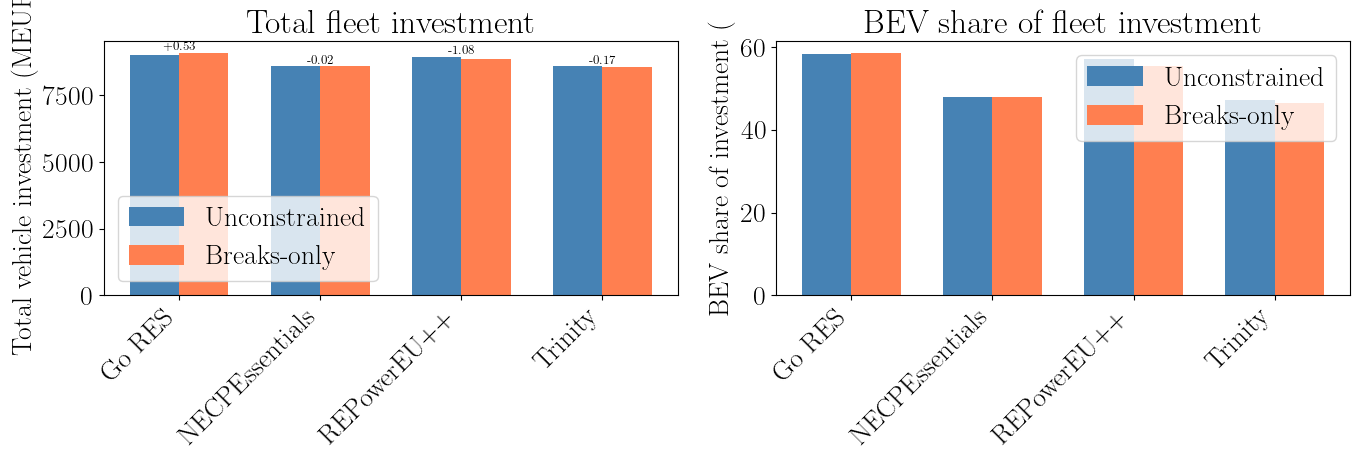

Saved to figures/vehicle_investment_unc_vs_brk.pdf (+ .png)


In [286]:
# ============================================================
# VISUALIZATION: Vehicle investment comparison (UNC vs BRK)
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# Build all_investment dict from investment_unc / investment_brk
# Structure: all_investment[scenario_id]['unc'/'brk']['total'/'bev'/'icev']
all_investment = {}
for scenario_id in SCENARIOS:
    all_investment[scenario_id] = {'unc': {'total': 0, 'bev': 0, 'icev': 0},
                                    'brk': {'total': 0, 'bev': 0, 'icev': 0}}
    # Unconstrained
    if scenario_id in investment_unc:
        for year, tv_costs in investment_unc[scenario_id].items():
            for tv_id, cost in tv_costs.items():
                all_investment[scenario_id]['unc']['total'] += cost
                if tv_id == 1:  # BEV
                    all_investment[scenario_id]['unc']['bev'] += cost
                else:
                    all_investment[scenario_id]['unc']['icev'] += cost
    # Breaks-only
    if scenario_id in investment_brk:
        for year, tv_costs in investment_brk[scenario_id].items():
            for tv_id, cost in tv_costs.items():
                all_investment[scenario_id]['brk']['total'] += cost
                if tv_id == 1:  # BEV
                    all_investment[scenario_id]['brk']['bev'] += cost
                else:
                    all_investment[scenario_id]['brk']['icev'] += cost

print("all_investment built:")
for s, d in all_investment.items():
    print(f"  {SCENARIOS[s]['name']}: unc={d['unc']['total']/1e6:,.0f} MEUR, brk={d['brk']['total']/1e6:,.0f} MEUR")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

scenarios_list = list(SCENARIOS.keys())
scenario_names = [SCENARIOS[s]['name'] for s in scenarios_list]
x = np.arange(len(scenarios_list))
width = 0.35

# Panel 1: Total investment (MEUR)
unc_total = [all_investment[s]['unc']['total'] / 1e6 for s in scenarios_list]
brk_total = [all_investment[s]['brk']['total'] / 1e6 for s in scenarios_list]

bars1 = ax1.bar(x - width/2, unc_total, width, label='Unconstrained', color='steelblue')
bars2 = ax1.bar(x + width/2, brk_total, width, label='Breaks-only', color='coral')
ax1.set_ylabel("Total vehicle investment (MEUR)")
ax1.set_title("Total fleet investment")
ax1.set_xticks(x)
ax1.set_xticklabels(scenario_names, rotation=45, ha='right')
ax1.legend()

# Add delta labels
for i, (u, b) in enumerate(zip(unc_total, brk_total)):
    delta_pct = (b - u) / u * 100
    ax1.text(i, max(u, b) * 1.01, f"{delta_pct:+.2f}%", ha='center', fontsize=9)

# Panel 2: BEV share of investment
unc_bev_share = [all_investment[s]['unc']['bev'] / all_investment[s]['unc']['total'] * 100 for s in scenarios_list]
brk_bev_share = [all_investment[s]['brk']['bev'] / all_investment[s]['brk']['total'] * 100 for s in scenarios_list]

bars3 = ax2.bar(x - width/2, unc_bev_share, width, label='Unconstrained', color='steelblue')
bars4 = ax2.bar(x + width/2, brk_bev_share, width, label='Breaks-only', color='coral')
ax2.set_ylabel("BEV share of investment (%)")
ax2.set_title("BEV share of fleet investment")
ax2.set_xticks(x)
ax2.set_xticklabels(scenario_names, rotation=45, ha='right')
ax2.legend()
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(BASE_PATH / 'figures' / "vehicle_investment_unc_vs_brk.pdf", bbox_inches="tight")
plt.savefig(BASE_PATH / 'figures' / "vehicle_investment_unc_vs_brk.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved to figures/vehicle_investment_unc_vs_brk.pdf (+ .png)")

In [287]:
# ============================================================
# FULL COST DECOMPOSITION: Unconstrained vs Breaks-only
# Matches objective() in model_functions.jl (lines 4322-5256)
# ALL costs DISCOUNTED at 5% to match objective function
# ============================================================

TIME_STEP = 4  # 4-year investment periods
Y_INIT = 2020
Y_END = 2060
MODELED_YEARS = list(range(Y_INIT, Y_END + 1, TIME_STEP))
VOT = 30.0  # EUR/hour (from FinancialStatus.yaml)
DISCOUNT_RATE = 0.05  # from Model.yaml
ROAD_SPEED = 80.0  # km/h (all odpairs are highway region type)
EMISSION_FACTOR_DIESEL = 266.0  # gCO2/kWh (from Fuel.yaml, constant across years)

def disc(year):
    """Discount factor: 1/(1+r)^(year-2020)"""
    return 1.0 / (1 + DISCOUNT_RATE) ** (year - Y_INIT)

# --- Load carbon price trajectories per scenario ---
carbon_price_by_scenario = {}
for scen_input in ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']:
    geo_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / scen_input / 'GeographicElement.yaml')
    carbon_price_by_scenario[scen_input] = geo_yaml[0]['carbon_price']
    cp_2040 = geo_yaml[0]['carbon_price'][20]
    print(f"Carbon price {scen_input}: {cp_2040:.0f} EUR/tCO2 in 2040")

# --- Load input cost parameters ---
tv_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'TechVehicle.yaml')
fit_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'FuelingInfrTypes.yaml')
nc_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'NetworkConnectionCosts.yaml')
init_fuel_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'InitialFuelInfr.yaml')

# Vehicle maintenance: gen x age matrix (objective uses [gen_idx][age_idx])
maint_annual_matrix = {}  # tv_id -> 2D list [gen_idx][age_idx]
capex_by_tv_full = {}
for tv in tv_yaml:
    maint_annual_matrix[tv['id']] = tv['maintenance_cost_annual']
    capex_by_tv_full[tv['id']] = tv
print(f"Vehicle maintenance (EUR/veh/yr): ICEV gen0={maint_annual_matrix[0][0][0]:,.0f}, BEV={maint_annual_matrix[1][0][0]:,.0f}")

fit_by_id = {f['id']: f for f in fit_yaml}
print(f"Diesel infra O&M @ 2032 (idx 12): {fit_by_id[0]['om_costs'][12]:.2f} EUR/kW/yr")
print(f"Electric infra O&M @ 2032 (idx 12): {fit_by_id[1]['om_costs'][12]:.2f} EUR/kW/yr")

network_cost_per_kW = nc_yaml[0]['network_cost_per_kW'][0]
print(f"Network connection: {network_cost_per_kW:.3f} EUR/kW/yr (all fuels)")

total_initial_diesel_kW = sum(e['installed_kW'] for e in init_fuel_yaml)
print(f"Initial diesel: {len(init_fuel_yaml)} locations, {total_initial_diesel_kW:,.0f} kW total")

# --- Toll & payload parameters from TechVehicle ---
toll_per_km = {}
W_payload = {}
for tv in tv_yaml:
    toll_per_km[tv['id']] = tv['toll_per_km'][0]
    W_payload[tv['id']] = tv['W']
print(f"Toll per km: ICEV={toll_per_km[0]:.3f}, BEV={toll_per_km[1]:.3f} EUR/km")
print(f"Payload (W): ICEV={W_payload[0][0]:.1f}t, BEV={W_payload[1][0]:.1f}-{W_payload[1][-1]:.1f}t")

# Show discount factors
for yr in [2020, 2032, 2044, 2060]:
    print(f"  disc({yr}) = {disc(yr):.4f}")

# --- Load path data from CORRECT source (fixed_nuts_2) ---
# The model runs used fixed_nuts_2/Path.yaml which has 6055 paths (IDs 0-6054)
# covering all path IDs in f_dict. scenario_000/Path.yaml only has 2244 paths.
path_yaml = load_yaml_unsafe(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'Path.yaml')
path_lengths = {p['id']: p['length'] for p in path_yaml}
path_last_node = {p['id']: p['sequence'][-1] for p in path_yaml}
print(f"Paths loaded: {len(path_lengths)} (from fixed_nuts_2), avg length: {sum(path_lengths.values())/len(path_lengths):.0f} km")

# --- Scenario-to-input mapping ---
fuel_cost_files = {
    'scenario_000': 'scenario_000',
    'scenario_001': 'scenario_001',
    'scenario_002': 'scenario_002',
    'scenario_003': 'scenario_003',
}

# --- FIT index mapping ---
# CartesianIndex fl_idx -> FIT id
FL_TO_FIT = {1: 1, 2: 2, 3: 0}  # slow_charge, fast_charge, diesel
FL_IS_DIESEL = {1: False, 2: False, 3: True}

# --- Parsers ---
_CI_RE = re.compile(r'CartesianIndex\(([^)]+)\)')
_H_KEY_RE = re.compile(r'\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\)')
_F_KEY_RE = re.compile(r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)')
_TT_KEY_RE = re.compile(r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*(\d+)\)')

def parse_ci(key_str):
    m = _CI_RE.match(str(key_str))
    if m:
        return tuple(int(x.strip()) for x in m.group(1).split(','))
    return None

def load_avg_fuel_prices(scenario_input_id):
    fc_path = BASE_PATH / 'input_data' / 'uncertainty_scenarios' / scenario_input_id / 'FuelCost.yaml'
    fc_data = load_yaml_file(fc_path)
    elec_prices, diesel_prices = [], []
    for entry in fc_data:
        fuel = entry.get('fuel', '')
        if 'elec' in fuel.lower():
            elec_prices.append(entry['cost_per_kWh'])
        elif 'diesel' in fuel.lower():
            diesel_prices.append(entry['cost_per_kWh'])
    n_annual = len(elec_prices[0]) if elec_prices else 41
    avg_elec = [0.0] * n_annual
    avg_diesel = [0.0] * n_annual
    for i in range(n_annual):
        if elec_prices:
            avg_elec[i] = sum(p[i] for p in elec_prices) / len(elec_prices)
        if diesel_prices:
            avg_diesel[i] = sum(p[i] for p in diesel_prices) / len(diesel_prices)
    return avg_elec, avg_diesel


def compute_costs_for_run(scenario_id, run_path):
    """Compute all major cost components from result files, DISCOUNTED.
    Matches objective() in model_functions.jl."""
    input_scenario = fuel_cost_files[scenario_id]
    avg_elec_price, avg_diesel_price = load_avg_fuel_prices(input_scenario)
    carbon_price = carbon_price_by_scenario[input_scenario]

    h_file = find_latest_result_file(run_path, 'h')
    h_plus_file = find_latest_result_file(run_path, 'h_plus')
    s_file = find_latest_result_file(run_path, 's')
    q_file = find_latest_result_file(run_path, 'q_fuel_infr_plus')
    f_file = find_latest_result_file(run_path, 'f')
    tt_file = find_latest_result_file(run_path, 'travel_time')

    costs = {
        'veh_capex_icev': 0.0, 'veh_capex_bev': 0.0,
        'veh_maint_icev': 0.0, 'veh_maint_bev': 0.0,
        'energy_elec': 0.0, 'energy_diesel': 0.0,
        'carbon_diesel': 0.0,
        'toll_icev': 0.0, 'toll_bev': 0.0,
        'vot_tt_icev': 0.0, 'vot_tt_bev': 0.0,
        'intangible_icev': 0.0, 'intangible_bev': 0.0,
        'infra_capex': 0.0,
        'infra_elec_om': 0.0, 'infra_elec_network': 0.0,
        'infra_diesel_om': 0.0, 'infra_diesel_network': 0.0,
    }
    debug = {'energy_elec_mwh': 0.0, 'energy_diesel_mwh': 0.0,
             'infra_elec_kw_peak': 0.0, 'infra_diesel_kw_peak': 0.0,
             's_parsed': 0, 'q_parsed': 0, 'f_parsed': 0, 'f_skipped_nopath': 0,
             'tt_parsed': 0, 'tt_skipped': 0,
             'vkm_icev': 0.0, 'vkm_bev': 0.0}

    # === 1. Vehicle CAPEX (h_plus) ===
    # Objective: h_plus[y,r,v,y] * capital_cost * disc  (only g==y, NO time_step)
    if h_plus_file:
        raw = load_yaml_file(h_plus_file)
        for k, v in raw.items():
            m = _H_KEY_RE.match(str(k))
            if not m: continue
            year, od_id, tv_id, gen = int(m.group(1)), int(m.group(2)), int(m.group(3)), int(m.group(4))
            if gen != year: continue
            n_veh = float(v)
            idx = year - Y_INIT
            cc = capex_by_tv[tv_id]['capital_cost']
            if 0 <= idx < len(cc):
                cost_eur = n_veh * cc[idx] * disc(year)
                if tv_id == 0:
                    costs['veh_capex_icev'] += cost_eur
                else:
                    costs['veh_capex_bev'] += cost_eur

    # === 2. Vehicle maintenance (h) ===
    # Objective: h[y,r,v,g] * maint_annual[gen_idx][age_idx] * disc * ts
    # Condition: y - g < Lifetime[gen_idx]
    if h_file:
        raw = load_yaml_file(h_file)
        for k, v in raw.items():
            m = _H_KEY_RE.match(str(k))
            if not m: continue
            year, od_id, tv_id, gen = int(m.group(1)), int(m.group(2)), int(m.group(3)), int(m.group(4))
            n_veh = float(v)
            if n_veh <= 0: continue
            gen_idx = min(max(gen - Y_INIT, 0), len(maint_annual_matrix[tv_id]) - 1)
            age_idx = min(year - gen, len(maint_annual_matrix[tv_id][gen_idx]) - 1)
            lifetime = capex_by_tv_full[tv_id]['Lifetime']
            lt = lifetime[min(gen_idx, len(lifetime) - 1)]
            if year - gen >= lt:
                continue  # vehicle beyond lifetime
            maint = maint_annual_matrix[tv_id][gen_idx][age_idx]
            cost_eur = n_veh * maint * TIME_STEP * disc(year)
            if tv_id == 0:
                costs['veh_maint_icev'] += cost_eur
            else:
                costs['veh_maint_bev'] += cost_eur

    # === 3. Energy + Carbon costs (s) ===
    # Objective: s * 1000 * (fuel_cost + 10^-6 * emission_factor * carbon_price) * disc * ts
    if s_file:
        raw = load_yaml_file(s_file)
        for k, v in raw.items():
            ci = parse_ci(k)
            if ci is None or len(ci) != 5: continue
            y_idx, prkg_flat, tv_1based, fl_flat, gen_idx = ci
            energy_mwh = float(v)
            if energy_mwh <= 0: continue
            year = Y_INIT + (y_idx - 1) * TIME_STEP
            annual_idx = min(year - Y_INIT, len(avg_elec_price) - 1)
            energy_kwh = energy_mwh * 1000
            d = disc(year)
            if fl_flat in (1, 2):  # electricity
                price = avg_elec_price[annual_idx]
                costs['energy_elec'] += energy_kwh * price * TIME_STEP * d
                debug['energy_elec_mwh'] += energy_mwh * TIME_STEP
            elif fl_flat == 3:  # diesel
                price = avg_diesel_price[annual_idx]
                costs['energy_diesel'] += energy_kwh * price * TIME_STEP * d
                cp = carbon_price[annual_idx] if annual_idx < len(carbon_price) else carbon_price[-1]
                carbon_surcharge = 1e-6 * EMISSION_FACTOR_DIESEL * cp
                costs['carbon_diesel'] += energy_kwh * carbon_surcharge * TIME_STEP * d
                debug['energy_diesel_mwh'] += energy_mwh * TIME_STEP
            debug['s_parsed'] += 1
        print(f"    s entries: {debug['s_parsed']}, elec={debug['energy_elec_mwh']:,.0f} MWh, diesel={debug['energy_diesel_mwh']:,.0f} MWh")

    # === 4. Infrastructure costs (q_fuel_infr_plus) ===
    # Objective has cumulative y0 loop: for y0 in y_init:y (annual steps)
    #   capacity = initial + q[max_inv_year <= y0]
    #   cost += capacity * (fit.om + ncc.cost) * disc(y) * ts
    # PLUS CAPEX: q[y] * fit.cost_per_kW * disc(y) (investment years only)
    # NOTE: objective uses q[max_inv_year] not sum(q), so q is treated as
    #       the value at a single investment year
    if q_file:
        raw = load_yaml_file(q_file)
        # Aggregate q by (y_idx, fl_idx) -> total kW across all geos
        from collections import defaultdict
        q_by_yidx_fl = defaultdict(lambda: defaultdict(float))
        for k, v in raw.items():
            ci = parse_ci(k)
            if ci is None or len(ci) != 3: continue
            y_idx, fl_idx, geo_id = ci
            kw = float(v)
            if kw <= 0: continue
            q_by_yidx_fl[y_idx][fl_idx] += kw
            debug['q_parsed'] += 1

        # Infrastructure CAPEX: q * fit.cost_per_kW * disc (investment years only)
        for y_idx in range(1, len(MODELED_YEARS) + 1):
            year = Y_INIT + (y_idx - 1) * TIME_STEP
            y_annual_idx = year - Y_INIT
            d = disc(year)
            for fl_idx in [1, 2, 3]:
                q_kw = q_by_yidx_fl.get(y_idx, {}).get(fl_idx, 0.0)
                if q_kw <= 0: continue
                fit_id = FL_TO_FIT[fl_idx]
                cpkw = fit_by_id[fit_id]['cost_per_kW']
                cpkw_val = cpkw[min(y_annual_idx, len(cpkw) - 1)]
                costs['infra_capex'] += q_kw * cpkw_val * d

        # Infrastructure O&M + network: cumulative y0 loop
        for y in MODELED_YEARS:
            y_annual_idx = y - Y_INIT
            d = disc(y)
            for y0 in range(Y_INIT, y + 1):  # annual sub-steps
                # Find latest investment year <= y0
                latest_inv_year = max(my for my in MODELED_YEARS if my <= y0)
                latest_inv_idx = (latest_inv_year - Y_INIT) // TIME_STEP + 1

                for fl_idx in [1, 2, 3]:
                    fit_id = FL_TO_FIT[fl_idx]
                    is_diesel = FL_IS_DIESEL[fl_idx]

                    q_kw = q_by_yidx_fl.get(latest_inv_idx, {}).get(fl_idx, 0.0)
                    if is_diesel:
                        capacity = total_initial_diesel_kW + q_kw
                    else:
                        capacity = q_kw
                    if capacity <= 0:
                        continue

                    om_rate = fit_by_id[fit_id]['om_costs'][min(y_annual_idx, len(fit_by_id[fit_id]['om_costs']) - 1)]
                    ncc_rate = network_cost_per_kW

                    if is_diesel:
                        costs['infra_diesel_om'] += capacity * om_rate * d * TIME_STEP
                        costs['infra_diesel_network'] += capacity * ncc_rate * d * TIME_STEP
                    else:
                        costs['infra_elec_om'] += capacity * om_rate * d * TIME_STEP
                        costs['infra_elec_network'] += capacity * ncc_rate * d * TIME_STEP

        # Peak tracking
        for fl_idx in [1, 2]:
            peak = max((q_by_yidx_fl.get(yi, {}).get(fl_idx, 0.0) for yi in range(1, 12)), default=0)
            debug['infra_elec_kw_peak'] = max(debug['infra_elec_kw_peak'], peak)
        peak_d = max((q_by_yidx_fl.get(yi, {}).get(3, 0.0) for yi in range(1, 12)), default=0)
        debug['infra_diesel_kw_peak'] = total_initial_diesel_kW + peak_d

        print(f"    q entries: {debug['q_parsed']}, peak_elec={debug['infra_elec_kw_peak']:,.0f} kW, peak_diesel={debug['infra_diesel_kw_peak']:,.0f} kW")

    # === 5. Toll + Intangible costs (f) ===
    # Toll: f * 1000 * (path_len / W) * toll_rate * disc * ts
    # Intangible: VoT * (route_length / speed + waiting_time) * 1000 * f * disc * ts
    #   waiting_time = 0 for road mode (from Mode.yaml)
    if f_file:
        raw = load_yaml_file(f_file)
        for k, v in raw.items():
            m = _F_KEY_RE.match(str(k))
            if not m: continue
            year = int(m.group(1))
            path_id = int(m.group(4))
            mode_id = int(m.group(5))
            tv_id = int(m.group(6))
            gen = int(m.group(7))
            if mode_id != 1: continue
            flow_ktonnes = float(v)
            if flow_ktonnes <= 0: continue
            path_len = path_lengths.get(path_id, 0)
            if path_len <= 0:
                debug['f_skipped_nopath'] += 1
                continue
            w_arr = W_payload.get(tv_id, [13.6])
            gen_idx = min(max(gen - Y_INIT, 0), len(w_arr) - 1)
            w = w_arr[gen_idx]
            d = disc(year)

            # Toll
            toll_rate = toll_per_km.get(tv_id, 0)
            vehicle_km = flow_ktonnes * 1000 * path_len / w
            toll_eur = vehicle_km * toll_rate * TIME_STEP * d

            # Intangible: VoT * (route_length / speed) * 1000 * f * disc * ts
            los_hours = path_len / ROAD_SPEED
            intangible_eur = VOT * los_hours * 1000 * flow_ktonnes * TIME_STEP * d

            if tv_id == 0:
                costs['toll_icev'] += toll_eur
                costs['intangible_icev'] += intangible_eur
                debug['vkm_icev'] += vehicle_km * TIME_STEP
            else:
                costs['toll_bev'] += toll_eur
                costs['intangible_bev'] += intangible_eur
                debug['vkm_bev'] += vehicle_km * TIME_STEP
            debug['f_parsed'] += 1

        print(f"    f entries: {debug['f_parsed']}, skipped(no path)={debug['f_skipped_nopath']}")
        print(f"    ICEV vkm={debug['vkm_icev']/1e9:,.1f}B, BEV vkm={debug['vkm_bev']/1e9:,.1f}B")

    # === 6. Travel time VoT costs (travel_time) ===
    # Objective: travel_time[LAST_NODE] * VoT * disc * ts
    if tt_file:
        raw = load_yaml_file(tt_file)
        for k, v in raw.items():
            m = _TT_KEY_RE.match(str(k))
            if not m: continue
            year = int(m.group(1))
            path_id = int(m.group(4))
            geo_id = int(m.group(5))
            tv_id = int(m.group(6))
            gen = int(m.group(7))
            expected_last = path_last_node.get(path_id)
            if geo_id != expected_last:
                debug['tt_skipped'] += 1
                continue
            hours = float(v)
            if hours <= 0: continue
            d = disc(year)
            vot_eur = hours * VOT * TIME_STEP * d
            if tv_id == 0:
                costs['vot_tt_icev'] += vot_eur
            else:
                costs['vot_tt_bev'] += vot_eur
            debug['tt_parsed'] += 1
        print(f"    tt entries: {debug['tt_parsed']} used, {debug['tt_skipped']} skipped")
    else:
        print(f"    WARNING: travel_time_dict not found")

    return costs


# --- Compute for all scenarios ---
print('\n' + '=' * 80)
print('Computing DISCOUNTED cost decomposition (r=5%)...')
print('=' * 80)
all_costs = {}

for scenario_id, config in SCENARIOS.items():
    all_costs[scenario_id] = {}
    print(f"\n  {config['name']} ({scenario_id})")
    print(f"  UNC:")
    unc_path = RESULTS_PATH / scenario_id
    all_costs[scenario_id]['unc'] = compute_costs_for_run(scenario_id, unc_path)
    print(f"  BRK:")
    brk_path = BREAKS_PATH / scenario_id
    all_costs[scenario_id]['brk'] = compute_costs_for_run(scenario_id, brk_path)

# --- Print decomposition ---
categories = [
    ('veh_capex_icev',       'Vehicle CAPEX ICEV'),
    ('veh_capex_bev',        'Vehicle CAPEX BEV'),
    ('veh_maint_icev',       'Vehicle maint. ICEV'),
    ('veh_maint_bev',        'Vehicle maint. BEV'),
    ('energy_elec',          'Energy: electricity'),
    ('energy_diesel',        'Energy: diesel'),
    ('carbon_diesel',        'Carbon cost (diesel)'),
    ('toll_icev',            'Toll ICEV'),
    ('toll_bev',             'Toll BEV'),
    ('intangible_icev',      'Intangible VoT ICEV'),
    ('intangible_bev',       'Intangible VoT BEV'),
    ('vot_tt_icev',          'Travel time VoT ICEV'),
    ('vot_tt_bev',           'Travel time VoT BEV'),
    ('infra_capex',          'Infra CAPEX (all)'),
    ('infra_elec_om',        'Elec infra O&M'),
    ('infra_elec_network',   'Elec network fee'),
    ('infra_diesel_om',      'Diesel infra O&M'),
    ('infra_diesel_network', 'Diesel network fee'),
]

# Reference objective values from summary_stats.yaml
obj_values = {}
for scenario_id in SCENARIOS:
    for run_type, base_dir in [('unc', RESULTS_PATH), ('brk', BREAKS_PATH)]:
        stats_file = base_dir / scenario_id / 'summary_stats.yaml'
        if stats_file.exists():
            stats = load_yaml_file(stats_file)
            if scenario_id not in obj_values:
                obj_values[scenario_id] = {}
            obj_values[scenario_id][run_type] = float(stats.get('objective_value', 0))

print('\n' + '=' * 130)
print('DISCOUNTED COST DECOMPOSITION: Unconstrained vs Breaks-only (GEUR)')
print('=' * 130)

for scenario_id, config in SCENARIOS.items():
    c_u = all_costs[scenario_id]['unc']
    c_b = all_costs[scenario_id]['brk']

    print(f"\n--- {config['name']} ({scenario_id}) ---")
    print(f"{'Component':<25} {'UNC (GEUR)':>14} {'BRK (GEUR)':>14} {'Delta (MEUR)':>14}")
    print('-' * 70)

    total_u = sum(c_u.values())
    total_b = sum(c_b.values())

    for key, label in categories:
        val_u = c_u[key] / 1e9
        val_b = c_b[key] / 1e9
        delta_meur = (c_b[key] - c_u[key]) / 1e6
        print(f"{label:<25} {val_u:>14.3f} {val_b:>14.3f} {delta_meur:>+14.1f}")

    print(f"{'TOTAL (decomposed)':<25} {total_u/1e9:>14.3f} {total_b/1e9:>14.3f} "
          f"{(total_b - total_u)/1e6:>+14.1f}")

    # Compare to actual objective
    if scenario_id in obj_values:
        obj_u = obj_values[scenario_id].get('unc', 0)
        obj_b = obj_values[scenario_id].get('brk', 0)
        print(f"{'Objective (actual)':<25} {obj_u/1e9:>14.3f} {obj_b/1e9:>14.3f} "
              f"{(obj_b - obj_u)/1e6:>+14.1f}")
        gap_u = (total_u - obj_u) / 1e9
        gap_b = (total_b - obj_b) / 1e9
        print(f"{'Gap (decomp - obj)':<25} {gap_u:>+14.3f} {gap_b:>+14.3f}")

# --- Cross-scenario delta summary ---
print('\n' + '=' * 110)
print('DELTA BREAKDOWN (BRK - UNC) across scenarios (MEUR)')
print('=' * 110)
print(f"{'Component':<25}", end='')
for scenario_id, config in SCENARIOS.items():
    print(f" {config['name']:>18}", end='')
print()
print('-' * 100)

for key, label in categories:
    print(f"{label:<25}", end='')
    for scenario_id in SCENARIOS:
        c_u = all_costs[scenario_id]['unc']
        c_b = all_costs[scenario_id]['brk']
        delta = (c_b[key] - c_u[key]) / 1e6
        print(f" {delta:>+18.1f}", end='')
    print()

print(f"{'TOTAL (decomposed)':<25}", end='')
for scenario_id in SCENARIOS:
    c_u = all_costs[scenario_id]['unc']
    c_b = all_costs[scenario_id]['brk']
    total_d = sum(c_b.values()) - sum(c_u.values())
    print(f" {total_d/1e6:>+18.1f}", end='')
print()

if obj_values:
    print(f"{'Objective delta':<25}", end='')
    for scenario_id in SCENARIOS:
        if scenario_id in obj_values:
            obj_d = (obj_values[scenario_id].get('brk', 0) - obj_values[scenario_id].get('unc', 0)) / 1e6
            print(f" {obj_d:>+18.1f}", end='')
        else:
            print(f" {'N/A':>18}", end='')
    print()

Carbon price scenario_000: 500 EUR/tCO2 in 2040
Carbon price scenario_001: 250 EUR/tCO2 in 2040
Carbon price scenario_002: 350 EUR/tCO2 in 2040
Carbon price scenario_003: 180 EUR/tCO2 in 2040
Vehicle maintenance (EUR/veh/yr): ICEV gen0=20,703, BEV=14,364
Diesel infra O&M @ 2032 (idx 12): 4.54 EUR/kW/yr
Electric infra O&M @ 2032 (idx 12): 13.63 EUR/kW/yr
Network connection: 14.688 EUR/kW/yr (all fuels)
Initial diesel: 81 locations, 405,000 kW total
Toll per km: ICEV=0.100, BEV=0.036 EUR/km
Payload (W): ICEV=13.6t, BEV=10.9-14.4t
  disc(2020) = 1.0000
  disc(2032) = 0.5568
  disc(2044) = 0.3101
  disc(2060) = 0.1420
Paths loaded: 6055 (from fixed_nuts_2), avg length: 1128 km

Computing DISCOUNTED cost decomposition (r=5%)...

  Go RES (scenario_000)
  UNC:
    s entries: 198209, elec=46,740,314 MWh, diesel=122,454,932 MWh
    q entries: 570, peak_elec=188,088 kW, peak_diesel=1,822,343 kW
    f entries: 93459, skipped(no path)=0
    ICEV vkm=40.5B, BEV vkm=42.0B
    tt entries: 9946 used,

Go RES (scenario_000):
  UNC 2040: elec=1,168,563 MWh @ 0.1774, diesel=2,782,980 MWh @ 0.1567, blended=0.1628 EUR/kWh
  BRK 2040: elec=1,168,563 MWh @ 0.1774, diesel=2,782,980 MWh @ 0.1567, blended=0.1628 EUR/kWh
NECPEssentials (scenario_001):
  UNC 2040: elec=854,585 MWh @ 0.1981, diesel=3,296,678 MWh @ 0.1163, blended=0.1332 EUR/kWh
  BRK 2040: elec=852,986 MWh @ 0.1981, diesel=3,299,343 MWh @ 0.1163, blended=0.1331 EUR/kWh
REPowerEU++ (scenario_002):
  UNC 2040: elec=1,134,596 MWh @ 0.1895, diesel=2,830,181 MWh @ 0.1429, blended=0.1563 EUR/kWh
  BRK 2040: elec=1,077,961 MWh @ 0.1895, diesel=2,924,557 MWh @ 0.1429, blended=0.1555 EUR/kWh
Trinity (scenario_003):
  UNC 2040: elec=830,636 MWh @ 0.1876, diesel=3,337,320 MWh @ 0.1088, blended=0.1245 EUR/kWh
  BRK 2040: elec=804,229 MWh @ 0.1876, diesel=3,382,224 MWh @ 0.1088, blended=0.1239 EUR/kWh


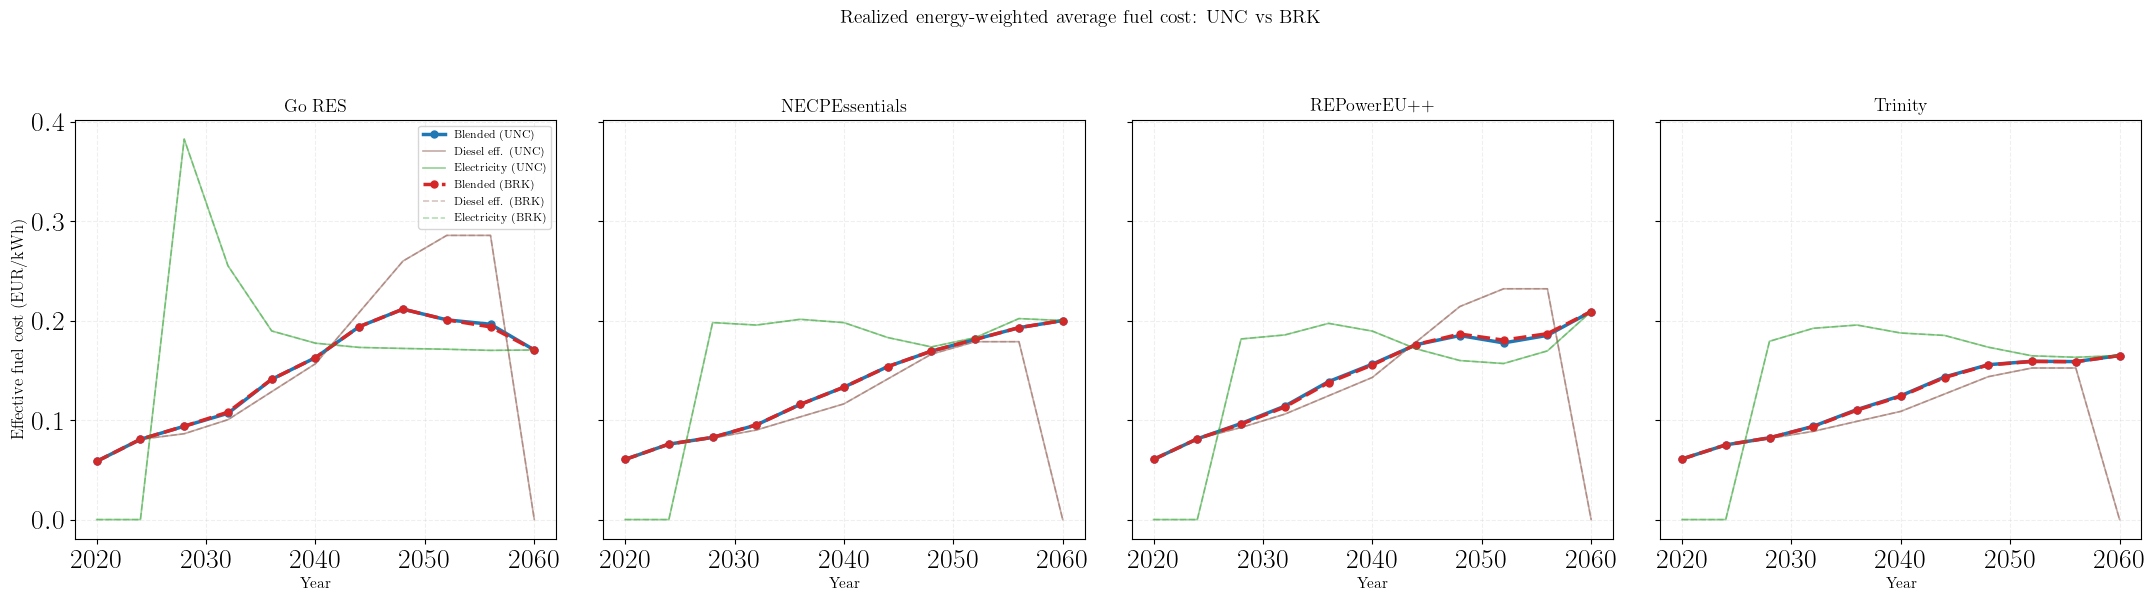

Saved: figures/effective_fuel_cost_unc_vs_brk.pdf


In [288]:
# ============================================================
# Realized effective fuel cost: energy-weighted average
# Blended = (diesel_spending + elec_spending + carbon) / total_energy
# Also shows per-fuel averages for diesel and electricity separately
# Compares UNC vs BRK for all 4 scenarios
# ============================================================

from collections import defaultdict

def compute_effective_fuel_cost_by_year(scenario_id, run_path):
    """For each modeled year, compute energy-weighted average fuel cost (EUR/kWh)."""
    input_scenario = fuel_cost_files[scenario_id]
    avg_elec_price, avg_diesel_price = load_avg_fuel_prices(input_scenario)
    carbon_price = carbon_price_by_scenario[input_scenario]

    s_file = find_latest_result_file(run_path, "s")
    if not s_file:
        print(f"  WARNING: s_dict not found in {run_path}")
        return {}

    raw = load_yaml_file(s_file)
    by_year = defaultdict(lambda: {"elec_mwh": 0.0, "diesel_mwh": 0.0,
                                    "elec_cost": 0.0, "diesel_cost": 0.0,
                                    "carbon_cost": 0.0})

    for k, v in raw.items():
        ci = parse_ci(k)
        if ci is None or len(ci) != 5:
            continue
        y_idx, prkg_flat, tv_1based, fl_flat, gen_idx = ci
        energy_mwh = float(v)
        if energy_mwh <= 0:
            continue
        year = Y_INIT + (y_idx - 1) * TIME_STEP
        annual_idx = min(year - Y_INIT, len(avg_elec_price) - 1)
        energy_kwh = energy_mwh * 1000

        if fl_flat in (1, 2):  # electricity
            price = avg_elec_price[annual_idx]
            by_year[year]["elec_mwh"] += energy_mwh
            by_year[year]["elec_cost"] += energy_kwh * price
        elif fl_flat == 3:  # diesel
            price = avg_diesel_price[annual_idx]
            cp = carbon_price[annual_idx] if annual_idx < len(carbon_price) else carbon_price[-1]
            carbon_surcharge = 1e-6 * EMISSION_FACTOR_DIESEL * cp
            by_year[year]["diesel_mwh"] += energy_mwh
            by_year[year]["diesel_cost"] += energy_kwh * price
            by_year[year]["carbon_cost"] += energy_kwh * carbon_surcharge

    return dict(by_year)

# --- Compute for all scenarios and both runs ---
eff_fuel_data = {}
for scenario_id, config in SCENARIOS.items():
    eff_fuel_data[scenario_id] = {}
    unc_path = RESULTS_PATH / scenario_id
    brk_path = BREAKS_PATH / scenario_id
    print(f"{config['name']} ({scenario_id}):")
    eff_fuel_data[scenario_id]["unc"] = compute_effective_fuel_cost_by_year(scenario_id, unc_path)
    eff_fuel_data[scenario_id]["brk"] = compute_effective_fuel_cost_by_year(scenario_id, brk_path)
    for mode in ["unc", "brk"]:
        d = eff_fuel_data[scenario_id][mode]
        if 2040 in d:
            r = d[2040]
            total_mwh = r["elec_mwh"] + r["diesel_mwh"]
            total_cost = r["elec_cost"] + r["diesel_cost"] + r["carbon_cost"]
            avg = total_cost / (total_mwh * 1000) if total_mwh > 0 else 0
            elec_avg = r["elec_cost"] / (r["elec_mwh"] * 1000) if r["elec_mwh"] > 0 else 0
            diesel_avg = (r["diesel_cost"] + r["carbon_cost"]) / (r["diesel_mwh"] * 1000) if r["diesel_mwh"] > 0 else 0
            print(f"  {mode.upper()} 2040: elec={r['elec_mwh']:,.0f} MWh @ {elec_avg:.4f}, "
                  f"diesel={r['diesel_mwh']:,.0f} MWh @ {diesel_avg:.4f}, "
                  f"blended={avg:.4f} EUR/kWh")

# --- Helper to extract time series ---
def get_timeseries(data_by_year, metric):
    """Extract sorted (years, values) for a given metric."""
    years = sorted(data_by_year.keys())
    vals = []
    for yr in years:
        r = data_by_year[yr]
        total_mwh = r["elec_mwh"] + r["diesel_mwh"]
        if metric == "blended":
            total_cost = r["elec_cost"] + r["diesel_cost"] + r["carbon_cost"]
            vals.append(total_cost / (total_mwh * 1000) if total_mwh > 0 else 0)
        elif metric == "elec":
            vals.append(r["elec_cost"] / (r["elec_mwh"] * 1000) if r["elec_mwh"] > 0 else 0)
        elif metric == "diesel":
            vals.append((r["diesel_cost"] + r["carbon_cost"]) / (r["diesel_mwh"] * 1000) if r["diesel_mwh"] > 0 else 0)
    return years, vals

# --- Figure: 4 panels, UNC vs BRK ---
# Each panel: blended (thick), diesel effective (thin), electricity (thin)
fig, axes = plt.subplots(1, 4, figsize=(22, 6), sharey=True)

for si, (scenario_id, config) in enumerate(SCENARIOS.items()):
    ax = axes[si]

    for mode, ls_main, alpha_sub in [("unc", "-", 0.5), ("brk", "--", 0.35)]:
        d = eff_fuel_data[scenario_id][mode]
        label_suffix = "UNC" if mode == "unc" else "BRK"
        color_blend = "#1f77b4" if mode == "unc" else "#d62728"

        # Blended effective cost (main line)
        yrs, vals = get_timeseries(d, "blended")
        ax.plot(yrs, vals, ls_main, color=color_blend, linewidth=2.5,
                label=f"Blended ({label_suffix})", marker="o", markersize=5)

        # Diesel effective (thin)
        yrs, vals = get_timeseries(d, "diesel")
        ax.plot(yrs, vals, ls_main, color="#8c564b", linewidth=1.2, alpha=alpha_sub,
                label=f"Diesel eff. ({label_suffix})" if si == 0 else None)

        # Electricity (thin)
        yrs, vals = get_timeseries(d, "elec")
        ax.plot(yrs, vals, ls_main, color="#2ca02c", linewidth=1.2, alpha=alpha_sub,
                label=f"Electricity ({label_suffix})" if si == 0 else None)

    ax.set_title(config["name"], fontweight="bold", fontsize=13)
    ax.set_xlabel("Year", fontsize=11)
    ax.set_xlim(2018, 2062)
    ax.grid(True, alpha=0.2, linestyle="--")

    if si == 0:
        ax.set_ylabel("Effective fuel cost (EUR/kWh)", fontweight="bold", fontsize=12)
        ax.legend(fontsize=8, loc="upper right")

fig.suptitle("Realized energy-weighted average fuel cost: UNC vs BRK",
             fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(BASE_PATH / "figures" / "effective_fuel_cost_unc_vs_brk.pdf", bbox_inches="tight")
plt.savefig(BASE_PATH / "figures" / "effective_fuel_cost_unc_vs_brk.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved: figures/effective_fuel_cost_unc_vs_brk.pdf")


Analyzing: Go RES (scenario_000)
OD pairs with BEV fleet differences: 1701 (out of 2244 total with BEVs)

--- BEV fleet delta summary by year (UNC - BRK) ---
  2028: 215 routes UNC>BRK, 240 routes BRK>UNC, net delta = -0.0 vehicles
  2032: 274 routes UNC>BRK, 350 routes BRK>UNC, net delta = +0.1 vehicles
  2036: 268 routes UNC>BRK, 355 routes BRK>UNC, net delta = +0.2 vehicles
  2040: 348 routes UNC>BRK, 659 routes BRK>UNC, net delta = +0.2 vehicles
  2044: 337 routes UNC>BRK, 602 routes BRK>UNC, net delta = -0.1 vehicles
  2048: 303 routes UNC>BRK, 645 routes BRK>UNC, net delta = -0.1 vehicles
  2052: 351 routes UNC>BRK, 873 routes BRK>UNC, net delta = +0.2 vehicles
  2056: 311 routes UNC>BRK, 857 routes BRK>UNC, net delta = -265.4 vehicles
  2060: 348 routes UNC>BRK, 815 routes BRK>UNC, net delta = -216.6 vehicles

Top 15 routes by |BEV delta| in 2032
  Diesel effective: 0.1922 EUR/kWh  |  Avg electricity: 0.2553 EUR/kWh  |  Ratio E/D: 1.328  |  DIESEL CHEAPER
   OD       Origin     

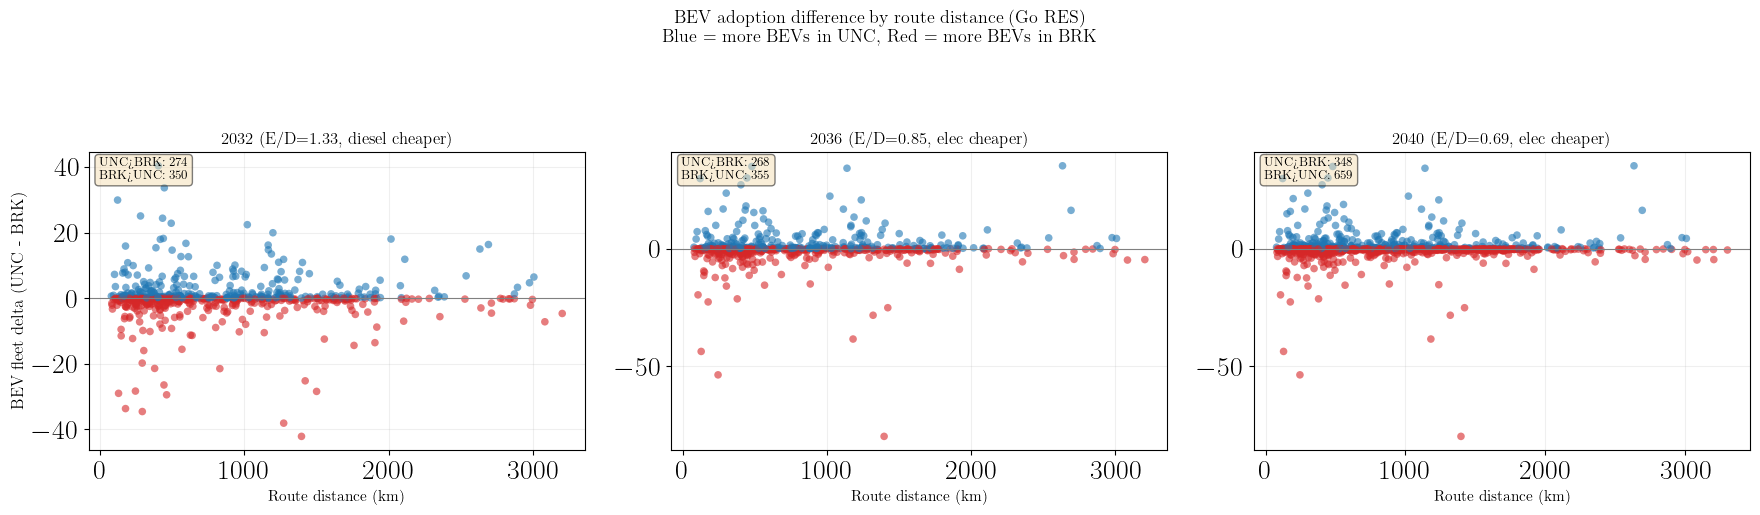

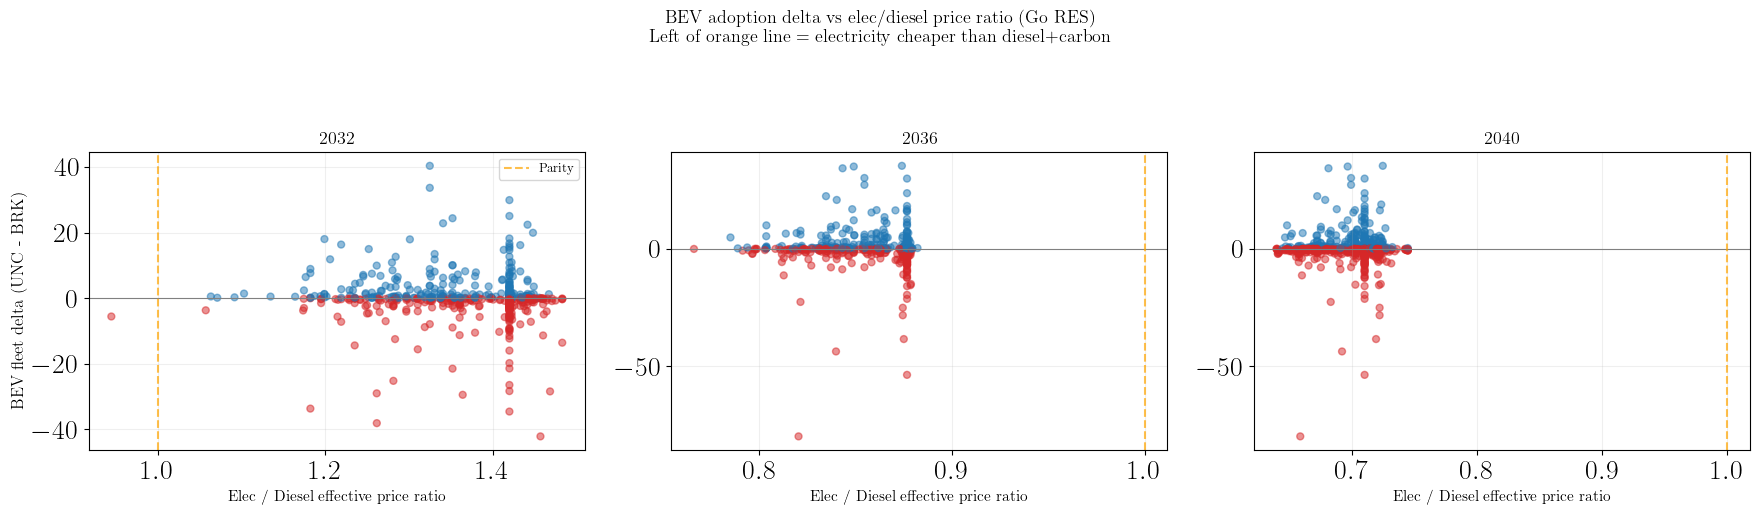

Saved: figures/bev_delta_vs_elec_diesel_ratio.pdf


In [289]:
# ============================================================
# Routes with different BEV adoption: UNC vs BRK
# Includes electricity price info along each route
# Shows 2032 (pre-crossover) and 2036/2040 (post-crossover)
# ============================================================

from collections import defaultdict
import statistics

# Focus on Go RES scenario
FOCUS_SCENARIO = list(SCENARIOS.keys())[0]  # scenario_000
FOCUS_NAME = SCENARIOS[FOCUS_SCENARIO]['name']
FOCUS_INPUT = fuel_cost_files[FOCUS_SCENARIO]  # scenario_000
print(f'Analyzing: {FOCUS_NAME} ({FOCUS_SCENARIO})')

# Load h_dict for UNC and BRK
unc_h_file = find_latest_result_file(RESULTS_PATH / FOCUS_SCENARIO, 'h')
brk_h_file = find_latest_result_file(BREAKS_PATH / FOCUS_SCENARIO, 'h')
unc_h_raw = load_yaml_file(unc_h_file)
brk_h_raw = load_yaml_file(brk_h_file)

def parse_h_to_fleet(raw_h):
    fleet = defaultdict(float)
    for k, v in raw_h.items():
        m = _H_KEY_RE.match(str(k))
        if not m:
            continue
        year = int(m.group(1))
        od_id = int(m.group(2))
        tv_id = int(m.group(3))
        n_veh = float(v)
        if n_veh > 0:
            fleet[(year, od_id, tv_id)] += n_veh
    return fleet

unc_fleet = parse_h_to_fleet(unc_h_raw)
brk_fleet = parse_h_to_fleet(brk_h_raw)

# Load odpair info
od_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'Odpair.yaml')
od_info = {od['id']: od for od in od_yaml}

# Load geographic element names
geo_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'GeographicElement.yaml')
geo_names = {g['id']: f"{g['nuts2_region']} ({g['country']})" for g in geo_yaml}

# Load path sequences
path_yaml = load_yaml_unsafe(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'Path.yaml')
path_sequences = {p['id']: p['sequence'] for p in path_yaml}

# Load location-specific electricity prices
fc_yaml = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / FOCUS_INPUT / 'FuelCost.yaml')
elec_price_by_loc = {}
for entry in fc_yaml:
    if 'elec' in entry.get('fuel', '').lower():
        loc = entry['location']
        if loc not in elec_price_by_loc:
            elec_price_by_loc[loc] = []
        elec_price_by_loc[loc].append(entry['cost_per_kWh'])
elec_price_avg_by_loc = {}
for loc, price_lists in elec_price_by_loc.items():
    n = len(price_lists[0])
    avg = [sum(pl[i] for pl in price_lists) / len(price_lists) for i in range(n)]
    elec_price_avg_by_loc[loc] = avg

carbon_price = carbon_price_by_scenario[FOCUS_INPUT]
DIESEL_BASE = 0.123

def route_elec_stats(path_id, year_idx):
    seq = path_sequences.get(path_id, [])
    prices = []
    for geo_id in seq:
        if geo_id in elec_price_avg_by_loc:
            prices.append(elec_price_avg_by_loc[geo_id][year_idx])
    if not prices:
        return 0, 0, 0, 0, 0
    avg = statistics.mean(prices)
    mn = min(prices)
    mx = max(prices)
    std = statistics.stdev(prices) if len(prices) > 1 else 0
    return avg, mn, mx, std, len(prices)

# Compute BEV delta per OD pair per year
all_od_ids = set()
for (yr, od, tv) in set(list(unc_fleet.keys()) + list(brk_fleet.keys())):
    if tv == 1:
        all_od_ids.add(od)

delta_rows = []
for year in MODELED_YEARS:
    year_idx = year - Y_INIT
    diesel_eff = DIESEL_BASE + 1e-6 * EMISSION_FACTOR_DIESEL * carbon_price[min(year_idx, len(carbon_price)-1)]
    for od_id in sorted(all_od_ids):
        unc_bev = unc_fleet.get((year, od_id, 1), 0.0)
        brk_bev = brk_fleet.get((year, od_id, 1), 0.0)
        unc_icev = unc_fleet.get((year, od_id, 0), 0.0)
        brk_icev = brk_fleet.get((year, od_id, 0), 0.0)
        delta = unc_bev - brk_bev
        if abs(delta) > 0.01:
            od = od_info.get(od_id, {})
            origin = geo_names.get(od.get('from', -1), '?')
            dest = geo_names.get(od.get('to', -1), '?')
            path_id = od.get('path_id', -1)
            path_len = path_lengths.get(path_id, 0)
            avg_ep, min_ep, max_ep, std_ep, n_nodes = route_elec_stats(path_id, year_idx)
            delta_rows.append({
                'year': year,
                'od_id': od_id,
                'origin': origin,
                'destination': dest,
                'path_id': path_id,
                'path_len_km': path_len,
                'n_nodes': n_nodes,
                'unc_bev': unc_bev,
                'brk_bev': brk_bev,
                'delta_bev': delta,
                'unc_icev': unc_icev,
                'brk_icev': brk_icev,
                'unc_bev_share': unc_bev / (unc_bev + unc_icev) if (unc_bev + unc_icev) > 0 else 0,
                'brk_bev_share': brk_bev / (brk_bev + brk_icev) if (brk_bev + brk_icev) > 0 else 0,
                'avg_elec_price': avg_ep,
                'min_elec_price': min_ep,
                'max_elec_price': max_ep,
                'std_elec_price': std_ep,
                'diesel_eff_price': diesel_eff,
                'elec_diesel_ratio': avg_ep / diesel_eff if diesel_eff > 0 else 0,
            })

delta_df = pd.DataFrame(delta_rows)
print(f'OD pairs with BEV fleet differences: {delta_df["od_id"].nunique()} '
      f'(out of {len(all_od_ids)} total with BEVs)')

# --- Summary by year ---
print('\n--- BEV fleet delta summary by year (UNC - BRK) ---')
for year in MODELED_YEARS:
    ydf = delta_df[delta_df['year'] == year]
    if len(ydf) == 0:
        continue
    n_more_unc = (ydf['delta_bev'] > 0.01).sum()
    n_more_brk = (ydf['delta_bev'] < -0.01).sum()
    total_delta = ydf['delta_bev'].sum()
    print(f'  {year}: {n_more_unc} routes UNC>BRK, {n_more_brk} routes BRK>UNC, '
          f'net delta = {total_delta:+.1f} vehicles')

# --- Print top routes for 2032, 2036, 2040 ---
for SHOW_YEAR in [2032, 2036, 2040]:
    yr_idx = SHOW_YEAR - Y_INIT
    diesel_eff_yr = DIESEL_BASE + 1e-6 * EMISSION_FACTOR_DIESEL * carbon_price[min(yr_idx, len(carbon_price)-1)]
    avg_elec_yr = statistics.mean(
        [elec_price_avg_by_loc[loc][yr_idx] for loc in elec_price_avg_by_loc])
    print(f'\n{"="*90}')
    print(f'Top 15 routes by |BEV delta| in {SHOW_YEAR}')
    print(f'  Diesel effective: {diesel_eff_yr:.4f} EUR/kWh  |  '
          f'Avg electricity: {avg_elec_yr:.4f} EUR/kWh  |  '
          f'Ratio E/D: {avg_elec_yr/diesel_eff_yr:.3f}  |  '
          f'{"ELEC CHEAPER" if avg_elec_yr < diesel_eff_yr else "DIESEL CHEAPER"}')
    print(f'{"="*90}')
    df_yr = delta_df[delta_df['year'] == SHOW_YEAR].copy()
    df_yr['abs_delta'] = df_yr['delta_bev'].abs()
    df_yr = df_yr.sort_values('abs_delta', ascending=False)
    print(f'{"OD":>5} {"Origin":>12} {"Dest":>12} {"km":>5} '
          f'{"UNC%":>5} {"BRK%":>5} {"dBEV":>6} '
          f'{"AvgElec":>8} {"DslEff":>8} {"E/D":>5}')
    for _, r in df_yr.head(15).iterrows():
        print(f'{r["od_id"]:5.0f} {r["origin"]:>12} {r["destination"]:>12} {r["path_len_km"]:5.0f} '
              f'{r["unc_bev_share"]:5.1%} {r["brk_bev_share"]:5.1%} {r["delta_bev"]:+6.1f} '
              f'{r["avg_elec_price"]:8.4f} {r["diesel_eff_price"]:8.4f} {r["elec_diesel_ratio"]:5.2f}')

# --- Figure: 3 years side-by-side, route distance vs BEV delta ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ai, year in enumerate([2032, 2036, 2040]):
    ax = axes[ai]
    ydf = delta_df[delta_df['year'] == year]
    yr_idx = year - Y_INIT
    diesel_eff_yr = DIESEL_BASE + 1e-6 * EMISSION_FACTOR_DIESEL * carbon_price[min(yr_idx, len(carbon_price)-1)]
    avg_elec_yr = statistics.mean(
        [elec_price_avg_by_loc[loc][yr_idx] for loc in elec_price_avg_by_loc])
    colors = ['#d62728' if d < 0 else '#1f77b4' for d in ydf['delta_bev']]
    ax.scatter(ydf['path_len_km'], ydf['delta_bev'], c=colors, alpha=0.6, s=30, edgecolors='none')
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='-')
    ax.set_xlabel('Route distance (km)', fontsize=11)
    regime = 'elec cheaper' if avg_elec_yr < diesel_eff_yr else 'diesel cheaper'
    ax.set_title(f'{year}  (E/D={avg_elec_yr/diesel_eff_yr:.2f}, {regime})',
                 fontweight='bold', fontsize=12)
    ax.grid(True, alpha=0.2)
    if ai == 0:
        ax.set_ylabel('BEV fleet delta (UNC - BRK)', fontweight='bold', fontsize=12)
    # Add text for count
    n_pos = (ydf['delta_bev'] > 0.01).sum()
    n_neg = (ydf['delta_bev'] < -0.01).sum()
    ax.text(0.02, 0.98, f'UNC>BRK: {n_pos}\nBRK>UNC: {n_neg}',
            transform=ax.transAxes, fontsize=9, va='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

fig.suptitle(f'BEV adoption difference by route distance ({FOCUS_NAME})\n'
             f'Blue = more BEVs in UNC, Red = more BEVs in BRK',
             fontweight='bold', fontsize=13, y=1.05)
plt.tight_layout()
plt.savefig(BASE_PATH / 'figures' / 'bev_delta_by_route_distance.pdf', bbox_inches='tight')
plt.savefig(BASE_PATH / 'figures' / 'bev_delta_by_route_distance.png', bbox_inches='tight', dpi=150)
plt.show()

# --- Figure: elec price vs BEV delta for 2032 vs 2036 vs 2040 ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ai, year in enumerate([2032, 2036, 2040]):
    ax = axes[ai]
    ydf = delta_df[delta_df['year'] == year]
    yr_idx = year - Y_INIT
    diesel_eff_yr = DIESEL_BASE + 1e-6 * EMISSION_FACTOR_DIESEL * carbon_price[min(yr_idx, len(carbon_price)-1)]
    colors = ['#d62728' if d < 0 else '#1f77b4' for d in ydf['delta_bev']]
    ax.scatter(ydf['elec_diesel_ratio'], ydf['delta_bev'], c=colors, alpha=0.5, s=25)
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.axvline(1.0, color='orange', linewidth=1.5, linestyle='--', alpha=0.7, label='Parity')
    ax.set_xlabel('Elec / Diesel effective price ratio', fontsize=11)
    ax.set_title(str(year), fontweight='bold', fontsize=13)
    ax.grid(True, alpha=0.2)
    if ai == 0:
        ax.set_ylabel('BEV fleet delta (UNC - BRK)', fontweight='bold', fontsize=12)
        ax.legend(fontsize=9)

fig.suptitle(f'BEV adoption delta vs elec/diesel price ratio ({FOCUS_NAME})\n'
             f'Left of orange line = electricity cheaper than diesel+carbon',
             fontweight='bold', fontsize=13, y=1.05)
plt.tight_layout()
plt.savefig(BASE_PATH / 'figures' / 'bev_delta_vs_elec_diesel_ratio.pdf', bbox_inches='tight')
plt.savefig(BASE_PATH / 'figures' / 'bev_delta_vs_elec_diesel_ratio.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/bev_delta_vs_elec_diesel_ratio.pdf')


In [290]:
if obj_values:
    print(f"{'Objective delta':<25}", end='')
    for scenario_id in SCENARIOS:
        if scenario_id in obj_values:
            obj_d = (obj_values[scenario_id].get('brk', 0) - obj_values[scenario_id].get('unc', 0)) / 1e6
            print(f" {obj_d:>+18.1f}", end='')
        else:
            print(f" {'N/A':>18}", end='')
    print()

Objective delta                        +40.7              +41.2              +84.4              +42.6


<>:74: SyntaxWarning: invalid escape sequence '\D'
<>:74: SyntaxWarning: invalid escape sequence '\D'
C:\Users\simuser\AppData\Local\Temp\ipykernel_23268\3812101327.py:74: SyntaxWarning: invalid escape sequence '\D'
  plt.colorbar(im, ax=ax, shrink=0.8, label='$\Delta$ BEV fleet')


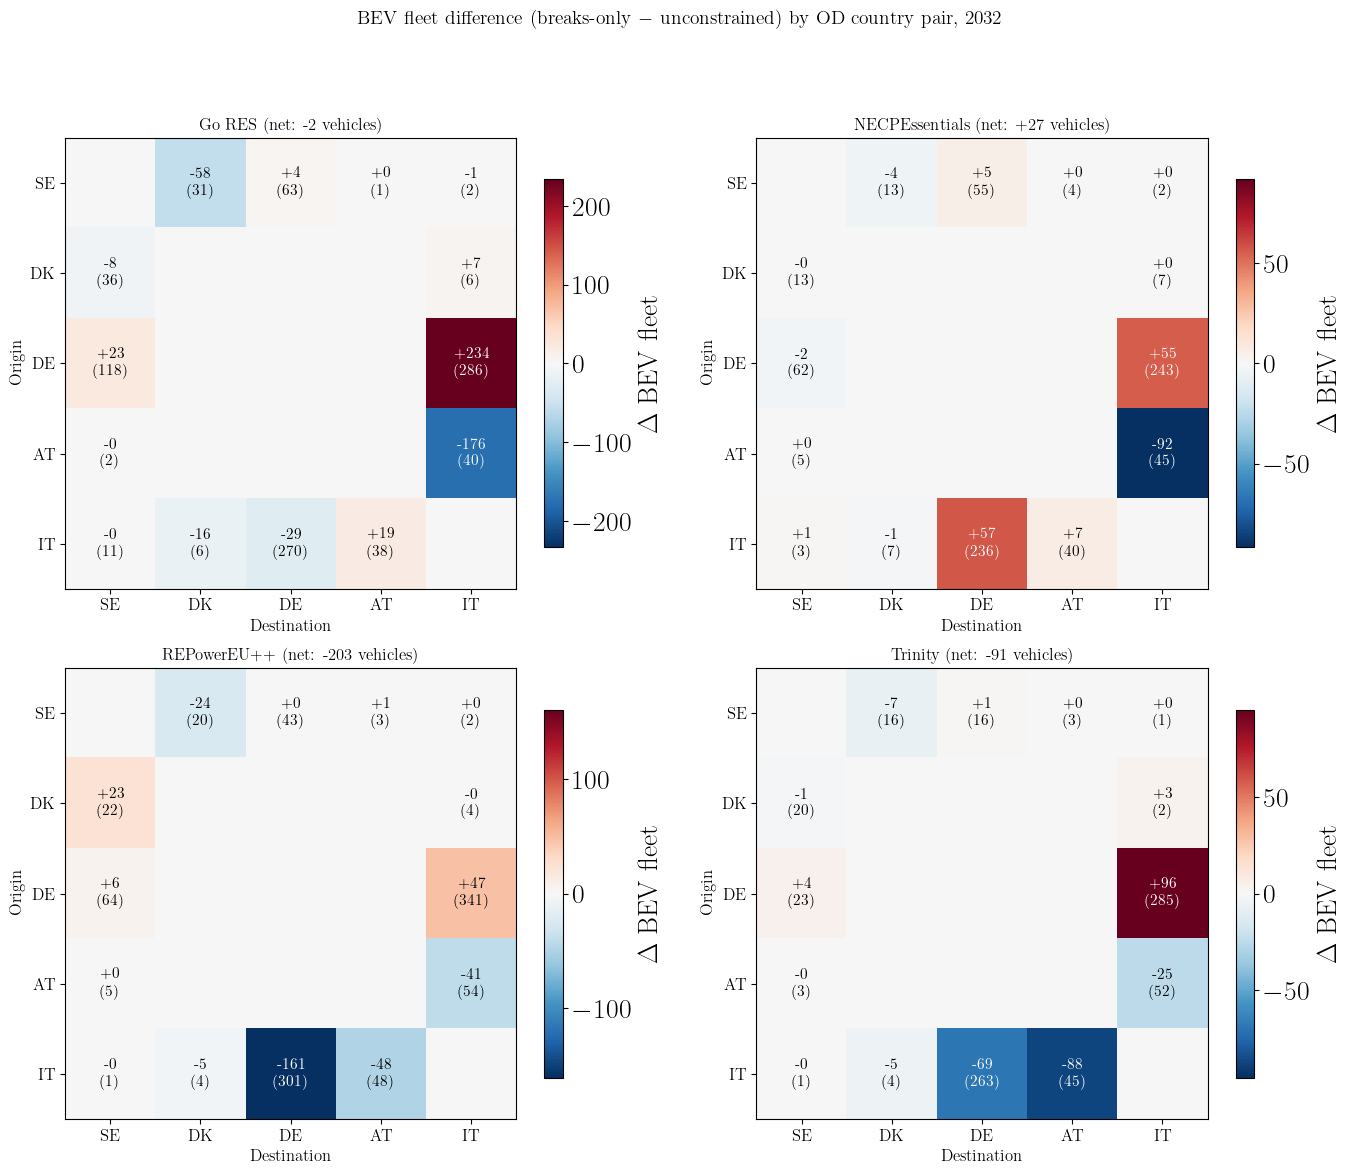

Saved to figures/bev_od_matrix_delta_4scenarios_2032.pdf


In [291]:

# ============================================================================
# OD Matrix Heatmap: BEV fleet delta (Breaks - Unconstrained) by country pair
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Country ordering along the corridor (north → south)
COUNTRY_ORDER = ['SE', 'DK', 'DE', 'AT', 'IT']

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('BEV fleet difference (breaks-only − unconstrained) by OD country pair, 2032',
             fontsize=14, fontweight='bold', y=0.98)

for idx, scenario_id in enumerate(['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']):
    ax = axes[idx // 2, idx % 2]
    config = SCENARIOS[scenario_id]
    
    if scenario_id not in all_deltas or all_deltas[scenario_id].empty:
        ax.set_title(f"{config['name']} — no data")
        ax.axis('off')
        continue
    
    df = all_deltas[scenario_id].copy()
    
    # Aggregate delta by (origin_country, dest_country)
    pair_agg = df.groupby(['origin_country', 'dest_country']).agg(
        delta=('delta', 'sum'),
        bev_unc=('bev_unc', 'sum'),
        n_routes=('odpair_id', 'count'),
    ).reset_index()
    
    # Build matrix
    countries = [c for c in COUNTRY_ORDER if c in set(pair_agg['origin_country']) | set(pair_agg['dest_country'])]
    n = len(countries)
    matrix = np.zeros((n, n))
    count_matrix = np.zeros((n, n), dtype=int)
    
    c2i = {c: i for i, c in enumerate(countries)}
    for _, row in pair_agg.iterrows():
        oi = c2i.get(row['origin_country'])
        di = c2i.get(row['dest_country'])
        if oi is not None and di is not None:
            matrix[oi, di] = row['delta']
            count_matrix[oi, di] = int(row['n_routes'])
    
    # Symmetric color scale
    vmax = max(abs(matrix.min()), abs(matrix.max()), 1)
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    
    im = ax.imshow(matrix, cmap='RdBu_r', norm=norm, aspect='equal')
    
    # Labels
    ax.set_xticks(range(n))
    ax.set_xticklabels(countries, fontsize=12)
    ax.set_yticks(range(n))
    ax.set_yticklabels(countries, fontsize=12)
    ax.set_xlabel('Destination', fontsize=12)
    ax.set_ylabel('Origin', fontsize=12)
    
    # Annotate each cell with delta value and route count
    for i in range(n):
        for j in range(n):
            val = matrix[i, j]
            cnt = count_matrix[i, j]
            if cnt == 0:
                continue
            color = 'white' if abs(val) > vmax * 0.6 else 'black'
            ax.text(j, i, f"{val:+.0f}\n({cnt})",
                    ha='center', va='center', fontsize=11, fontweight='bold', color=color)
    
    net_delta = matrix.sum()
    ax.set_title(f"{config['name']}  (net: {net_delta:+.0f} vehicles)", fontsize=12, fontweight='bold')
    plt.colorbar(im, ax=ax, shrink=0.8, label='$\Delta$ BEV fleet')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(BASE_PATH / 'figures' / 'bev_od_matrix_delta_4scenarios_2032.pdf', bbox_inches='tight', dpi=150)
plt.savefig(BASE_PATH / 'figures' / 'bev_od_matrix_delta_4scenarios_2032.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved to figures/bev_od_matrix_delta_4scenarios_2032.pdf")


In [292]:
print("all_deltas" in dir())
print(type(all_deltas) if "all_deltas" in dir() else "not defined")
if "all_deltas" in dir():
    print(list(all_deltas.keys()))


True
<class 'dict'>
['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']


AT-IT crossing OD pairs: 1437

Go RES (scenario_000):
  Component              UNC (MEUR)   BRK (MEUR)        Delta
  ----------------------------------------------------------
  Fuel: electricity           900.4        845.3        -55.1
  Fuel: diesel                166.5        178.3        +11.8
  Carbon cost                 933.0        999.0        +66.0
  Toll ICEV                   292.2        312.9        +20.7
  Toll BEV                    141.7        133.0         -8.7
  TOTAL                      2433.8       2468.4        +34.6

NECPEssentials (scenario_001):
  Component              UNC (MEUR)   BRK (MEUR)        Delta
  ----------------------------------------------------------
  Fuel: electricity           820.1        779.7        -40.4
  Fuel: diesel                423.3        439.6        +16.4
  Carbon cost                 564.7        586.6        +21.9
  Toll ICEV                   353.7        367.4        +13.7
  Toll BEV                    115.5        109.9

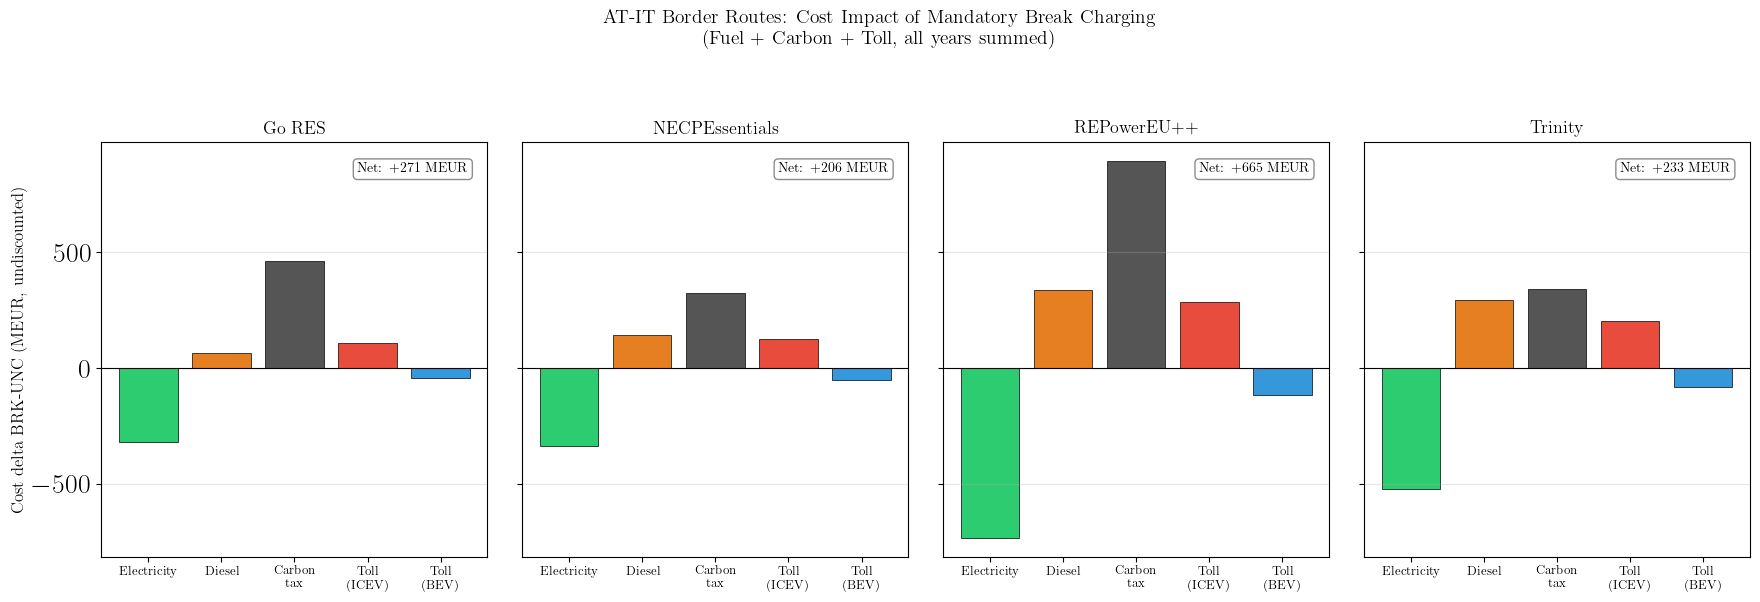

In [293]:
# ============================================================
# AT-IT BORDER ROUTES: Fueling + Carbon + Toll cost delta (UNC vs BRK)
# ============================================================
from collections import defaultdict

# --- Identify AT-IT crossing OD pairs ---
# "Crossing" = any odpair where one endpoint is IT and the other is not
# (captures DE->IT, AT->IT, NO->IT, SE->IT etc.)
at_it_odpair_ids = set()
for od_id, (o_geo, d_geo) in odpair_map.items():
    o_c = geoid2country.get(o_geo, '?')
    d_c = geoid2country.get(d_geo, '?')
    if ('IT' in (o_c, d_c)) and o_c != d_c:
        at_it_odpair_ids.add(od_id)
print(f"AT-IT crossing OD pairs: {len(at_it_odpair_ids)}")

# --- Compute route-level costs for a single run ---
def compute_at_it_route_costs(scenario_id, run_path):
    """
    For routes crossing AT-IT, compute:
      - Energy cost (elec + diesel) from s
      - Carbon cost (diesel) from s
      - Toll cost (ICEV + BEV) from f
    All UNDISCOUNTED (real EUR) so the numbers are interpretable.
    Returns dict of {year: {component: value}}
    """
    input_scenario = fuel_cost_files[scenario_id]
    avg_elec_price, avg_diesel_price = load_avg_fuel_prices(input_scenario)
    carbon_price = carbon_price_by_scenario[input_scenario]

    # --- Energy + carbon from s ---
    s_file = find_latest_result_file(run_path, 's')
    f_file = find_latest_result_file(run_path, 'f')

    # We need to map s entries to odpairs. s key: CartesianIndex(y_idx, prkg_flat, tv_1based, fl_flat, gen_idx)
    # prkg_flat encodes (product, odpair, path, geo) — we need the odpair.
    # But prkg_flat is a flattened index. We need the mapping.
    # Alternative: use f to get odpair-level energy and costs.
    #
    # Actually, f gives us tonnes by (year, odpair, path, mode, tv, gen).
    # We can compute:
    #   - toll = f * 1000 * path_len / W * toll_rate
    #   - fuel cost proxy: use vkm * energy_per_km * price
    # But this is an approximation. Better: use s with odpair filter.
    #
    # The s CartesianIndex needs dimensional info to unflatten prkg_flat.
    # Let's use f for tolls and estimate energy costs from f * spec_cons.

    # --- Load TechVehicle specific consumption ---
    tv_data = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / input_scenario / 'TechVehicle.yaml')
    # spec_cons is in kWh/km
    spec_consumption = {}
    for tv in tv_data:
        spec_consumption[tv['id']] = tv['spec_cons']  # list, annual index

    costs_by_year = {y: defaultdict(float) for y in MODELED_YEARS}

    if f_file:
        raw = load_yaml_file(f_file)
        for k, v in raw.items():
            m = _F_KEY_RE.match(str(k))
            if not m: continue
            year = int(m.group(1))
            od_id = int(m.group(3))
            path_id = int(m.group(4))
            mode_id = int(m.group(5))
            tv_id = int(m.group(6))
            gen = int(m.group(7))

            if mode_id != 1: continue  # road only
            if od_id not in at_it_odpair_ids: continue
            flow_ktonnes = float(v)
            if flow_ktonnes <= 0: continue

            path_len = path_lengths.get(path_id, 0)
            if path_len <= 0: continue

            annual_idx = min(year - Y_INIT, 40)
            w_arr = W_payload.get(tv_id, [13.6])
            gen_idx = min(max(gen - Y_INIT, 0), len(w_arr) - 1)
            w = w_arr[gen_idx]
            vkm = flow_ktonnes * 1000 * path_len / w

            # Toll
            toll_rate = toll_per_km.get(tv_id, 0)
            toll_eur = vkm * toll_rate * TIME_STEP

            # Energy cost: vkm * spec_cons * fuel_price
            sc_arr = spec_consumption[tv_id]
            sc = sc_arr[min(annual_idx, len(sc_arr) - 1)]
            energy_kwh = vkm * sc * TIME_STEP

            if tv_id == 0:  # ICEV / diesel
                fuel_price = avg_diesel_price[annual_idx]
                fuel_cost = energy_kwh * fuel_price
                # Carbon: energy_kwh * emission_factor(g/kWh) * 1e-6(t/g) * carbon_price(EUR/t)
                carbon_cost = energy_kwh * EMISSION_FACTOR_DIESEL * 1e-6 * carbon_price[min(year - Y_INIT, len(carbon_price) - 1)]
                costs_by_year[year]['fuel_diesel'] += fuel_cost
                costs_by_year[year]['carbon'] += carbon_cost
                costs_by_year[year]['toll_icev'] += toll_eur
            else:  # BEV / electricity
                fuel_price = avg_elec_price[annual_idx]
                fuel_cost = energy_kwh * fuel_price
                costs_by_year[year]['fuel_elec'] += fuel_cost
                costs_by_year[year]['toll_bev'] += toll_eur

    return costs_by_year

# --- Compute for all scenarios ---
at_it_costs = {}
for scen_id in SCENARIOS:
    scen_name = SCENARIOS[scen_id]['name']
    print(f"\n{scen_name} ({scen_id}):")
    unc_costs = compute_at_it_route_costs(scen_id, RESULTS_PATH / scen_id)
    brk_costs = compute_at_it_route_costs(scen_id, BREAKS_PATH / scen_id)
    at_it_costs[scen_id] = {'unc': unc_costs, 'brk': brk_costs}

    # Print summary for 2040
    y = 2040
    print(f"  {'Component':<20} {'UNC (MEUR)':>12} {'BRK (MEUR)':>12} {'Delta':>12}")
    print(f"  {'-'*58}")
    components = ['fuel_elec', 'fuel_diesel', 'carbon', 'toll_icev', 'toll_bev']
    labels = ['Fuel: electricity', 'Fuel: diesel', 'Carbon cost', 'Toll ICEV', 'Toll BEV']
    total_unc = total_brk = 0
    for comp, label in zip(components, labels):
        u = unc_costs[y][comp] / 1e6
        b = brk_costs[y][comp] / 1e6
        total_unc += u
        total_brk += b
        print(f"  {label:<20} {u:>12.1f} {b:>12.1f} {b-u:>+12.1f}")
    print(f"  {'TOTAL':<20} {total_unc:>12.1f} {total_brk:>12.1f} {total_brk-total_unc:>+12.1f}")

# --- Plot: grouped bar chart of delta (BRK - UNC) by component, all scenarios ---
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)
components = ['fuel_elec', 'fuel_diesel', 'carbon', 'toll_icev', 'toll_bev']
comp_labels = ['Electricity', 'Diesel', 'Carbon\ntax', 'Toll\n(ICEV)', 'Toll\n(BEV)']
comp_colors = ['#2ECC71', '#E67E22', '#555555', '#E74C3C', '#3498DB']

for idx, (scen_id, config) in enumerate(SCENARIOS.items()):
    ax = axes[idx]
    # Sum over all years
    deltas = []
    for comp in components:
        total_delta = sum(
            at_it_costs[scen_id]['brk'][y][comp] - at_it_costs[scen_id]['unc'][y][comp]
            for y in MODELED_YEARS
        ) / 1e6  # MEUR
        deltas.append(total_delta)

    bars = ax.bar(range(len(components)), deltas, color=comp_colors, edgecolor='black', linewidth=0.5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(range(len(components)))
    ax.set_xticklabels(comp_labels, fontsize=9)
    ax.set_title(config['name'], fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')

    # Net delta annotation
    net = sum(deltas)
    ax.text(0.95, 0.95, f'Net: {net:+.0f} MEUR', transform=ax.transAxes,
            ha='right', va='top', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.9))

axes[0].set_ylabel('Cost delta BRK-UNC (MEUR, undiscounted)', fontsize=12)
plt.suptitle('AT-IT Border Routes: Cost Impact of Mandatory Break Charging\n(Fuel + Carbon + Toll, all years summed)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_path = BASE_PATH / 'figures' / 'at_it_route_cost_delta_brk_vs_unc.pdf'
plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
print(f"\nSaved to {save_path}")
plt.show()

In [294]:
# ============================================================
# LEVELIZED COST DELTA: EUR per 1000 tkm (AT-IT routes)
# ============================================================

def compute_at_it_tkm(scenario_id, run_path):
    """Compute total tkm for AT-IT crossing routes, by year."""
    f_file = find_latest_result_file(run_path, 'f')
    tkm_by_year = {y: 0.0 for y in MODELED_YEARS}
    if not f_file: return tkm_by_year
    raw = load_yaml_file(f_file)
    for k, v in raw.items():
        m = _F_KEY_RE.match(str(k))
        if not m: continue
        year = int(m.group(1))
        od_id = int(m.group(3))
        path_id = int(m.group(4))
        flow_ktonnes = float(v)
        if flow_ktonnes <= 0 or od_id not in at_it_odpair_ids: continue
        path_len = path_lengths.get(path_id, 0)
        if path_len <= 0: continue
        # tkm = ktonnes * 1000 * km = tonnes * km
        tkm_by_year[year] += flow_ktonnes * 1000 * path_len * TIME_STEP
    return tkm_by_year

# --- Compute tkm and levelized costs ---
print("=" * 100)
print("LEVELIZED COST: AT-IT Border Routes (EUR per 1000 tkm, undiscounted)")
print("=" * 100)

components = ['fuel_elec', 'fuel_diesel', 'carbon', 'toll_icev', 'toll_bev']
labels = ['Fuel: electricity', 'Fuel: diesel', 'Carbon cost', 'Toll ICEV', 'Toll BEV']

for scen_id, config in SCENARIOS.items():
    scen_name = config['name']
    
    # Total tkm across all years (same for UNC and BRK since demand is the same,
    # but technology split differs so compute both)
    tkm_unc = compute_at_it_tkm(scen_id, RESULTS_PATH / scen_id)
    tkm_brk = compute_at_it_tkm(scen_id, BREAKS_PATH / scen_id)
    
    total_tkm_unc = sum(tkm_unc.values())
    total_tkm_brk = sum(tkm_brk.values())
    
    # Levelized = total cost / total tkm * 1000 (EUR per 1000 tkm)
    print(f"\n--- {scen_name} ({scen_id}) ---")
    print(f"  Total tkm: UNC={total_tkm_unc/1e9:.1f} Btkm, BRK={total_tkm_brk/1e9:.1f} Btkm")
    print(f"  {'Component':<20} {'UNC':>10} {'BRK':>10} {'Delta':>10}  (EUR/1000tkm)")
    print(f"  {'-'*55}")
    
    total_lev_unc = total_lev_brk = 0
    for comp, label in zip(components, labels):
        cost_unc = sum(at_it_costs[scen_id]['unc'][y][comp] for y in MODELED_YEARS)
        cost_brk = sum(at_it_costs[scen_id]['brk'][y][comp] for y in MODELED_YEARS)
        lev_unc = cost_unc / total_tkm_unc * 1000 if total_tkm_unc > 0 else 0
        lev_brk = cost_brk / total_tkm_brk * 1000 if total_tkm_brk > 0 else 0
        total_lev_unc += lev_unc
        total_lev_brk += lev_brk
        print(f"  {label:<20} {lev_unc:>10.2f} {lev_brk:>10.2f} {lev_brk-lev_unc:>+10.2f}")
    print(f"  {'TOTAL':<20} {total_lev_unc:>10.2f} {total_lev_brk:>10.2f} {total_lev_brk-total_lev_unc:>+10.2f}")

# --- Also compute system-wide levelized objective delta ---
print("\n" + "=" * 100)
print("SYSTEM-WIDE: Objective value delta per 1000 tkm")
print("=" * 100)

for scen_id, config in SCENARIOS.items():
    scen_name = config['name']
    
    # System-wide tkm (all routes, not just AT-IT)
    def compute_total_tkm(run_path):
        f_file = find_latest_result_file(run_path, 'f')
        total = 0.0
        if not f_file: return total
        raw = load_yaml_file(f_file)
        for k, v in raw.items():
            m = _F_KEY_RE.match(str(k))
            if not m: continue
            year = int(m.group(1))
            path_id = int(m.group(4))
            flow_ktonnes = float(v)
            if flow_ktonnes <= 0: continue
            path_len = path_lengths.get(path_id, 0)
            if path_len <= 0: continue
            total += flow_ktonnes * 1000 * path_len * TIME_STEP
        return total
    
    sys_tkm_unc = compute_total_tkm(RESULTS_PATH / scen_id)
    sys_tkm_brk = compute_total_tkm(BREAKS_PATH / scen_id)
    
    # Load objective values from summary_stats
    unc_stats = load_yaml_file(RESULTS_PATH / scen_id / 'summary_stats.yaml')
    brk_stats = load_yaml_file(BREAKS_PATH / scen_id / 'summary_stats.yaml')
    obj_unc = float(unc_stats.get('objective_value', 0))
    obj_brk = float(brk_stats.get('objective_value', 0))
    obj_delta = obj_brk - obj_unc
    
    # Levelized objective: EUR/1000tkm
    lev_obj_unc = obj_unc / sys_tkm_unc * 1000 if sys_tkm_unc > 0 else 0
    lev_obj_brk = obj_brk / sys_tkm_brk * 1000 if sys_tkm_brk > 0 else 0
    lev_delta = obj_delta / sys_tkm_unc * 1000 if sys_tkm_unc > 0 else 0
    
    print(f"\n  {scen_name}:")
    print(f"    System tkm: UNC={sys_tkm_unc/1e9:.1f} Btkm, BRK={sys_tkm_brk/1e9:.1f} Btkm")
    print(f"    Objective:  UNC={obj_unc/1e9:.3f} GEUR, BRK={obj_brk/1e9:.3f} GEUR, Delta={obj_delta/1e6:+.1f} MEUR")
    print(f"    Levelized:  UNC={lev_obj_unc:.2f}, BRK={lev_obj_brk:.2f}, Delta={lev_delta:+.3f} EUR/1000tkm")

LEVELIZED COST: AT-IT Border Routes (EUR per 1000 tkm, undiscounted)

--- Go RES (scenario_000) ---
  Total tkm: UNC=863.1 Btkm, BRK=863.1 Btkm
  Component                   UNC        BRK      Delta  (EUR/1000tkm)
  -------------------------------------------------------
  Fuel: electricity          9.33       8.96      -0.37
  Fuel: diesel               4.16       4.23      +0.07
  Carbon cost                7.52       8.06      +0.54
  Toll ICEV                  3.60       3.72      +0.12
  Toll BEV                   1.50       1.45      -0.05
  TOTAL                     26.11      26.42      +0.31

--- NECPEssentials (scenario_001) ---
  Total tkm: UNC=863.1 Btkm, BRK=863.1 Btkm
  Component                   UNC        BRK      Delta  (EUR/1000tkm)
  -------------------------------------------------------
  Fuel: electricity          8.90       8.52      -0.39
  Fuel: diesel               6.28       6.44      +0.16
  Carbon cost                4.81       5.18      +0.37
  Toll ICEV

BLENDED EFFECTIVE FUEL COST: AT-IT Border Routes (EUR/MWh)
= (diesel spend + carbon cost + electricity spend) / (diesel MWh + electricity MWh)

--- Go RES (scenario_000) ---
  Year                              --- UNC ---                            --- BRK ---      Delta
             Elec MWh   Diesel MWh    EUR/MWh     Elec MWh   Diesel MWh    EUR/MWh    EUR/MWh
  ----------------------------------------------------------------------------------------------------
  2020              0   17,235,982      58.54            0   17,235,982      58.54      +0.00
  2024              0   17,130,797      80.71            0   17,130,797      80.71      +0.00
  2028        555,027   16,039,151      96.23      414,770   16,249,062      93.69      -2.54
  2032      1,179,785   14,637,664     112.00    1,093,239   14,770,834     111.12      -0.88
  2036      4,164,964    9,379,967     147.38    3,908,373    9,778,422     146.05      -1.34
  2040      5,076,141    7,015,199     165.40    4,765,314   

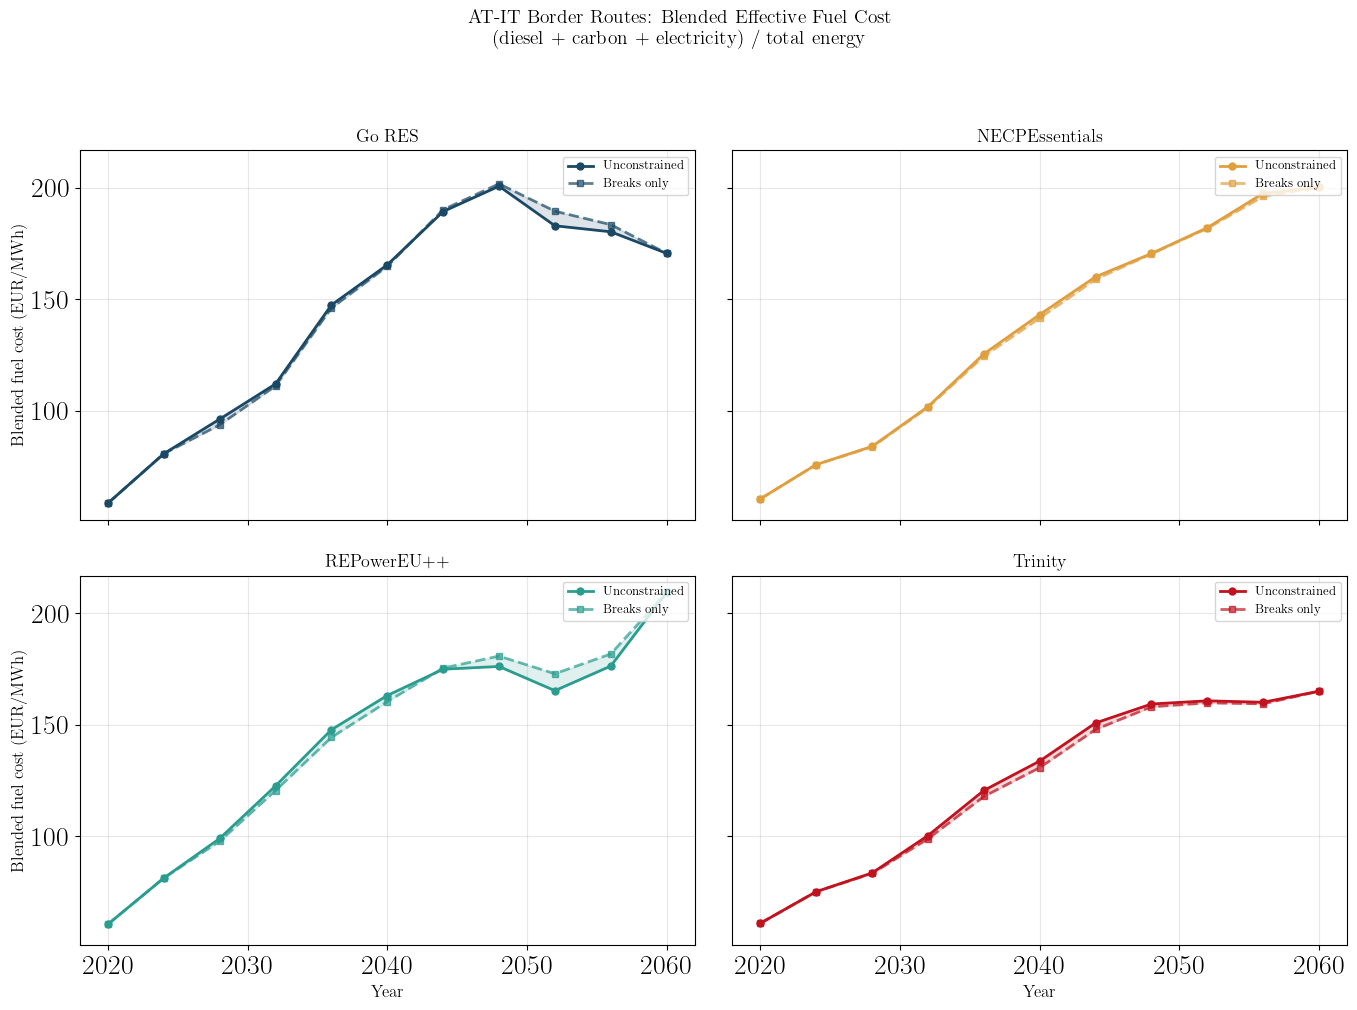

In [295]:
# ============================================================
# BLENDED EFFECTIVE FUEL COST: AT-IT routes
# = (diesel_spend + carbon_cost + electricity_spend) / (diesel_MWh + elec_MWh)
# Gives EUR/MWh average across both fuels, UNC vs BRK
# ============================================================

def compute_at_it_energy_and_fuel_cost(scenario_id, run_path):
    """
    For AT-IT routes, compute energy consumed (MWh) and money spent on fuel+carbon,
    split by fuel type and by year.
    Returns: {year: {'elec_mwh': X, 'diesel_mwh': X,
                      'elec_cost': X, 'diesel_cost': X, 'carbon_cost': X}}
    """
    input_scenario = fuel_cost_files[scenario_id]
    avg_elec_price, avg_diesel_price = load_avg_fuel_prices(input_scenario)
    carbon_price = carbon_price_by_scenario[input_scenario]

    tv_data = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / input_scenario / 'TechVehicle.yaml')
    spec_cons = {}
    for tv in tv_data:
        spec_cons[tv['id']] = tv['spec_cons']

    f_file = find_latest_result_file(run_path, 'f')
    out = {y: {'elec_mwh': 0.0, 'diesel_mwh': 0.0,
               'elec_cost': 0.0, 'diesel_cost': 0.0, 'carbon_cost': 0.0}
           for y in MODELED_YEARS}

    if not f_file:
        return out

    raw = load_yaml_file(f_file)
    for k, v in raw.items():
        m = _F_KEY_RE.match(str(k))
        if not m: continue
        year = int(m.group(1))
        od_id = int(m.group(3))
        path_id = int(m.group(4))
        mode_id = int(m.group(5))
        tv_id = int(m.group(6))
        gen = int(m.group(7))

        if mode_id != 1 or od_id not in at_it_odpair_ids: continue
        flow_ktonnes = float(v)
        if flow_ktonnes <= 0: continue

        path_len = path_lengths.get(path_id, 0)
        if path_len <= 0: continue

        annual_idx = min(year - Y_INIT, 40)
        w_arr = W_payload.get(tv_id, [13.6])
        gen_idx = min(max(gen - Y_INIT, 0), len(w_arr) - 1)
        w = w_arr[gen_idx]
        vkm = flow_ktonnes * 1000 * path_len / w

        sc = spec_cons[tv_id][min(annual_idx, len(spec_cons[tv_id]) - 1)]
        energy_kwh = vkm * sc * TIME_STEP
        energy_mwh = energy_kwh / 1000

        if tv_id == 0:  # diesel
            price = avg_diesel_price[annual_idx]
            cp = carbon_price[min(year - Y_INIT, len(carbon_price) - 1)]
            out[year]['diesel_mwh'] += energy_mwh
            out[year]['diesel_cost'] += energy_kwh * price
            out[year]['carbon_cost'] += energy_kwh * EMISSION_FACTOR_DIESEL * 1e-6 * cp
        else:  # electricity
            price = avg_elec_price[annual_idx]
            out[year]['elec_mwh'] += energy_mwh
            out[year]['elec_cost'] += energy_kwh * price

    return out

# --- Compute for all scenarios ---
print("=" * 110)
print("BLENDED EFFECTIVE FUEL COST: AT-IT Border Routes (EUR/MWh)")
print("= (diesel spend + carbon cost + electricity spend) / (diesel MWh + electricity MWh)")
print("=" * 110)

blended_data = {}

for scen_id, config in SCENARIOS.items():
    scen_name = config['name']
    unc = compute_at_it_energy_and_fuel_cost(scen_id, RESULTS_PATH / scen_id)
    brk = compute_at_it_energy_and_fuel_cost(scen_id, BREAKS_PATH / scen_id)
    blended_data[scen_id] = {'unc': unc, 'brk': brk}

    print(f"\n--- {scen_name} ({scen_id}) ---")
    print(f"  {'Year':<8} {'--- UNC ---':>36}   {'--- BRK ---':>36}   {'Delta':>8}")
    print(f"  {'':<8} {'Elec MWh':>10} {'Diesel MWh':>12} {'EUR/MWh':>10}   {'Elec MWh':>10} {'Diesel MWh':>12} {'EUR/MWh':>10}   {'EUR/MWh':>8}")
    print(f"  {'-'*100}")

    for y in MODELED_YEARS:
        u = unc[y]
        b = brk[y]
        u_total_mwh = u['elec_mwh'] + u['diesel_mwh']
        b_total_mwh = b['elec_mwh'] + b['diesel_mwh']
        u_total_cost = u['elec_cost'] + u['diesel_cost'] + u['carbon_cost']
        b_total_cost = b['elec_cost'] + b['diesel_cost'] + b['carbon_cost']
        u_blended = u_total_cost / u_total_mwh if u_total_mwh > 0 else 0
        b_blended = b_total_cost / b_total_mwh if b_total_mwh > 0 else 0
        delta = b_blended - u_blended

        print(f"  {y:<8} {u['elec_mwh']:>10,.0f} {u['diesel_mwh']:>12,.0f} {u_blended:>10.2f}   "
              f"{b['elec_mwh']:>10,.0f} {b['diesel_mwh']:>12,.0f} {b_blended:>10.2f}   {delta:>+8.2f}")

# --- Plot: blended fuel cost time series, UNC vs BRK ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

for idx, (scen_id, config) in enumerate(SCENARIOS.items()):
    ax = axes[idx // 2][idx % 2]
    unc = blended_data[scen_id]['unc']
    brk = blended_data[scen_id]['brk']

    years = MODELED_YEARS
    unc_blended = []
    brk_blended = []
    for y in years:
        u = unc[y]
        b = brk[y]
        u_mwh = u['elec_mwh'] + u['diesel_mwh']
        b_mwh = b['elec_mwh'] + b['diesel_mwh']
        u_cost = u['elec_cost'] + u['diesel_cost'] + u['carbon_cost']
        b_cost = b['elec_cost'] + b['diesel_cost'] + b['carbon_cost']
        unc_blended.append(u_cost / u_mwh if u_mwh > 0 else 0)
        brk_blended.append(b_cost / b_mwh if b_mwh > 0 else 0)

    ax.plot(years, unc_blended, '-o', color=config['color'], linewidth=2, markersize=5, label='Unconstrained')
    ax.plot(years, brk_blended, '--s', color=config['color'], linewidth=2, markersize=5, alpha=0.7, label='Breaks only')

    # Shade the difference
    ax.fill_between(years, unc_blended, brk_blended, alpha=0.15, color=config['color'])

    ax.set_title(config['name'], fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, loc='upper right')

    if idx >= 2:
        ax.set_xlabel('Year', fontsize=12)
    if idx % 2 == 0:
        ax.set_ylabel('Blended fuel cost (EUR/MWh)', fontsize=12)

plt.suptitle('AT-IT Border Routes: Blended Effective Fuel Cost\n(diesel + carbon + electricity) / total energy',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_path = BASE_PATH / 'figures' / 'at_it_blended_fuel_cost_unc_vs_brk.pdf'
plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
print(f"\nSaved to {save_path}")
plt.show()

Loading location-specific electricity prices...
  scenario_000: 81 locations
  scenario_001: 81 locations
  scenario_002: 81 locations
  scenario_003: 81 locations

EFFECTIVE ELECTRICITY PRICE (EUR/kWh) — AT-IT Routes (from breaks_comparison_full)
= total electricity spend / total electricity charged, weighted by charging location

--- Go RES (scenario_000) ---
  UNC: go_res_without_breaks_2026-01-13_16-38-24_s_dict.yaml
  BRK: go_res_with_breaks_2026-01-13_16-29-55_s_dict.yaml
  Loading UNC...
    Matched electric AT-IT entries: 566080
  Loading BRK...
    Matched electric AT-IT entries: 192388

    Year   UNC EUR/kWh   BRK EUR/kWh       Delta     Rel %     UNC GWh     BRK GWh
  --------------------------------------------------------------------------------
    2028       0.30196       0.30456    +0.00260    +0.86%       120.8        91.8
    2032       0.20642       0.21947    +0.01305    +6.32%       350.5       321.9
    2036       0.17109       0.17218    +0.00109    +0.64%      

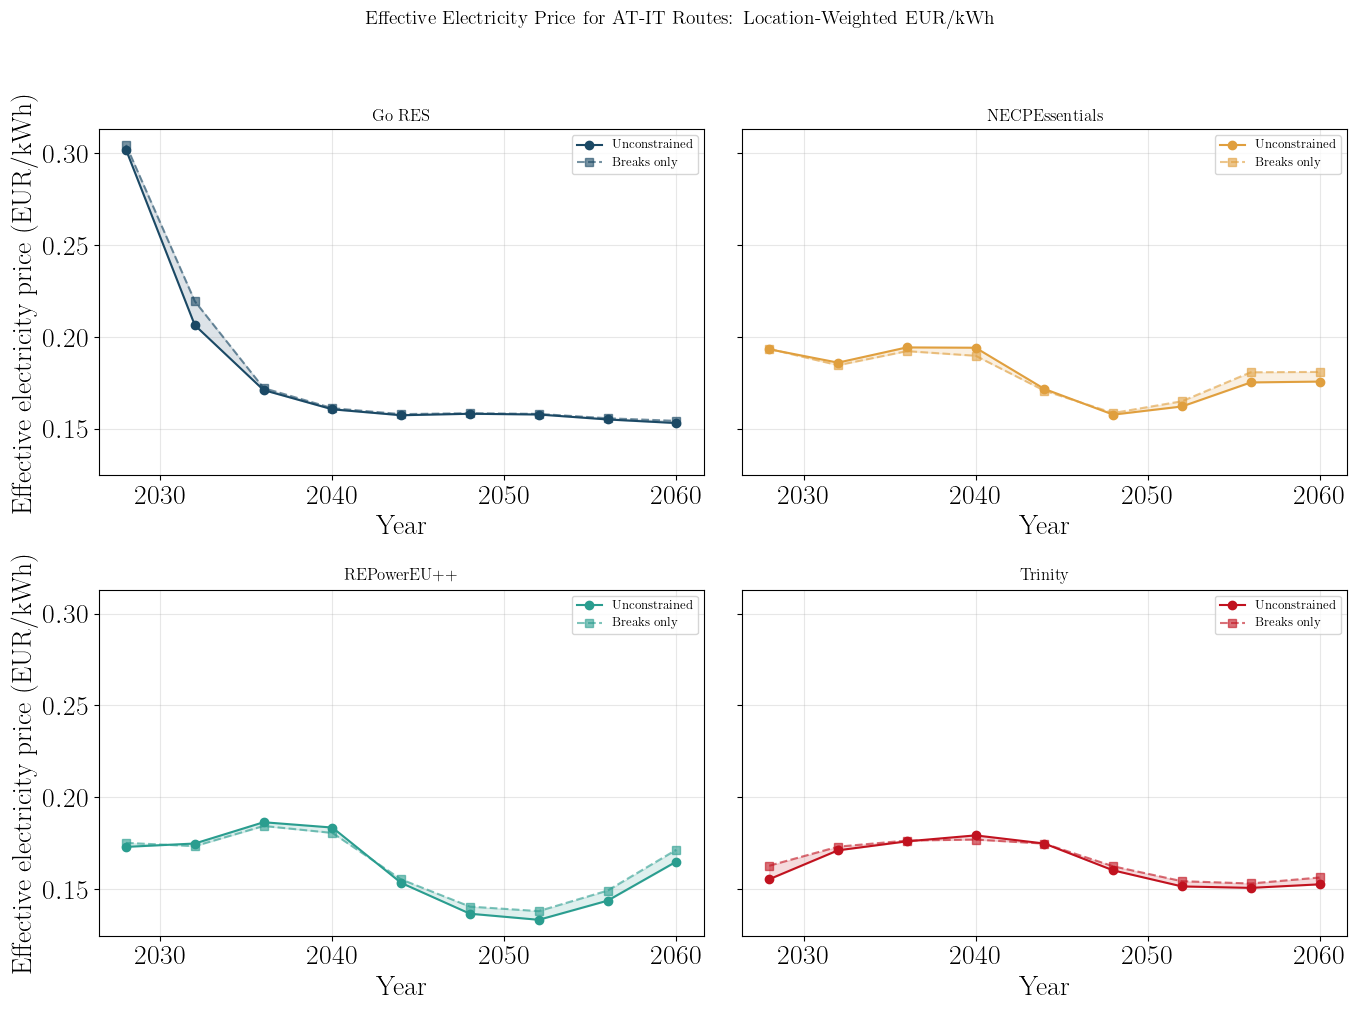

In [296]:
# ============================================================
# LEVELIZED ELECTRICITY COST (EUR/kWh) FOR AT-IT ROUTES
# Using tuple-format s_dict (breaks_comparison_full) with
# location-specific electricity prices from FuelCost.yaml
# ============================================================
import re
from collections import defaultdict

# --- Tuple-format s_dict paths (explicit keys, no prkg mapping needed) ---
S_DICT_PATHS = {
    'scenario_000': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'go_res_without_breaks' / 'go_res_without_breaks_2026-01-13_16-38-24_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'go_res_with_breaks' / 'go_res_with_breaks_2026-01-13_16-29-55_s_dict.yaml',
    },
    'scenario_001': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'necp_without_breaks' / 'necp_without_breaks_2026-01-13_16-55-29_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'necp_with_breaks' / 'necp_with_breaks_2026-01-13_16-47-08_s_dict.yaml',
    },
    'scenario_002': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'repower_without_breaks' / 'repower_without_breaks_2026-01-13_17-12-34_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'repower_with_breaks' / 'repower_with_breaks_2026-01-13_17-04-08_s_dict.yaml',
    },
    'scenario_003': {
        'unc': BASE_PATH / 'results' / 'breaks_comparison_full' / 'trinity_without_breaks' / 'trinity_without_breaks_2026-01-13_17-31-34_s_dict.yaml',
        'brk': BASE_PATH / 'results' / 'breaks_comparison_full' / 'trinity_with_breaks' / 'trinity_with_breaks_2026-01-13_17-22-59_s_dict.yaml',
    },
}

# Regex: (year, (prod, odpair, path, geo), tv_id, (fuel_id, infr_type), gen)
S_KEY_RE = re.compile(
    r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
)

# --- Load location-specific electricity prices ---
fuel_cost_input_map = {
    'scenario_000': 'scenario_000',
    'scenario_001': 'scenario_001',
    'scenario_002': 'scenario_002',
    'scenario_003': 'scenario_003',
}

def load_location_elec_prices_yearly(input_scenario_id):
    """Load location-specific electricity prices from FuelCost.yaml.
    Returns: {(location_id, infr_type_id): [yearly_prices_eur_per_kwh]}
    """
    fc_file = (BASE_PATH / 'input_data' / 'uncertainty_scenarios' /
               input_scenario_id / 'FuelCost.yaml')
    prices = {}
    if fc_file.exists():
        fc_data = load_yaml_file(fc_file)
        for entry in fc_data:
            if entry.get('fuel') == 'electricity':
                loc = entry['location']
                infr = entry.get('fueling_infr_type_id', 1)
                prices[(loc, infr)] = entry['cost_per_kWh']
    return prices

print("Loading location-specific electricity prices...")
elec_prices_by_scenario = {}
for scen_id, input_id in fuel_cost_input_map.items():
    elec_prices_by_scenario[scen_id] = load_location_elec_prices_yearly(input_id)
    n_locs = len(set(k[0] for k in elec_prices_by_scenario[scen_id]))
    print(f"  {scen_id}: {n_locs} locations")

# --- Compute effective EUR/kWh from tuple-format s_dict ---
def compute_effective_elec_price_tuple(s_file, elec_price_map, target_odpairs=None):
    """Compute effective EUR/kWh of electricity charged, by year.
    Uses tuple-format s_dict keys: (year, (prod, odpair, path, geo), tv_id, (fuel_id, infr_type), gen)
    tv_id=1 is electric, fuel_id=0 is electricity.
    """
    raw = load_yaml_file(s_file)
    yearly = defaultdict(lambda: {'cost': 0.0, 'energy_kwh': 0.0})
    matched = 0
    
    for k, v in raw.items():
        m = S_KEY_RE.match(str(k))
        if not m:
            continue
        year = int(m.group(1))
        odpair_id = int(m.group(3))
        geo_id = int(m.group(5))
        tv_id = int(m.group(6))
        fuel_id = int(m.group(7))
        infr_type = int(m.group(8))
        
        # Filter: electric vehicle (tv_id=1) and electricity fuel (fuel_id=0)
        if tv_id != 1 or fuel_id != 0:
            continue
        
        energy_mwh = float(v)
        if energy_mwh <= 0:
            continue
        
        # Filter by AT-IT odpairs
        if target_odpairs is not None and odpair_id not in target_odpairs:
            continue
        
        annual_idx = year - Y_INIT
        
        # Look up location-specific electricity price
        price_arr = elec_price_map.get((geo_id, infr_type))
        if price_arr is None:
            continue
        price_idx = min(annual_idx, len(price_arr) - 1)
        price_eur_per_kwh = price_arr[price_idx]
        
        energy_kwh = energy_mwh * 1000
        yearly[year]['energy_kwh'] += energy_kwh
        yearly[year]['cost'] += energy_kwh * price_eur_per_kwh
        matched += 1
    
    print(f"    Matched electric AT-IT entries: {matched}")
    
    result = {}
    for yr in sorted(yearly.keys()):
        d = yearly[yr]
        eur_kwh = d['cost'] / d['energy_kwh'] if d['energy_kwh'] > 0 else 0
        result[yr] = {
            'total_cost_eur': d['cost'],
            'total_energy_kwh': d['energy_kwh'],
            'eur_per_kwh': eur_kwh
        }
    return result

# --- Run for all scenarios ---
print("\n" + "=" * 100)
print("EFFECTIVE ELECTRICITY PRICE (EUR/kWh) — AT-IT Routes (from breaks_comparison_full)")
print("= total electricity spend / total electricity charged, weighted by charging location")
print("=" * 100)

at_it_effective_price = {}

for scen_id, config in SCENARIOS.items():
    scen_name = config['name']
    elec_map = elec_prices_by_scenario[scen_id]
    s_paths = S_DICT_PATHS.get(scen_id, {})
    
    unc_f = s_paths.get('unc')
    brk_f = s_paths.get('brk')
    
    if not unc_f or not unc_f.exists() or not brk_f or not brk_f.exists():
        print(f"\n  WARNING: s_dict not found for {scen_name}")
        continue
    
    print(f"\n--- {scen_name} ({scen_id}) ---")
    print(f"  UNC: {unc_f.name}")
    print(f"  BRK: {brk_f.name}")
    
    print("  Loading UNC...")
    unc_data = compute_effective_elec_price_tuple(unc_f, elec_map, at_it_odpair_ids)
    print("  Loading BRK...")
    brk_data = compute_effective_elec_price_tuple(brk_f, elec_map, at_it_odpair_ids)
    
    at_it_effective_price[scen_id] = {'unc': unc_data, 'brk': brk_data}
    
    print(f"\n  {'Year':>6}  {'UNC EUR/kWh':>12}  {'BRK EUR/kWh':>12}  {'Delta':>10}  {'Rel %':>8}"
          f"  {'UNC GWh':>10}  {'BRK GWh':>10}")
    print(f"  {'-'*80}")
    
    all_years = sorted(set(list(unc_data.keys()) + list(brk_data.keys())))
    for yr in all_years:
        u = unc_data.get(yr, {'eur_per_kwh': 0, 'total_energy_kwh': 0})
        b = brk_data.get(yr, {'eur_per_kwh': 0, 'total_energy_kwh': 0})
        if u['total_energy_kwh'] > 0 and b['total_energy_kwh'] > 0:
            delta = b['eur_per_kwh'] - u['eur_per_kwh']
            rel = delta / u['eur_per_kwh'] * 100 if u['eur_per_kwh'] > 0 else 0
            print(f"  {yr:>6}  {u['eur_per_kwh']:>12.5f}  {b['eur_per_kwh']:>12.5f}"
                  f"  {delta:>+10.5f}  {rel:>+7.2f}%"
                  f"  {u['total_energy_kwh']/1e6:>10.1f}  {b['total_energy_kwh']/1e6:>10.1f}")

# --- Summary plot ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
axes_flat = axes.flatten()

for idx, (scen_id, config) in enumerate(SCENARIOS.items()):
    ax = axes_flat[idx]
    data = at_it_effective_price.get(scen_id)
    if not data:
        continue
    
    unc_d, brk_d = data['unc'], data['brk']
    common_years = sorted(set(unc_d.keys()) & set(brk_d.keys()))
    unc_prices = [unc_d[y]['eur_per_kwh'] for y in common_years]
    brk_prices = [brk_d[y]['eur_per_kwh'] for y in common_years]
    
    ax.plot(common_years, unc_prices, 'o-', color=config['color'], label='Unconstrained')
    ax.plot(common_years, brk_prices, 's--', color=config['color'], alpha=0.6, label='Breaks only')
    ax.fill_between(common_years, unc_prices, brk_prices, alpha=0.15, color=config['color'])
    
    ax.set_title(config['name'], fontsize=12, fontweight='bold')
    ax.set_xlabel('Year')
    if idx % 2 == 0:
        ax.set_ylabel('Effective electricity price (EUR/kWh)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle('Effective Electricity Price for AT-IT Routes: Location-Weighted EUR/kWh',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_path = BASE_PATH / 'figures' / 'at_it_effective_elec_price_unc_vs_brk.pdf'
plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
print(f"\nSaved to {save_path}")
plt.show()

BEV specs (gen 2040): 1.290 kWh/km, battery 1187 kWh, range 920 km
Loading UNC s_dict (Go RES) for actual model results...
  Matched electric AT-IT entries: 566080
IT-crossing routes with breaks: 360 (227 with UNC data)

ONE BEV TRUCK: OD 2017 (DE->IT), 1989 km
Energy: 2565 kWh | 4 breaks | battery 1187 kWh

  #  Node Ctry       km   Type      Price   Brk-only     Brk+EP   UNC actual
-------------------------------------------------------------------------------------
  0    26   DE      0.0   ORIG    0.17252          0        428    867.0 MWh
  1    30   DE    153.2           0.17252          0          0      0.0 MWh
  2    21   DE    281.0           0.17252          0          0   1964.7 MWh
  3    13   DE    428.2           0.17252          0          0   1286.9 MWh
  4    12   DE    539.8           0.17252          0          0    466.6 MWh
  5     8   DE    715.3           0.17252          0          0    259.6 MWh
  6     2   AT    840.6           0.15939          0          0  

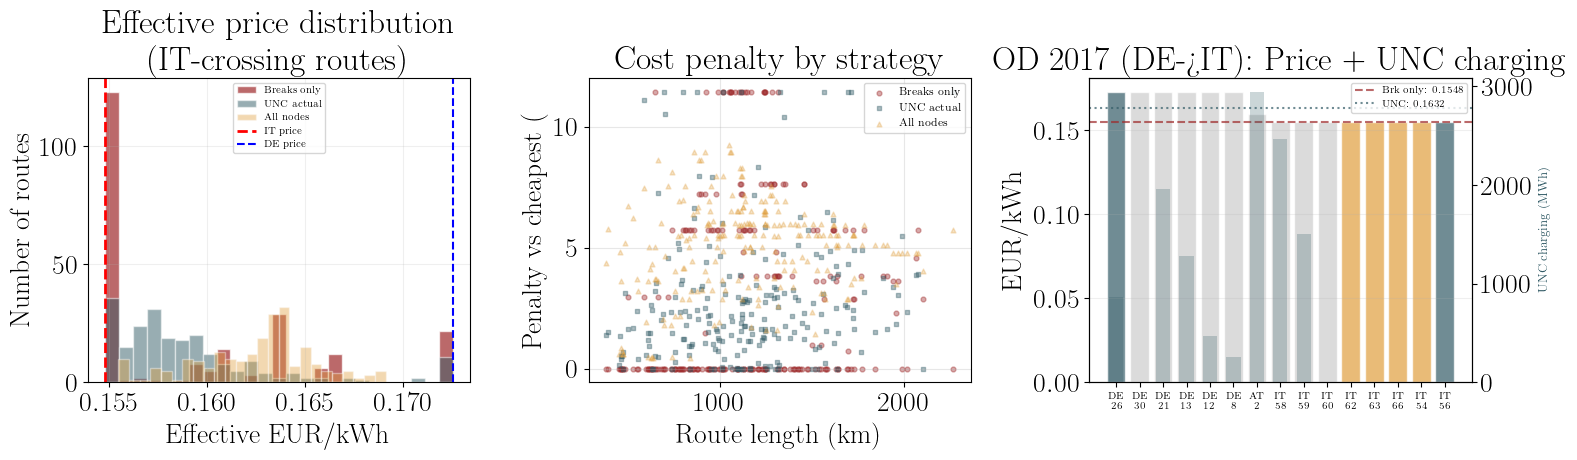

In [297]:
# ============================================================
# ANALYTICAL SINGLE-VEHICLE EXERCISE
# One BEV truck, one route, even distribution of charging at
# mandatory break locations.
# Compares analytical strategies WITH actual UNC model results.
# ============================================================
import numpy as np, re
from collections import defaultdict

# --- 1. Load vehicle specs ---
tv_data = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'TechVehicle.yaml')
tv_bev = [tv for tv in tv_data if tv['id'] == 1][0]

YEAR = 2040
GEN = 2040
gen_idx = GEN - Y_INIT
spec_cons = tv_bev['spec_cons'][gen_idx]
battery_kwh = tv_bev['tank_capacity'][gen_idx]

print(f"BEV specs (gen {GEN}): {spec_cons:.3f} kWh/km, battery {battery_kwh:.0f} kWh, "
      f"range {battery_kwh/spec_cons:.0f} km")

# --- 2. Load mandatory breaks ---
mb_data = load_yaml_file(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'MandatoryBreaks.yaml')
breaks_by_path = defaultdict(list)
for mb in mb_data:
    breaks_by_path[mb['path_id']].append(mb['latest_geo_id'])

# --- 3. Load Path.yaml ---
path_data = load_yaml_unsafe(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'Path.yaml')
path_info = {}
for p in path_data:
    path_info[p['id']] = {
        'sequence': p['sequence'],
        'cumulative_distance': [float(x) for x in p['cumulative_distance']],
        'length': float(p['length']),
    }

# --- 4. Load Odpair.yaml ---
od_data = load_yaml_file(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'Odpair.yaml')
od_to_path = {od['id']: od['path_id'] for od in od_data}
od_to_ft = {od['id']: (od['from'], od['to']) for od in od_data}

# --- 5. Electricity prices (Go RES) ---
elec_map = elec_prices_by_scenario['scenario_000']
yr_idx = YEAR - Y_INIT

def get_price(node_id):
    pa = elec_map.get((node_id, 2)) or elec_map.get((node_id, 1))
    return pa[min(yr_idx, len(pa) - 1)] if pa else None

# --- 6. Load UNC s_dict for actual optimizer charging distribution ---
print("Loading UNC s_dict (Go RES) for actual model results...")
S_KEY_PAT = re.compile(
    r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
)
unc_s_file = (BASE_PATH / 'results' / 'breaks_comparison_full' /
              'go_res_without_breaks' / 'go_res_without_breaks_2026-01-13_16-38-24_s_dict.yaml')
raw_unc = load_yaml_file(unc_s_file)

# Parse into per-route structure: {od_id: {year: {geo_id: energy_kwh}}}
unc_per_route = defaultdict(lambda: defaultdict(lambda: defaultdict(float)))
n_matched = 0
for k, v in raw_unc.items():
    m = S_KEY_PAT.match(str(k))
    if not m:
        continue
    year     = int(m.group(1))
    od_id    = int(m.group(3))
    geo_id   = int(m.group(5))
    tv_id    = int(m.group(6))
    fuel_id  = int(m.group(7))
    if tv_id != 1 or fuel_id != 0:   # electric + electricity only
        continue
    e_mwh = float(v)
    if e_mwh <= 0:
        continue
    if od_id not in at_it_odpair_ids:
        continue
    unc_per_route[od_id][year][geo_id] += e_mwh * 1000  # kWh
    n_matched += 1
print(f"  Matched electric AT-IT entries: {n_matched}")
del raw_unc  # free memory

# --- 7. Compute for ALL IT-crossing routes with breaks ---
results = []
for od_id in sorted(at_it_odpair_ids):
    pid = od_to_path.get(od_id)
    if pid is None or pid not in path_info:
        continue
    pi = path_info[pid]
    seq = pi['sequence']
    brk_nodes = breaks_by_path.get(pid, [])
    if not brk_nodes:
        continue

    o_geo, d_geo = od_to_ft.get(od_id, (0, 0))
    o_c, d_c = geoid2country.get(o_geo, '?'), geoid2country.get(d_geo, '?')
    if 'IT' not in (o_c, d_c) or o_c == d_c:
        continue

    brk_set_r = set(brk_nodes)
    allowed_r = brk_set_r | {seq[0], seq[-1]}
    total_e_r = spec_cons * pi['length']

    brk_only_p = [get_price(n) for n in brk_set_r if get_price(n) is not None]
    allowed_p  = [get_price(n) for n in allowed_r if get_price(n) is not None]
    all_p      = [get_price(n) for n in seq if get_price(n) is not None]
    if not brk_only_p or not all_p:
        continue

    # UNC actual effective price for this route
    unc_yr = unc_per_route.get(od_id, {}).get(YEAR, {})
    unc_cost_r = sum(unc_yr.get(n, 0) * (get_price(n) or 0) for n in seq)
    unc_energy_r = sum(unc_yr.get(n, 0) for n in seq)
    unc_eff_r = unc_cost_r / unc_energy_r if unc_energy_r > 0 else None

    results.append({
        'od_id': od_id, 'path_id': pid, 'o_c': o_c, 'd_c': d_c,
        'length_km': pi['length'], 'n_breaks': len(brk_nodes),
        'n_nodes': len(seq), 'n_allowed': len(allowed_r),
        'total_energy_kwh': total_e_r,
        'even_brk_only': np.mean(brk_only_p),
        'even_brk_ep':   np.mean(allowed_p),
        'even_all':      np.mean(all_p),
        'cheapest':      min(all_p),
        'most_exp':      max(all_p),
        'unc_actual':    unc_eff_r,
        'unc_energy':    unc_energy_r,
    })

n_with_unc = sum(1 for r in results if r['unc_actual'] is not None)
print(f"IT-crossing routes with breaks: {len(results)} ({n_with_unc} with UNC data)")

# --- 8. Detailed example: OD 2017 (DE->IT) ---
OD_PICK = 2017
PATH_PICK = od_to_path[OD_PICK]
pi = path_info[PATH_PICK]
seq = pi['sequence']
cum_dist = pi['cumulative_distance']
brk_set = set(breaks_by_path.get(PATH_PICK, []))
allowed = brk_set | {seq[0], seq[-1]}
total_e = spec_cons * pi['length']
unc_yr = unc_per_route.get(OD_PICK, {}).get(YEAR, {})

o_geo, d_geo = od_to_ft[OD_PICK]
o_c, d_c = geoid2country.get(o_geo, '?'), geoid2country.get(d_geo, '?')

print(f"\n{'='*90}")
print(f"ONE BEV TRUCK: OD {OD_PICK} ({o_c}->{d_c}), {pi['length']:.0f} km")
print(f"Energy: {total_e:.0f} kWh | {len(brk_set)} breaks | battery {battery_kwh:.0f} kWh")
print(f"{'='*90}")

e_brk = total_e / len(brk_set)
e_ep  = total_e / len(allowed)

print(f"\n{'#':>3} {'Node':>5} {'Ctry':>4} {'km':>8} {'Type':>6} {'Price':>10} "
      f"{'Brk-only':>10} {'Brk+EP':>10} {'UNC actual':>12}")
print("-" * 85)

cost_brk_only = 0
cost_brk_ep = 0
unc_cost_total = 0
unc_energy_total = 0
for i, n in enumerate(seq):
    c = geoid2country.get(n, '?')
    d = cum_dist[i]
    pr = get_price(n) or 0
    mark = "BREAK" if n in brk_set else ("ORIG" if n==seq[0] else ("DEST" if n==seq[-1] else ""))
    ch_brk = e_brk if n in brk_set else 0
    ch_ep  = e_ep  if n in allowed else 0
    unc_e  = unc_yr.get(n, 0)
    cost_brk_only += ch_brk * pr
    cost_brk_ep   += ch_ep * pr
    unc_cost_total += unc_e * pr
    unc_energy_total += unc_e
    # Show UNC in MWh for readability
    unc_str = f"{unc_e/1000:.1f} MWh" if unc_e > 0 else ""
    print(f"{i:>3} {n:>5} {c:>4} {d:>8.1f} {mark:>6} {pr:>10.5f} "
          f"{ch_brk:>10.0f} {ch_ep:>10.0f} {unc_str:>12}")

eff_brk_only = cost_brk_only / total_e
eff_brk_ep   = cost_brk_ep / total_e
eff_unc      = unc_cost_total / unc_energy_total if unc_energy_total > 0 else 0
all_node_p   = [get_price(n) for n in seq if get_price(n)]
eff_all      = np.mean(all_node_p)
cheapest_p   = min(all_node_p)

print(f"\n--- Effective EUR/kWh comparison ---")
print(f"  {'Strategy':<55} {'EUR/kWh':>10} {'Cost/trip':>12} {'vs cheap':>10}")
print(f"  {'-'*87}")
strategies = [
    ('Cheapest node only (lower bound)',          cheapest_p),
    ('Even at BREAK nodes only',                  eff_brk_only),
    ('Even at breaks + endpoints',                eff_brk_ep),
    ('UNC actual (optimizer, free choice)',        eff_unc),
    ('Even at ALL nodes on route',                eff_all),
    ('Most expensive node (upper bound)',          max(all_node_p)),
]
for label, price in strategies:
    cost = price * total_e
    pct = (price - cheapest_p) / cheapest_p * 100
    print(f"  {label:<55} {price:>10.5f} {cost:>12.2f} {pct:>+9.1f}%")

print(f"\n  Key insight: UNC ({eff_unc:.5f}) > Even@breaks ({eff_brk_only:.5f})")
print(f"  The optimizer charges in DE/AT (SOC constraints) at higher prices,")
print(f"  while break locations in IT have cheaper electricity.")

# --- 9. Summary statistics ---
res_unc = [r for r in results if r['unc_actual'] is not None]
print(f"\n{'='*90}")
print(f"SUMMARY: {len(res_unc)} IT-crossing routes with breaks AND UNC data")
print(f"{'='*90}")

for key, label in [('cheapest',      'Cheapest node'),
                    ('even_brk_only', 'Even at breaks only'),
                    ('even_brk_ep',   'Even at breaks+endpoints'),
                    ('unc_actual',    'UNC actual (optimizer)'),
                    ('even_all',      'Even at all nodes')]:
    vals = [r[key] for r in res_unc if r[key] is not None]
    if vals:
        print(f"  {label:<30} mean: {np.mean(vals):.5f}  "
              f"[{np.min(vals):.5f} - {np.max(vals):.5f}] EUR/kWh")

pen_brk = [(r['even_brk_only']-r['cheapest'])/r['cheapest']*100 for r in res_unc]
pen_ep  = [(r['even_brk_ep']-r['cheapest'])/r['cheapest']*100 for r in res_unc]
pen_unc = [(r['unc_actual']-r['cheapest'])/r['cheapest']*100 for r in res_unc]
pen_all = [(r['even_all']-r['cheapest'])/r['cheapest']*100 for r in res_unc]

print(f"\n  Penalty vs cheapest node:")
print(f"    Breaks only:      mean +{np.mean(pen_brk):.1f}%, max +{np.max(pen_brk):.1f}%")
print(f"    Breaks+endpoints: mean +{np.mean(pen_ep):.1f}%, max +{np.max(pen_ep):.1f}%")
print(f"    UNC actual:       mean +{np.mean(pen_unc):.1f}%, max +{np.max(pen_unc):.1f}%")
print(f"    All nodes:        mean +{np.mean(pen_all):.1f}%, max +{np.max(pen_all):.1f}%")

# How often is UNC more expensive than even@breaks?
unc_more_exp = sum(1 for r in res_unc if r['unc_actual'] > r['even_brk_only'] + 0.0001)
unc_cheaper  = sum(1 for r in res_unc if r['unc_actual'] < r['even_brk_only'] - 0.0001)
print(f"\n  UNC actual vs Even@breaks-only:")
print(f"    UNC more expensive: {unc_more_exp} ({unc_more_exp/len(res_unc)*100:.0f}%)")
print(f"    UNC cheaper:        {unc_cheaper} ({unc_cheaper/len(res_unc)*100:.0f}%)")

# --- 10. Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Distribution including UNC
ax = axes[0]
ax.hist([r['even_brk_only'] for r in res_unc], bins=25, alpha=0.7,
        color='#9e2a2b', label='Breaks only', edgecolor='white')
ax.hist([r['unc_actual'] for r in res_unc], bins=25, alpha=0.5,
        color='#335c67', label='UNC actual', edgecolor='white')
ax.hist([r['even_all'] for r in res_unc], bins=25, alpha=0.4,
        color='#e09f3e', label='All nodes', edgecolor='white')
ax.axvline(x=0.15480, color='red', linestyle='--', lw=2, label='IT price')
ax.axvline(x=0.17252, color='blue', linestyle='--', lw=1.5, label='DE price')
ax.set_xlabel('Effective EUR/kWh')
ax.set_ylabel('Number of routes')
ax.set_title('Effective price distribution\n(IT-crossing routes)')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.2)

# Panel 2: Penalty vs route length
ax = axes[1]
lengths_unc = [r['length_km'] for r in res_unc]
ax.scatter(lengths_unc, pen_brk, alpha=0.4, s=12, color='#9e2a2b', label='Breaks only')
ax.scatter(lengths_unc, pen_unc, alpha=0.4, s=12, color='#335c67', label='UNC actual', marker='s')
ax.scatter(lengths_unc, pen_all, alpha=0.3, s=12, color='#e09f3e', label='All nodes', marker='^')
ax.set_xlabel('Route length (km)')
ax.set_ylabel('Penalty vs cheapest (%)')
ax.set_title('Cost penalty by strategy')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Panel 3: Node-level for OD 2017 with UNC overlay
ax = axes[2]
node_p_list = [get_price(n) or 0 for n in seq]
colors = ['#e09f3e' if n in brk_set else ('#335c67' if n in {seq[0], seq[-1]} else '#cccccc')
          for n in seq]
ax.bar(range(len(seq)), node_p_list, color=colors, edgecolor='white', alpha=0.7)

# Annotate UNC charging amounts on top
max_unc = max(unc_yr.values()) if unc_yr else 1
ax2 = ax.twinx()
unc_bars = [unc_yr.get(n, 0)/1000 for n in seq]  # MWh
ax2.bar(range(len(seq)), unc_bars, alpha=0.25, color='#335c67', width=0.6)
ax2.set_ylabel('UNC charging (MWh)', color='#335c67', fontsize=9)

labels = [f"{geoid2country.get(n,'?')}\n{n}" for n in seq]
ax.set_xticks(range(len(seq)))
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel('EUR/kWh')
ax.set_title(f'OD 2017 (DE->IT): Price + UNC charging')
ax.axhline(y=eff_brk_only, color='#9e2a2b', linestyle='--', alpha=0.7,
           label=f'Brk only: {eff_brk_only:.4f}')
ax.axhline(y=eff_unc, color='#335c67', linestyle=':', alpha=0.7,
           label=f'UNC: {eff_unc:.4f}')
ax.legend(fontsize=7, loc='upper right')
ax.grid(True, alpha=0.2, axis='y')

plt.tight_layout()
save_path = BASE_PATH / 'figures' / 'analytical_even_charging_at_breaks.pdf'
plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
print(f"\nSaved to {save_path}")
plt.show()

In [298]:

# ============================================================
# ANALYTICAL SINGLE-VEHICLE EXERCISE
# One BEV truck, one route, even distribution of charging at
# mandatory break locations.
# Compares analytical strategies WITH actual UNC model results.
# ============================================================
import numpy as np, re
from collections import defaultdict

# --- 1. Load vehicle specs ---
tv_data = load_yaml_file(BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'TechVehicle.yaml')
tv_bev = [tv for tv in tv_data if tv['id'] == 1][0]

YEAR = 2040
GEN = 2040
gen_idx = GEN - Y_INIT
spec_cons = tv_bev['spec_cons'][gen_idx]
battery_kwh = tv_bev['tank_capacity'][gen_idx]

print(f"BEV specs (gen {GEN}): {spec_cons:.3f} kWh/km, battery {battery_kwh:.0f} kWh, "
      f"range {battery_kwh/spec_cons:.0f} km")


BEV specs (gen 2040): 1.290 kWh/km, battery 1187 kWh, range 920 km


In [299]:

# --- 2. Load mandatory breaks ---
mb_data = load_yaml_file(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'MandatoryBreaks.yaml')
breaks_by_path = defaultdict(list)
for mb in mb_data:
    breaks_by_path[mb['path_id']].append(mb['latest_geo_id'])

# --- 3. Load Path.yaml ---
path_data = load_yaml_unsafe(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'Path.yaml')
path_info = {}
for p in path_data:
    path_info[p['id']] = {
        'sequence': p['sequence'],
        'cumulative_distance': [float(x) for x in p['cumulative_distance']],
        'length': float(p['length']),
    }

# --- 4. Load Odpair.yaml ---
od_data = load_yaml_file(BASE_PATH / 'input_data' / 'fixed_nuts_2' / 'Odpair.yaml')
od_to_path = {od['id']: od['path_id'] for od in od_data}
od_to_ft = {od['id']: (od['from'], od['to']) for od in od_data}

# --- 5. Electricity prices (Go RES) ---
elec_map = elec_prices_by_scenario['scenario_000']
yr_idx = YEAR - Y_INIT

def get_price(node_id):
    pa = elec_map.get((node_id, 2)) or elec_map.get((node_id, 1))
    return pa[min(yr_idx, len(pa) - 1)] if pa else None

print(f"Loaded: {len(breaks_by_path)} paths with breaks, {len(path_info)} paths, {len(od_to_path)} OD pairs")


Loaded: 5169 paths with breaks, 6055 paths, 6055 OD pairs


In [300]:

# --- 6. Load UNC s_dict for actual optimizer charging distribution ---
print("Loading UNC s_dict (Go RES) for actual model results...")
S_KEY_PAT = re.compile(
    r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
)
unc_s_file = (BASE_PATH / 'results' / 'breaks_comparison_full' /
              'go_res_without_breaks' / 'go_res_without_breaks_2026-01-13_16-38-24_s_dict.yaml')
raw_unc = load_yaml_file(unc_s_file)
print(f"  Loaded {len(raw_unc)} entries from UNC s_dict")


Loading UNC s_dict (Go RES) for actual model results...
  Loaded 1200528 entries from UNC s_dict


In [301]:

# Parse into per-route structure: {od_id: {year: {geo_id: energy_kwh}}}
unc_per_route = defaultdict(lambda: defaultdict(lambda: defaultdict(float)))
n_matched = 0
for k, v in raw_unc.items():
    m = S_KEY_PAT.match(str(k))
    if not m:
        continue
    year     = int(m.group(1))
    od_id    = int(m.group(3))
    geo_id   = int(m.group(5))
    tv_id    = int(m.group(6))
    fuel_id  = int(m.group(7))
    if tv_id != 1 or fuel_id != 0:   # electric + electricity only
        continue
    e_mwh = float(v)
    if e_mwh <= 0:
        continue
    if od_id not in at_it_odpair_ids:
        continue
    unc_per_route[od_id][year][geo_id] += e_mwh * 1000  # kWh
    n_matched += 1
print(f"  Matched electric AT-IT entries: {n_matched}")
del raw_unc  # free memory


  Matched electric AT-IT entries: 566080


In [302]:

# --- 7. Compute for ALL IT-crossing routes with breaks ---
results = []
for od_id in sorted(at_it_odpair_ids):
    pid = od_to_path.get(od_id)
    if pid is None or pid not in path_info:
        continue
    pi = path_info[pid]
    seq = pi['sequence']
    brk_nodes = breaks_by_path.get(pid, [])
    if not brk_nodes:
        continue

    o_geo, d_geo = od_to_ft.get(od_id, (0, 0))
    o_c, d_c = geoid2country.get(o_geo, '?'), geoid2country.get(d_geo, '?')
    if 'IT' not in (o_c, d_c) or o_c == d_c:
        continue

    brk_set_r = set(brk_nodes)
    allowed_r = brk_set_r | {seq[0], seq[-1]}
    total_e_r = spec_cons * pi['length']

    brk_only_p = [get_price(n) for n in brk_set_r if get_price(n) is not None]
    allowed_p  = [get_price(n) for n in allowed_r if get_price(n) is not None]
    all_p      = [get_price(n) for n in seq if get_price(n) is not None]
    if not brk_only_p or not all_p:
        continue

    # UNC actual effective price for this route
    unc_yr = unc_per_route.get(od_id, {}).get(YEAR, {})
    unc_cost_r = sum(unc_yr.get(n, 0) * (get_price(n) or 0) for n in seq)
    unc_energy_r = sum(unc_yr.get(n, 0) for n in seq)
    unc_eff_r = unc_cost_r / unc_energy_r if unc_energy_r > 0 else None

    results.append({
        'od_id': od_id, 'path_id': pid, 'o_c': o_c, 'd_c': d_c,
        'length_km': pi['length'], 'n_breaks': len(brk_nodes),
        'n_nodes': len(seq), 'n_allowed': len(allowed_r),
        'total_energy_kwh': total_e_r,
        'even_brk_only': np.mean(brk_only_p),
        'even_brk_ep':   np.mean(allowed_p),
        'even_all':      np.mean(all_p),
        'cheapest':      min(all_p),
        'most_exp':      max(all_p),
        'unc_actual':    unc_eff_r,
        'unc_energy':    unc_energy_r,
    })

n_with_unc = sum(1 for r in results if r['unc_actual'] is not None)
print(f"IT-crossing routes with breaks: {len(results)} ({n_with_unc} with UNC data)")


IT-crossing routes with breaks: 360 (227 with UNC data)


In [303]:

# --- 8. Detailed example: OD 2017 (DE->IT) ---
OD_PICK = 2017
PATH_PICK = od_to_path[OD_PICK]
pi = path_info[PATH_PICK]
seq = pi['sequence']
cum_dist = pi['cumulative_distance']
brk_set = set(breaks_by_path.get(PATH_PICK, []))
allowed = brk_set | {seq[0], seq[-1]}
total_e = spec_cons * pi['length']
unc_yr = unc_per_route.get(OD_PICK, {}).get(YEAR, {})

o_geo, d_geo = od_to_ft[OD_PICK]
o_c, d_c = geoid2country.get(o_geo, '?'), geoid2country.get(d_geo, '?')

print(f"\n{'='*90}")
print(f"ONE BEV TRUCK: OD {OD_PICK} ({o_c}->{d_c}), {pi['length']:.0f} km")
print(f"Energy: {total_e:.0f} kWh | {len(brk_set)} breaks | battery {battery_kwh:.0f} kWh")
print(f"{'='*90}")

e_brk = total_e / len(brk_set)
e_ep  = total_e / len(allowed)

print(f"\n{'#':>3} {'Node':>5} {'Ctry':>4} {'km':>8} {'Type':>6} {'Price':>10} "
      f"{'Brk-only':>10} {'Brk+EP':>10} {'UNC actual':>12}")
print("-" * 85)

cost_brk_only = 0
cost_brk_ep = 0
unc_cost_total = 0
unc_energy_total = 0
for i, n in enumerate(seq):
    c = geoid2country.get(n, '?')
    d = cum_dist[i]
    pr = get_price(n) or 0
    mark = "BREAK" if n in brk_set else ("ORIG" if n==seq[0] else ("DEST" if n==seq[-1] else ""))
    ch_brk = e_brk if n in brk_set else 0
    ch_ep  = e_ep  if n in allowed else 0
    unc_e  = unc_yr.get(n, 0)
    cost_brk_only += ch_brk * pr
    cost_brk_ep   += ch_ep * pr
    unc_cost_total += unc_e * pr
    unc_energy_total += unc_e
    # Show UNC in MWh for readability
    unc_str = f"{unc_e/1000:.1f} MWh" if unc_e > 0 else ""
    print(f"{i:>3} {n:>5} {c:>4} {d:>8.1f} {mark:>6} {pr:>10.5f} "
          f"{ch_brk:>10.0f} {ch_ep:>10.0f} {unc_str:>12}")



ONE BEV TRUCK: OD 2017 (DE->IT), 1989 km
Energy: 2565 kWh | 4 breaks | battery 1187 kWh

  #  Node Ctry       km   Type      Price   Brk-only     Brk+EP   UNC actual
-------------------------------------------------------------------------------------
  0    26   DE      0.0   ORIG    0.17252          0        428    867.0 MWh
  1    30   DE    153.2           0.17252          0          0      0.0 MWh
  2    21   DE    281.0           0.17252          0          0   1964.7 MWh
  3    13   DE    428.2           0.17252          0          0   1286.9 MWh
  4    12   DE    539.8           0.17252          0          0    466.6 MWh
  5     8   DE    715.3           0.17252          0          0    259.6 MWh
  6     2   AT    840.6           0.15939          0          0   2941.6 MWh
  7    58   IT    908.1           0.15480          0          0   2465.7 MWh
  8    59   IT    981.7           0.15480          0          0   1504.0 MWh
  9    60   IT   1070.4           0.15480          0  

In [304]:

eff_brk_only = cost_brk_only / total_e
eff_brk_ep   = cost_brk_ep / total_e
eff_unc      = unc_cost_total / unc_energy_total if unc_energy_total > 0 else 0
all_node_p   = [get_price(n) for n in seq if get_price(n)]
eff_all      = np.mean(all_node_p)
cheapest_p   = min(all_node_p)

print(f"\n--- Effective EUR/kWh comparison ---")
print(f"  {'Strategy':<55} {'EUR/kWh':>10} {'Cost/trip':>12} {'vs cheap':>10}")
print(f"  {'-'*87}")
strategies = [
    ('Cheapest node only (lower bound)',          cheapest_p),
    ('Even at BREAK nodes only',                  eff_brk_only),
    ('Even at breaks + endpoints',                eff_brk_ep),
    ('UNC actual (optimizer, free choice)',        eff_unc),
    ('Even at ALL nodes on route',                eff_all),
    ('Most expensive node (upper bound)',          max(all_node_p)),
]
for label, price in strategies:
    cost = price * total_e
    pct = (price - cheapest_p) / cheapest_p * 100
    print(f"  {label:<55} {price:>10.5f} {cost:>12.2f} {pct:>+9.1f}%")

print(f"\n  Key insight: UNC ({eff_unc:.5f}) > Even@breaks ({eff_brk_only:.5f})")
print(f"  The optimizer charges in DE/AT (SOC constraints) at higher prices,")
print(f"  while break locations in IT have cheaper electricity.")



--- Effective EUR/kWh comparison ---
  Strategy                                                   EUR/kWh    Cost/trip   vs cheap
  ---------------------------------------------------------------------------------------
  Cheapest node only (lower bound)                           0.15480       397.12      +0.0%
  Even at BREAK nodes only                                   0.15480       397.12      +0.0%
  Even at breaks + endpoints                                 0.15775       404.69      +1.9%
  UNC actual (optimizer, free choice)                        0.16325       418.80      +5.5%
  Even at ALL nodes on route                                 0.16219       416.09      +4.8%
  Most expensive node (upper bound)                          0.17252       442.59     +11.4%

  Key insight: UNC (0.16325) > Even@breaks (0.15480)
  The optimizer charges in DE/AT (SOC constraints) at higher prices,
  while break locations in IT have cheaper electricity.


In [305]:

# --- 9. Summary statistics ---
res_unc = [r for r in results if r['unc_actual'] is not None]
print(f"\n{'='*90}")
print(f"SUMMARY: {len(res_unc)} IT-crossing routes with breaks AND UNC data")
print(f"{'='*90}")

for key, label in [('cheapest',      'Cheapest node'),
                    ('even_brk_only', 'Even at breaks only'),
                    ('even_brk_ep',   'Even at breaks+endpoints'),
                    ('unc_actual',    'UNC actual (optimizer)'),
                    ('even_all',      'Even at all nodes')]:
    vals = [r[key] for r in res_unc if r[key] is not None]
    if vals:
        print(f"  {label:<30} mean: {np.mean(vals):.5f}  "
              f"[{np.min(vals):.5f} - {np.max(vals):.5f}] EUR/kWh")

pen_brk = [(r['even_brk_only']-r['cheapest'])/r['cheapest']*100 for r in res_unc]
pen_ep  = [(r['even_brk_ep']-r['cheapest'])/r['cheapest']*100 for r in res_unc]
pen_unc = [(r['unc_actual']-r['cheapest'])/r['cheapest']*100 for r in res_unc]
pen_all = [(r['even_all']-r['cheapest'])/r['cheapest']*100 for r in res_unc]

print(f"\n  Penalty vs cheapest node:")
print(f"    Breaks only:      mean +{np.mean(pen_brk):.1f}%, max +{np.max(pen_brk):.1f}%")
print(f"    Breaks+endpoints: mean +{np.mean(pen_ep):.1f}%, max +{np.max(pen_ep):.1f}%")
print(f"    UNC actual:       mean +{np.mean(pen_unc):.1f}%, max +{np.max(pen_unc):.1f}%")
print(f"    All nodes:        mean +{np.mean(pen_all):.1f}%, max +{np.max(pen_all):.1f}%")

# How often is UNC more expensive than even@breaks?
unc_more_exp = sum(1 for r in res_unc if r['unc_actual'] > r['even_brk_only'] + 0.0001)
unc_cheaper  = sum(1 for r in res_unc if r['unc_actual'] < r['even_brk_only'] - 0.0001)
print(f"\n  UNC actual vs Even@breaks-only:")
print(f"    UNC more expensive: {unc_more_exp} ({unc_more_exp/len(res_unc)*100:.0f}%)")
print(f"    UNC cheaper:        {unc_cheaper} ({unc_cheaper/len(res_unc)*100:.0f}%)")



SUMMARY: 227 IT-crossing routes with breaks AND UNC data
  Cheapest node                  mean: 0.15480  [0.15480 - 0.15480] EUR/kWh
  Even at breaks only            mean: 0.15935  [0.15480 - 0.17252] EUR/kWh
  Even at breaks+endpoints       mean: 0.16236  [0.15572 - 0.16898] EUR/kWh
  UNC actual (optimizer)         mean: 0.15906  [0.15480 - 0.17252] EUR/kWh
  Even at all nodes              mean: 0.16252  [0.15545 - 0.16909] EUR/kWh

  Penalty vs cheapest node:
    Breaks only:      mean +2.9%, max +11.4%
    Breaks+endpoints: mean +4.9%, max +9.2%
    UNC actual:       mean +2.8%, max +11.4%
    All nodes:        mean +5.0%, max +9.2%

  UNC actual vs Even@breaks-only:
    UNC more expensive: 127 (56%)
    UNC cheaper:        91 (40%)



Saved to c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\analytical_even_charging_at_breaks.pdf


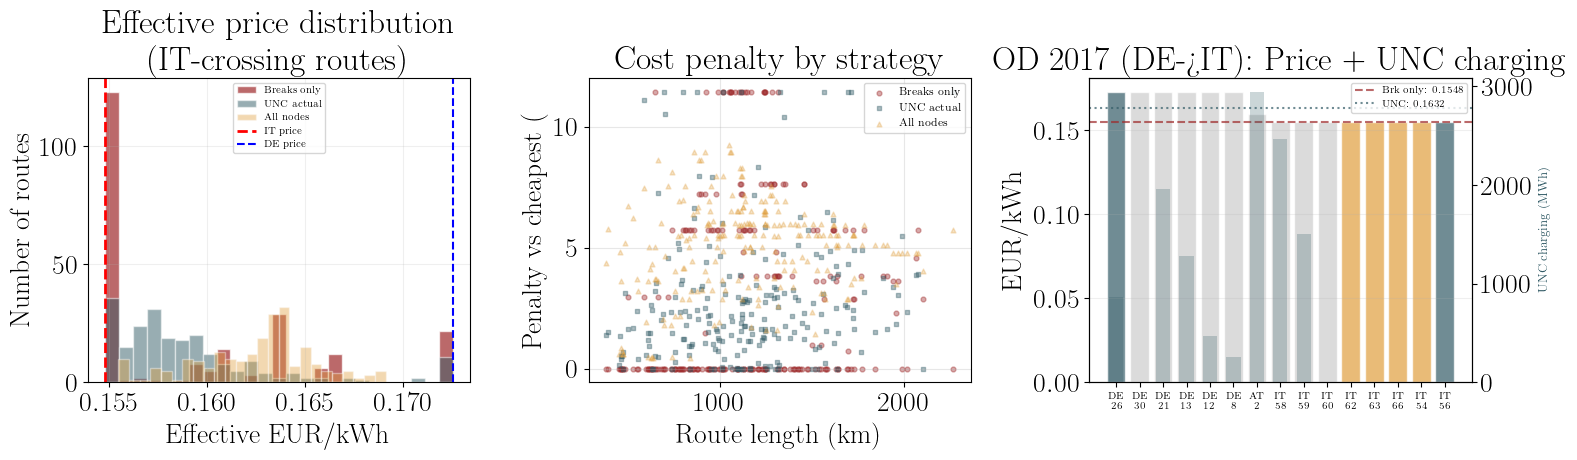

In [306]:

# --- 10. Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Distribution including UNC
ax = axes[0]
ax.hist([r['even_brk_only'] for r in res_unc], bins=25, alpha=0.7,
        color='#9e2a2b', label='Breaks only', edgecolor='white')
ax.hist([r['unc_actual'] for r in res_unc], bins=25, alpha=0.5,
        color='#335c67', label='UNC actual', edgecolor='white')
ax.hist([r['even_all'] for r in res_unc], bins=25, alpha=0.4,
        color='#e09f3e', label='All nodes', edgecolor='white')
ax.axvline(x=0.15480, color='red', linestyle='--', lw=2, label='IT price')
ax.axvline(x=0.17252, color='blue', linestyle='--', lw=1.5, label='DE price')
ax.set_xlabel('Effective EUR/kWh')
ax.set_ylabel('Number of routes')
ax.set_title('Effective price distribution\n(IT-crossing routes)')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.2)

# Panel 2: Penalty vs route length
ax = axes[1]
lengths_unc = [r['length_km'] for r in res_unc]
ax.scatter(lengths_unc, pen_brk, alpha=0.4, s=12, color='#9e2a2b', label='Breaks only')
ax.scatter(lengths_unc, pen_unc, alpha=0.4, s=12, color='#335c67', label='UNC actual', marker='s')
ax.scatter(lengths_unc, pen_all, alpha=0.3, s=12, color='#e09f3e', label='All nodes', marker='^')
ax.set_xlabel('Route length (km)')
ax.set_ylabel('Penalty vs cheapest (%)')
ax.set_title('Cost penalty by strategy')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Panel 3: Node-level for OD 2017 with UNC overlay
ax = axes[2]
node_p_list = [get_price(n) or 0 for n in seq]
colors = ['#e09f3e' if n in brk_set else ('#335c67' if n in {seq[0], seq[-1]} else '#cccccc')
          for n in seq]
ax.bar(range(len(seq)), node_p_list, color=colors, edgecolor='white', alpha=0.7)

# Annotate UNC charging amounts on top
max_unc = max(unc_yr.values()) if unc_yr else 1
ax2 = ax.twinx()
unc_bars = [unc_yr.get(n, 0)/1000 for n in seq]  # MWh
ax2.bar(range(len(seq)), unc_bars, alpha=0.25, color='#335c67', width=0.6)
ax2.set_ylabel('UNC charging (MWh)', color='#335c67', fontsize=9)

labels = [f"{geoid2country.get(n,'?')}\n{n}" for n in seq]
ax.set_xticks(range(len(seq)))
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel('EUR/kWh')
ax.set_title(f'OD 2017 (DE->IT): Price + UNC charging')
ax.axhline(y=eff_brk_only, color='#9e2a2b', linestyle='--', alpha=0.7,
           label=f'Brk only: {eff_brk_only:.4f}')
ax.axhline(y=eff_unc, color='#335c67', linestyle=':', alpha=0.7,
           label=f'UNC: {eff_unc:.4f}')
ax.legend(fontsize=7, loc='upper right')
ax.grid(True, alpha=0.2, axis='y')

plt.tight_layout()
save_path = BASE_PATH / 'figures' / 'analytical_even_charging_at_breaks.pdf'
plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.savefig(save_path.with_suffix('.svg'), bbox_inches='tight')
print(f"\nSaved to {save_path}")
plt.show()


In [307]:

import yaml
from pathlib import Path
from collections import defaultdict

BASE_PATH = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

# Build p_r_k_g position -> geo_element_id mapping
# The s variable in JuMP uses a DenseAxisArray with sorted p_r_k_g_pairs as an axis
# We need to reconstruct this to decode CartesianIndex position -> geo_element_id

input_path = BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000'

# Load paths with their sequences
print("Loading Path.yaml...")
with open(input_path / 'Path.yaml') as f:
    paths_data = yaml.safe_load(f)

# Build path -> sequence of geo_element_ids
path_sequences = {}
for p in paths_data:
    path_id = p['id']
    sequence = [el['id'] for el in p.get('sequence', [])]
    path_sequences[path_id] = sequence

print(f"Loaded {len(path_sequences)} paths")

# Load odpairs
print("Loading Odpair.yaml...")
with open(input_path / 'Odpair.yaml') as f:
    odpairs_data = yaml.safe_load(f)

print(f"Loaded {len(odpairs_data)} odpairs")

# Build p_r_k_g_pairs set: (product_id, odpair_id, path_id, geo_element_id)
prkg_set = set()
for od in odpairs_data:
    prod_id = 0  # single product
    od_id = od['id']
    path_id = int(od['path_id'])
    if path_id in path_sequences:
        for geo_id in path_sequences[path_id]:
            prkg_set.add((prod_id, od_id, path_id, geo_id))

print(f"Built {len(prkg_set)} p_r_k_g tuples")

# Sort lexicographically (same as Julia's default)
prkg_sorted = sorted(prkg_set)

# Build 1-indexed position -> geo_element_id mapping
prkg_pos_to_geo = {i+1: t[3] for i, t in enumerate(prkg_sorted)}
print(f"Lookup table: {len(prkg_pos_to_geo)} entries")
print(f"Max position: {max(prkg_pos_to_geo.keys())}")
print(f"Sample: pos 1 -> geo {prkg_pos_to_geo[1]}, pos 100 -> geo {prkg_pos_to_geo[100]}")


Loading Path.yaml...


TypeError: 'int' object is not subscriptable

In [308]:

import yaml
from pathlib import Path
from collections import defaultdict

BASE_PATH = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')
input_path = BASE_PATH / 'input_data' / 'uncertainty_scenarios' / 'scenario_000'

# Load paths with their sequences (sequence is list of geo element IDs)
print("Loading Path.yaml...")
with open(input_path / 'Path.yaml') as f:
    paths_data = yaml.safe_load(f)

path_sequences = {}
for p in paths_data:
    path_id = p['id']
    sequence = p.get('sequence', [])  # already a list of ints
    path_sequences[path_id] = sequence

print(f"Loaded {len(path_sequences)} paths")

# Load odpairs
print("Loading Odpair.yaml...")
with open(input_path / 'Odpair.yaml') as f:
    odpairs_data = yaml.safe_load(f)

print(f"Loaded {len(odpairs_data)} odpairs")

# Build p_r_k_g_pairs set: (product_id, odpair_id, path_id, geo_element_id)
prkg_set = set()
for od in odpairs_data:
    prod_id = 0  # single product in this model
    od_id = od['id']
    path_id = int(od['path_id'])
    if path_id in path_sequences:
        for geo_id in path_sequences[path_id]:
            prkg_set.add((prod_id, od_id, path_id, geo_id))
    else:
        pass  # path not found

print(f"Built {len(prkg_set)} p_r_k_g tuples")

# Sort lexicographically (same ordering as Julia)
prkg_sorted = sorted(prkg_set)

# Build 1-indexed position -> geo_element_id mapping
prkg_pos_to_geo = {i+1: t[3] for i, t in enumerate(prkg_sorted)}
print(f"Lookup table: {len(prkg_pos_to_geo)} entries, max position: {max(prkg_pos_to_geo.keys())}")
print(f"Sample: pos 1 -> geo {prkg_pos_to_geo[1]}, pos 100 -> geo {prkg_pos_to_geo[100]}, pos 20724 -> geo {prkg_pos_to_geo.get(20724, 'N/A')}")


Loading Path.yaml...
Loaded 2244 paths
Loading Odpair.yaml...
Loaded 2244 odpairs
Built 21549 p_r_k_g tuples
Lookup table: 21549 entries, max position: 21549
Sample: pos 1 -> geo 0, pos 100 -> geo 0, pos 20724 -> geo 22


In [309]:

# Load s_dict for all 4 scenarios and aggregate BEV energy by (year_idx, geo_id)
import re

RESULTS_PATH = BASE_PATH / 'results' / 'uncertainty_scenarios_v2'

SCENARIOS = {
    'scenario_000': {'name': 'Go RES', 'carbon_price_2040': 500, 'color': '#1b4965'},
    'scenario_001': {'name': 'NECPEssentials', 'carbon_price_2040': 250, 'color': '#e09f3e'},
    'scenario_002': {'name': 'REPowerEU++', 'carbon_price_2040': 350, 'color': '#2a9d8f'},
    'scenario_003': {'name': 'Trinity', 'carbon_price_2040': 400, 'color': '#c1121f'},
}

def find_latest_result_file(folder, pattern):
    """Find latest file matching pattern in folder."""
    from pathlib import Path
    folder = Path(folder)
    if not folder.exists():
        return None
    matches = sorted(folder.glob(f'*{pattern}*'), key=lambda p: p.stat().st_mtime)
    return str(matches[-1]) if matches else None

def parse_cartesian_index(key_str):
    if isinstance(key_str, str) and key_str.startswith('CartesianIndex('):
        match = re.search(r'CartesianIndex\(([^)]+)\)', key_str)
        if match:
            nums = [int(x.strip()) for x in match.group(1).split(',')]
            return tuple(nums)
    return None

# Load s_dict for each scenario and aggregate BEV energy by (year_idx, geo_id)
s_energy_results = {}

for scenario_id, config in SCENARIOS.items():
    scenario_folder = RESULTS_PATH / scenario_id
    if not scenario_folder.exists():
        print(f"Warning: {scenario_folder} not found")
        continue
    
    s_file = find_latest_result_file(scenario_folder, 's_dict')
    if not s_file:
        print(f"Warning: No s_dict found for {scenario_id}")
        continue
    
    print(f"Loading {scenario_id} s_dict: {Path(s_file).name}...")
    
    # Stream-parse line by line (faster than loading full YAML for large files)
    energy_by_year_geo = defaultdict(float)
    ci_re = re.compile(r'CartesianIndex\((\d+),\s*(\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)')
    
    total_lines = 0
    bev_lines = 0
    
    with open(s_file, 'r') as f:
        for line in f:
            total_lines += 1
            m = ci_re.match(line.strip())
            if not m:
                continue
            
            yr_pos = int(m.group(1))
            prkg_pos = int(m.group(2))
            tv_pos = int(m.group(3))
            fl_pos = int(m.group(4))
            # gen_pos = int(m.group(5))  # not needed
            val = float(m.group(6))
            
            # BEV electric only: tv_pos=2 (BEV), fl_pos in [1,2] (slow/fast electric)
            if tv_pos != 2 or fl_pos not in [1, 2]:
                continue
            
            bev_lines += 1
            geo_id = prkg_pos_to_geo.get(prkg_pos)
            if geo_id is None:
                continue
            
            energy_by_year_geo[(yr_pos, geo_id)] += val
    
    s_energy_results[scenario_id] = {
        's_energy': dict(energy_by_year_geo),
        'config': config
    }
    print(f"  {scenario_id}: {total_lines} total entries, {bev_lines} BEV entries, {len(energy_by_year_geo)} (year,geo) pairs")

print(f"\nLoaded s_dict energy for {len(s_energy_results)} scenarios")


Loading scenario_000 s_dict: scenario_000_cs_2026-02-16_18-37-25_q_fuel_infr_plus_dict.yaml...
  scenario_000: 570 total entries, 0 BEV entries, 0 (year,geo) pairs
Loading scenario_001 s_dict: scenario_001_cs_2026-02-16_19-48-42_q_fuel_infr_plus_dict.yaml...
  scenario_001: 557 total entries, 0 BEV entries, 0 (year,geo) pairs
Loading scenario_002 s_dict: scenario_002_cs_2026-02-16_21-26-02_q_fuel_infr_plus_dict.yaml...
  scenario_002: 535 total entries, 0 BEV entries, 0 (year,geo) pairs
Loading scenario_003 s_dict: scenario_003_cs_2026-02-16_22-46-04_q_fuel_infr_plus_dict.yaml...
  scenario_003: 588 total entries, 0 BEV entries, 0 (year,geo) pairs

Loaded s_dict energy for 4 scenarios


In [310]:

# Fix: use specific pattern to match only _s_dict.yaml files
s_energy_results = {}

for scenario_id, config in SCENARIOS.items():
    scenario_folder = RESULTS_PATH / scenario_id
    if not scenario_folder.exists():
        print(f"Warning: {scenario_folder} not found")
        continue
    
    # Find specifically _s_dict.yaml (not q_fuel_infr_plus_dict or other *s_dict* matches)
    matches = sorted(scenario_folder.glob('*_s_dict.yaml'), key=lambda p: p.stat().st_mtime)
    # Filter out any that contain 'q_fuel' or 'plus' in the name
    matches = [m for m in matches if 'q_fuel' not in m.name and 'plus' not in m.name]
    
    if not matches:
        print(f"Warning: No s_dict found for {scenario_id}")
        continue
    
    s_file = matches[-1]
    print(f"Loading {scenario_id}: {s_file.name}...")
    
    energy_by_year_geo = defaultdict(float)
    ci_re = re.compile(r'CartesianIndex\((\d+),\s*(\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)')
    
    total_lines = 0
    bev_lines = 0
    
    with open(s_file, 'r') as f:
        for line in f:
            total_lines += 1
            m = ci_re.match(line.strip())
            if not m:
                continue
            
            yr_pos = int(m.group(1))
            prkg_pos = int(m.group(2))
            tv_pos = int(m.group(3))
            fl_pos = int(m.group(4))
            val = float(m.group(6))
            
            # BEV electric only: tv_pos=2 (BEV), fl_pos in [1,2] (slow/fast electric)
            if tv_pos != 2 or fl_pos not in [1, 2]:
                continue
            
            bev_lines += 1
            geo_id = prkg_pos_to_geo.get(prkg_pos)
            if geo_id is None:
                continue
            
            energy_by_year_geo[(yr_pos, geo_id)] += val
    
    s_energy_results[scenario_id] = {
        's_energy': dict(energy_by_year_geo),
        'config': config
    }
    print(f"  {total_lines} total, {bev_lines} BEV electric, {len(energy_by_year_geo)} (year,geo) pairs")

print(f"\nLoaded s energy for {len(s_energy_results)} scenarios")


Loading scenario_000: scenario_000_cs_2026-02-16_18-37-25_s_dict.yaml...
  198209 total, 109076 BEV electric, 722 (year,geo) pairs
Loading scenario_001: scenario_001_cs_2026-02-16_19-48-42_s_dict.yaml...
  192181 total, 93911 BEV electric, 702 (year,geo) pairs
Loading scenario_002: scenario_002_cs_2026-02-16_21-26-02_s_dict.yaml...
  208270 total, 122595 BEV electric, 729 (year,geo) pairs
Loading scenario_003: scenario_003_cs_2026-02-16_22-46-04_s_dict.yaml...
  196803 total, 99284 BEV electric, 693 (year,geo) pairs

Loaded s energy for 4 scenarios


In [311]:

# Check the data: total energy by year for scenario_000
YEAR_MAPPING = {i: 2020 + (i-1) * 4 for i in range(1, 15)}

s_data = s_energy_results['scenario_000']['s_energy']
year_totals = defaultdict(float)
for (yr_pos, geo_id), val in s_data.items():
    year = YEAR_MAPPING.get(yr_pos, yr_pos)
    year_totals[year] += val

print("scenario_000 BEV energy by year (raw model units):")
for year in sorted(year_totals.keys()):
    print(f"  {year}: {year_totals[year]:,.1f}")

# Check what the q_results look like for comparison
print("\nFor reference, q_fuel_infr_plus totals (from already-loaded q_results):")
if 'q_results' in dir() and q_results:
    q_data = q_results['scenario_000']['q']
    q_year_totals = defaultdict(float)
    for key_str, val in q_data.items():
        parsed = parse_cartesian_index(key_str)
        if parsed and len(parsed) == 3:
            yr_idx, fl_idx, geo_id = parsed
            if fl_idx in [1, 2]:  # electric only
                year = YEAR_MAPPING.get(yr_idx, yr_idx)
                q_year_totals[year] += float(val) if isinstance(val, str) else val
    for year in sorted(q_year_totals.keys()):
        print(f"  {year}: {q_year_totals[year]:,.1f}")
else:
    print("  (q_results not loaded in kernel)")


scenario_000 BEV energy by year (raw model units):
  2028: 124,262.2
  2032: 201,907.8
  2036: 825,681.0
  2040: 1,168,563.4
  2044: 1,542,864.2
  2048: 1,982,089.6
  2052: 2,476,385.3
  2056: 2,614,428.4
  2060: 748,896.7

For reference, q_fuel_infr_plus totals (from already-loaded q_results):
  2028: 90,960.5
  2032: 93,010.6
  2036: 130,214.9
  2040: 130,472.8
  2044: 142,428.0
  2048: 167,132.9
  2052: 188,088.2
  2056: 52,527.8


In [312]:

import numpy as np
from scipy.ndimage import gaussian_filter1d

# Year mapping
YEAR_MAPPING = {i: 2020 + (i-1) * 4 for i in range(1, 15)}
YEAR_TO_INDEX = {v: k for k, v in YEAR_MAPPING.items()}

def calculate_energy_by_latitude_from_s(s_energy, geo_id_to_lat, target_year):
    """Calculate BEV energy charged aggregated by latitude for a specific year.
    s_energy: dict of {(year_pos, geo_id): energy_value}
    Returns: list of (latitude, GWh) sorted by latitude
    """
    target_year_idx = YEAR_TO_INDEX.get(target_year)
    if target_year_idx is None:
        print(f"Warning: Year {target_year} not found")
        return []
    
    energy_by_lat = defaultdict(float)
    for (yr_pos, geo_id), val in s_energy.items():
        if yr_pos != target_year_idx:
            continue
        if geo_id not in geo_id_to_lat:
            continue
        lat = geo_id_to_lat[geo_id]
        energy_by_lat[lat] += val
    
    # Convert to GWh (model values appear to be in MWh based on magnitude)
    result = [(lat, mwh / 1e3) for lat, mwh in energy_by_lat.items()]
    result.sort(key=lambda x: x[0])
    return result

# Quick test: check magnitudes for scenario_000 at 2040
test = calculate_energy_by_latitude_from_s(
    s_energy_results['scenario_000']['s_energy'], 
    geo_id_to_lat, 
    2040
)
if test:
    total = sum(x[1] for x in test)
    max_val = max(x[1] for x in test)
    print(f"scenario_000, 2040: {len(test)} latitude bins, total={total:.1f} GWh, max={max_val:.1f} GWh")
    # Show top 5 latitudes
    test_sorted = sorted(test, key=lambda x: -x[1])[:5]
    for lat, gwh in test_sorted:
        print(f"  lat {lat:.1f}: {gwh:.1f} GWh")


scenario_000, 2040: 81 latitude bins, total=1168.6 GWh, max=92.5 GWh
  lat 45.6: 92.5 GWh
  lat 46.7: 68.5 GWh
  lat 48.1: 67.6 GWh
  lat 46.1: 65.7 GWh
  lat 53.8: 62.7 GWh


Saved to C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\charging_by_latitude_multi_year.pdf


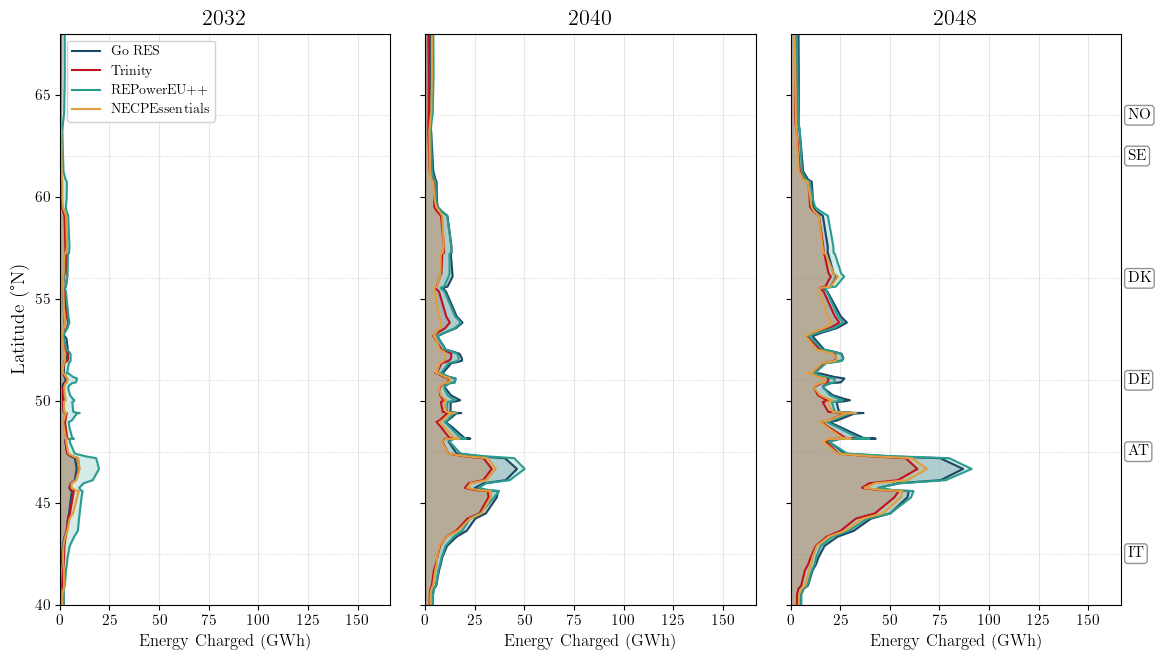

In [313]:

import matplotlib.pyplot as plt

def plot_energy_by_latitude_multi_year(s_energy_results, geo_id_to_lat,
                                       years=[2032, 2040, 2048],
                                       figsize=(12, 7),
                                       save_path=None):
    """
    Plot BEV energy charged by latitude for multiple years side-by-side.
    Uses s variable (actual energy charged), not q (installed capacity).
    Axes: latitude on Y-axis (north at top), GWh on X-axis.
    """
    n_years = len(years)
    fig, axes = plt.subplots(1, n_years, figsize=figsize, sharey=True)
    if n_years == 1:
        axes = [axes]
    
    # Scenario order (sorted by carbon price, highest first)
    scenario_order = ['scenario_000', 'scenario_003', 'scenario_002', 'scenario_001']
    
    # Country reference latitudes
    country_lats = {'IT': 42.5, 'AT': 47.5, 'DE': 51.0, 'DK': 56.0, 'SE': 62.0, 'NO': 64.0}
    
    # First pass: calculate data and find max for consistent x-axis
    all_lat_data = {}
    global_max = 0
    for year in years:
        all_lat_data[year] = {}
        for scenario_id, data in s_energy_results.items():
            lat_data = calculate_energy_by_latitude_from_s(data['s_energy'], geo_id_to_lat, year)
            if lat_data:
                all_lat_data[year][scenario_id] = lat_data
                max_val = max(x[1] for x in lat_data)
                if max_val > global_max:
                    global_max = max_val
    
    max_gwh = global_max * 1.1  # 10% headroom
    
    # Second pass: plot
    for i, (year, ax) in enumerate(zip(years, axes)):
        lat_data = all_lat_data[year]
        
        for scenario_id in scenario_order:
            if scenario_id not in lat_data:
                continue
            
            config = s_energy_results[scenario_id]['config']
            data = lat_data[scenario_id]
            
            if len(data) < 3:
                continue
            
            lats = np.array([x[0] for x in data])
            gwh = np.array([x[1] for x in data])
            
            sort_idx = np.argsort(lats)
            lat_sorted = lats[sort_idx]
            gwh_sorted = gwh[sort_idx]
            
            # Apply Gaussian smoothing
            gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
            
            label = config['name'] if i == 0 else None
            
            ax.fill_betweenx(lat_sorted, 0, gwh_smoothed, color=config['color'], alpha=0.2)
            ax.plot(gwh_smoothed, lat_sorted, color=config['color'], linewidth=1.5, label=label)
        
        # Country reference lines
        for country, lat in country_lats.items():
            ax.axhline(lat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        
        ax.set_title(f'{year}', fontsize=16, fontweight='bold')
        ax.set_xlabel('Energy Charged (GWh)', fontsize=12)
        ax.set_xlim(0, max_gwh)
        ax.set_ylim(40, 68)
        ax.grid(True, alpha=0.3, axis='x')
        ax.tick_params(axis='both', labelsize=11)
    
    # Y-axis label on leftmost panel
    axes[0].set_ylabel('Latitude (\u00b0N)', fontsize=14)
    
    # Country labels on rightmost panel
    ax_right = axes[-1]
    for country, lat in country_lats.items():
        ax_right.text(1.02, lat, country, transform=ax_right.get_yaxis_transform(),
                     fontsize=11, fontweight='bold', va='center', ha='left',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', 
                              edgecolor='#888', alpha=0.9))
    
    # Legend
    axes[0].legend(loc='upper left', fontsize=10, framealpha=0.9)
    
    plt.tight_layout()
    
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
        fig.savefig(str(save_path).replace('.pdf', '.svg'), bbox_inches='tight')
        print(f"Saved to {save_path}")
    
    plt.show()

# Generate the plot
plot_energy_by_latitude_multi_year(
    s_energy_results, geo_id_to_lat,
    years=[2032, 2040, 2048],
    figsize=(12, 7),
    save_path=BASE_PATH / 'figures' / 'charging_by_latitude_multi_year.pdf'
)


Saved to C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\charging_by_latitude_multi_year.pdf


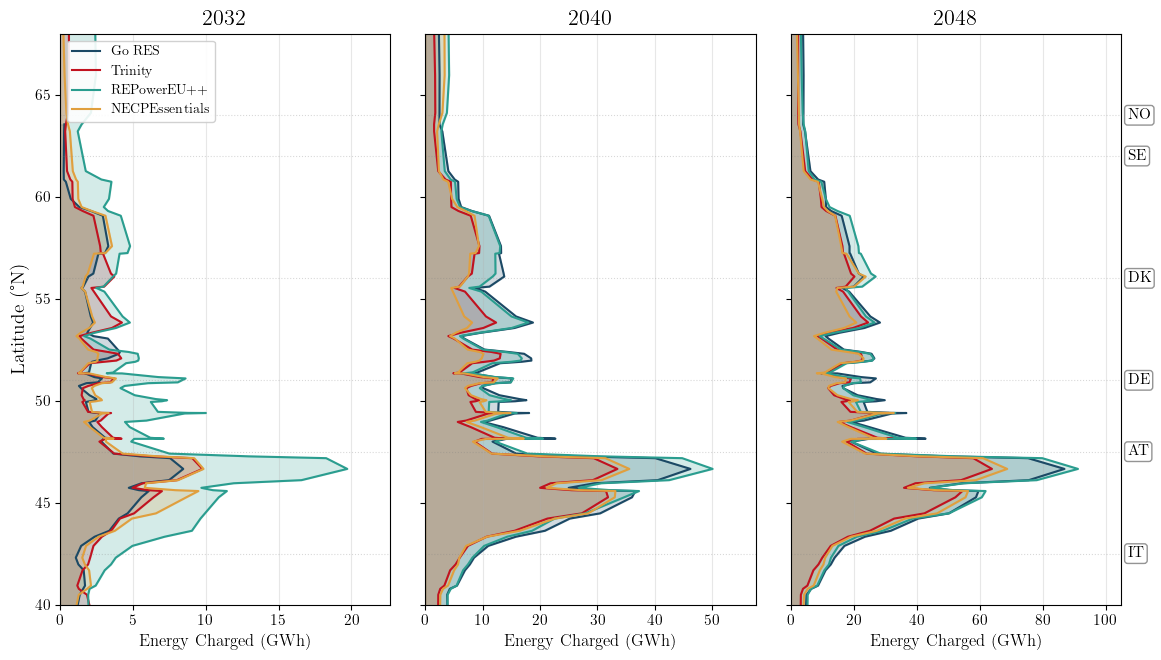

In [314]:

# Re-plot with independent x-axis per panel (no shared xlim)
def plot_energy_by_latitude_multi_year_v2(s_energy_results, geo_id_to_lat,
                                          years=[2032, 2040, 2048],
                                          figsize=(12, 7),
                                          save_path=None):
    """
    Plot BEV energy charged by latitude, each panel with its own x-scale.
    """
    n_years = len(years)
    fig, axes = plt.subplots(1, n_years, figsize=figsize, sharey=True)
    if n_years == 1:
        axes = [axes]
    
    scenario_order = ['scenario_000', 'scenario_003', 'scenario_002', 'scenario_001']
    country_lats = {'IT': 42.5, 'AT': 47.5, 'DE': 51.0, 'DK': 56.0, 'SE': 62.0, 'NO': 64.0}
    
    # Calculate data
    all_lat_data = {}
    for year in years:
        all_lat_data[year] = {}
        for scenario_id, data in s_energy_results.items():
            lat_data = calculate_energy_by_latitude_from_s(data['s_energy'], geo_id_to_lat, year)
            if lat_data:
                all_lat_data[year][scenario_id] = lat_data
    
    for i, (year, ax) in enumerate(zip(years, axes)):
        lat_data = all_lat_data[year]
        panel_max = 0
        
        for scenario_id in scenario_order:
            if scenario_id not in lat_data:
                continue
            config = s_energy_results[scenario_id]['config']
            data = lat_data[scenario_id]
            if len(data) < 3:
                continue
            lats = np.array([x[0] for x in data])
            gwh = np.array([x[1] for x in data])
            sort_idx = np.argsort(lats)
            lat_sorted = lats[sort_idx]
            gwh_sorted = gwh[sort_idx]
            gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
            panel_max = max(panel_max, gwh_smoothed.max())
            label = config['name'] if i == 0 else None
            ax.fill_betweenx(lat_sorted, 0, gwh_smoothed, color=config['color'], alpha=0.2)
            ax.plot(gwh_smoothed, lat_sorted, color=config['color'], linewidth=1.5, label=label)
        
        for country, lat in country_lats.items():
            ax.axhline(lat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        
        ax.set_title(f'{year}', fontsize=16, fontweight='bold')
        ax.set_xlabel('Energy Charged (GWh)', fontsize=12)
        ax.set_xlim(0, panel_max * 1.15)  # Per-panel scale
        ax.set_ylim(40, 68)
        ax.grid(True, alpha=0.3, axis='x')
        ax.tick_params(axis='both', labelsize=11)
    
    axes[0].set_ylabel('Latitude (\u00b0N)', fontsize=14)
    ax_right = axes[-1]
    for country, lat in country_lats.items():
        ax_right.text(1.02, lat, country, transform=ax_right.get_yaxis_transform(),
                     fontsize=11, fontweight='bold', va='center', ha='left',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', 
                              edgecolor='#888', alpha=0.9))
    axes[0].legend(loc='upper left', fontsize=10, framealpha=0.9)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
        fig.savefig(str(save_path).replace('.pdf', '.svg'), bbox_inches='tight')
        print(f"Saved to {save_path}")
    plt.show()

plot_energy_by_latitude_multi_year_v2(
    s_energy_results, geo_id_to_lat,
    years=[2032, 2040, 2048],
    figsize=(12, 7),
    save_path=BASE_PATH / 'figures' / 'charging_by_latitude_multi_year.pdf'
)


In [315]:

# Check BEV energy totals per scenario for 2032
print("=== BEV Energy Charged (GWh) by scenario ===")
for scenario_id in ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']:
    data = s_energy_results[scenario_id]
    config = data['config']
    yr_idx = YEAR_TO_INDEX[2032]  # year index for 2032
    
    total = sum(val for (yr, geo), val in data['s_energy'].items() if yr == yr_idx)
    total_gwh = total / 1e3
    
    print(f"  {config['name']:20s} (2032): {total_gwh:8.1f} GWh  (raw MWh: {total:,.0f})")

print()

# Also check 2040 for reference
print("=== BEV Energy Charged (GWh) by scenario (2040) ===")
for scenario_id in ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']:
    data = s_energy_results[scenario_id]
    config = data['config']
    yr_idx = YEAR_TO_INDEX[2040]
    
    total = sum(val for (yr, geo), val in data['s_energy'].items() if yr == yr_idx)
    total_gwh = total / 1e3
    
    print(f"  {config['name']:20s} (2040): {total_gwh:8.1f} GWh")


=== BEV Energy Charged (GWh) by scenario ===
  Go RES               (2032):    201.9 GWh  (raw MWh: 201,908)
  NECPEssentials       (2032):    234.5 GWh  (raw MWh: 234,465)
  REPowerEU++          (2032):    464.2 GWh  (raw MWh: 464,197)
  Trinity              (2032):    236.4 GWh  (raw MWh: 236,405)

=== BEV Energy Charged (GWh) by scenario (2040) ===
  Go RES               (2040):   1168.6 GWh
  NECPEssentials       (2040):    854.6 GWh
  REPowerEU++          (2040):   1134.6 GWh
  Trinity              (2040):    830.6 GWh


In [316]:

# Cross-check: also compute DIESEL (ICEV) energy to verify tv_pos mapping
# If tv_pos=2 is BEV, then tv_pos=1 should be ICEV with diesel (fl_pos=3)

print("=== ICEV Diesel Energy (GWh) by scenario (2032) ===")
for scenario_id in ['scenario_000', 'scenario_002']:
    scenario_folder = RESULTS_PATH / scenario_id
    matches = sorted(scenario_folder.glob('*_s_dict.yaml'), key=lambda p: p.stat().st_mtime)
    matches = [m for m in matches if 'q_fuel' not in m.name and 'plus' not in m.name]
    s_file = matches[-1]
    
    yr_idx_2032 = YEAR_TO_INDEX[2032]
    
    bev_total = 0
    icev_total = 0
    with open(s_file, 'r') as f:
        for line in f:
            m = ci_re.match(line.strip())
            if not m:
                continue
            yr_pos = int(m.group(1))
            tv_pos = int(m.group(3))
            fl_pos = int(m.group(4))
            val = float(m.group(6))
            
            if yr_pos != yr_idx_2032:
                continue
            
            if tv_pos == 2 and fl_pos in [1, 2]:
                bev_total += val
            elif tv_pos == 1 and fl_pos == 3:
                icev_total += val
    
    config = SCENARIOS[scenario_id]
    print(f"  {config['name']:20s}: BEV={bev_total/1e3:.1f} GWh, ICEV={icev_total/1e3:.1f} GWh, ratio BEV/total={bev_total/(bev_total+icev_total)*100:.1f}%")


=== ICEV Diesel Energy (GWh) by scenario (2032) ===
  Go RES              : BEV=201.9 GWh, ICEV=4661.1 GWh, ratio BEV/total=4.2%
  REPowerEU++         : BEV=464.2 GWh, ICEV=4115.2 GWh, ratio BEV/total=10.1%


In [317]:

# Now check BEV fleet numbers from h_dict to see if fleet sizes match
# h_dict has CartesianIndex(year_idx, odpair_id, tv_id, gen)
# BEV tv_id = 1 in model (tech_id=1)

print("=== BEV Fleet (h_dict) by scenario ===")
for scenario_id in ['scenario_000', 'scenario_001', 'scenario_002', 'scenario_003']:
    scenario_folder = RESULTS_PATH / scenario_id
    h_matches = sorted(scenario_folder.glob('*_h_dict.yaml'), key=lambda p: p.stat().st_mtime)
    if not h_matches:
        print(f"  {scenario_id}: no h_dict found")
        continue
    h_file = h_matches[-1]
    
    # h_dict: CartesianIndex(year_idx, odpair_id, tv_id, gen)
    # For h_dict, tv position mapping: position 1 = tv_id 0 (ICEV), position 2 = tv_id 1 (BEV)
    ci4_re = re.compile(r'CartesianIndex\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)')
    
    bev_2032 = 0
    icev_2032 = 0
    bev_2040 = 0
    yr_2032 = YEAR_TO_INDEX[2032]
    yr_2040 = YEAR_TO_INDEX[2040]
    
    with open(h_file, 'r') as f:
        for line in f:
            m = ci4_re.match(line.strip())
            if not m:
                continue
            yr_pos = int(m.group(1))
            tv_pos = int(m.group(3))
            val = float(m.group(5))
            
            if yr_pos == yr_2032:
                if tv_pos == 2:
                    bev_2032 += val
                elif tv_pos == 1:
                    icev_2032 += val
            elif yr_pos == yr_2040:
                if tv_pos == 2:
                    bev_2040 += val
    
    config = SCENARIOS[scenario_id]
    print(f"  {config['name']:20s}: BEV 2032={bev_2032:,.0f}, ICEV 2032={icev_2032:,.0f}, BEV 2040={bev_2040:,.0f}")


=== BEV Fleet (h_dict) by scenario ===
  Go RES              : BEV 2032=0, ICEV 2032=0, BEV 2040=0
  NECPEssentials      : BEV 2032=0, ICEV 2032=0, BEV 2040=0
  REPowerEU++         : BEV 2032=0, ICEV 2032=0, BEV 2040=0
  Trinity             : BEV 2032=0, ICEV 2032=0, BEV 2040=0


In [318]:

# Check h_dict key format
h_file = sorted((RESULTS_PATH / 'scenario_000').glob('*_h_dict.yaml'), key=lambda p: p.stat().st_mtime)[-1]
print(f"h_dict file: {h_file.name}")
with open(h_file) as f:
    for i, line in enumerate(f):
        print(line.strip())
        if i >= 5:
            break


h_dict file: scenario_000_cs_2026-02-16_18-37-25_h_dict.yaml
(2052, 2563, 1, 2052): 0.1584687840981539
(2036, 3241, 0, 2032): 0.9627471925796244
(2048, 2050, 1, 2048): 0.2008171719952833
(2040, 162, 0, 2032): 0.15832560522558733
(2044, 195, 0, 2040): 0.31565570869820125
(2040, 15, 0, 2028): 1.2890990181336597


In [319]:

import re
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

h_dict_files = {
    'scenario_000': BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_h_dict.yaml',
    'scenario_001': BASE / 'results/uncertainty_scenarios_v2/scenario_001/scenario_001_cs_2026-02-14_20-00-45_h_dict.yaml',
    'scenario_002': BASE / 'results/uncertainty_scenarios_v2/scenario_002/scenario_002_cs_2026-02-14_22-18-02_h_dict.yaml',
    'scenario_003': BASE / 'results/uncertainty_scenarios_v2/scenario_003/scenario_003_cs_2026-02-15_00-33-53_h_dict.yaml',
}

SCENARIO_LABELS = {
    'scenario_000': 'Go RES',
    'scenario_001': 'Early & Ambitious',
    'scenario_002': 'REPowerEU++',
    'scenario_003': 'Late Transition',
}

# h_dict keys are tuples: (year, odpair_id, tv_id, generation)
# tv_id=0 → ICEV, tv_id=1 → BEV
tuple_re = re.compile(r"\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")

# Parse h_dict and aggregate by (year, tv_id)
for scen, fpath in sorted(h_dict_files.items()):
    fleet_by_year_tv = defaultdict(float)
    count = 0
    with open(fpath, 'r') as f:
        for line in f:
            m = tuple_re.search(line)
            if m:
                year = int(m.group(1))
                odpair_id = int(m.group(2))
                tv_id = int(m.group(3))
                gen = int(m.group(4))
                val = float(m.group(5))
                fleet_by_year_tv[(year, tv_id)] += val
                count += 1
    
    print(f"\n{'='*60}")
    print(f"{scen} ({SCENARIO_LABELS[scen]}) — {count} entries")
    print(f"{'='*60}")
    print(f"{'Year':>6} {'ICEV':>12} {'BEV':>12} {'BEV %':>8}")
    print(f"{'-'*42}")
    years = sorted(set(y for y, _ in fleet_by_year_tv.keys()))
    for y in years:
        icev = fleet_by_year_tv.get((y, 0), 0)
        bev = fleet_by_year_tv.get((y, 1), 0)
        total = icev + bev
        pct = 100 * bev / total if total > 0 else 0
        print(f"{y:>6} {icev:>12.1f} {bev:>12.1f} {pct:>7.1f}%")



scenario_000 (Go RES) — 98606 entries
  Year         ICEV          BEV    BEV %
------------------------------------------
  2020      11416.4          0.0     0.0%
  2024      12174.9          0.0     0.0%
  2028      12312.1       1368.0    10.0%
  2032      12815.6       3096.0    19.5%
  2036      10040.1       4899.5    32.8%
  2040       8850.8       6971.7    44.1%
  2044       7229.3       9324.3    56.3%
  2048       5241.5      11978.7    69.6%
  2052       2928.0      14966.0    83.6%
  2056       2616.7      16445.2    86.3%
  2060       2616.7      13217.2    83.5%

scenario_001 (Early & Ambitious) — 97052 entries
  Year         ICEV          BEV    BEV %
------------------------------------------
  2020      11416.4          0.0     0.0%
  2024      12174.9          0.0     0.0%
  2028      12783.3        170.2     1.3%
  2032      12763.4       1626.1    11.3%
  2036      11492.3       3264.4    22.1%
  2040      10474.8       5153.7    33.0%
  2044       9136.7       7

In [320]:

import re
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

h_dict_files = {
    'scenario_000': BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_h_dict.yaml',
    'scenario_002': BASE / 'results/uncertainty_scenarios_v2/scenario_002/scenario_002_cs_2026-02-14_22-18-02_h_dict.yaml',
}

SCENARIO_LABELS = {
    'scenario_000': 'Go RES',
    'scenario_002': 'REPowerEU++',
}

tuple_re = re.compile(r"\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")

for scen, fpath in sorted(h_dict_files.items()):
    fleet_by_year_tv = defaultdict(float)
    count = 0
    with open(fpath, 'r') as f:
        for line in f:
            m = tuple_re.search(line)
            if m:
                year = int(m.group(1))
                tv_id = int(m.group(3))
                val = float(m.group(5))
                fleet_by_year_tv[(year, tv_id)] += val
                count += 1
    
    print(f"\n{scen} ({SCENARIO_LABELS[scen]}) — {count} entries")
    print(f"{'Year':>6} {'ICEV':>10} {'BEV':>10} {'BEV%':>7}")
    for y in sorted(set(yr for yr, _ in fleet_by_year_tv.keys())):
        icev = fleet_by_year_tv.get((y, 0), 0)
        bev = fleet_by_year_tv.get((y, 1), 0)
        total = icev + bev
        pct = 100*bev/total if total > 0 else 0
        print(f"{y:>6} {icev:>10.1f} {bev:>10.1f} {pct:>6.1f}%")



scenario_000 (Go RES) — 98606 entries
  Year       ICEV        BEV    BEV%
  2020    11416.4        0.0    0.0%
  2024    12174.9        0.0    0.0%
  2028    12312.1     1368.0   10.0%
  2032    12815.6     3096.0   19.5%
  2036    10040.1     4899.5   32.8%
  2040     8850.8     6971.7   44.1%
  2044     7229.3     9324.3   56.3%
  2048     5241.5    11978.7   69.6%
  2052     2928.0    14966.0   83.6%
  2056     2616.7    16445.2   86.3%
  2060     2616.7    13217.2   83.5%

scenario_002 (REPowerEU++) — 97083 entries
  Year       ICEV        BEV    BEV%
  2020    11416.4        0.0    0.0%
  2024    12174.9        0.0    0.0%
  2028    11852.4     1286.3    9.8%
  2032    12894.7     3004.9   18.9%
  2036    10130.0     4798.2   32.1%
  2040     8951.3     6859.1   43.4%
  2044     7790.3     9248.9   54.3%
  2048     5292.7    11892.3   69.2%
  2052     2979.0    14866.0   83.3%
  2056     2657.0    15612.5   85.5%
  2060     2656.3    12532.4   82.5%


In [321]:

import re
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

# Check: do different scenarios have different Path.yaml / Odpair.yaml → different prkg sets?
# Each scenario might produce different p_r_k_g_pairs → different positional indices

import yaml

for scen in ['scenario_000', 'scenario_002']:
    input_path = BASE / 'input_data' / 'uncertainty_scenarios' / scen
    
    with open(input_path / 'Path.yaml') as f:
        paths_data = yaml.safe_load(f)
    path_sequences = {p['id']: p.get('sequence', []) for p in paths_data}
    
    with open(input_path / 'Odpair.yaml') as f:
        odpairs_data = yaml.safe_load(f)
    
    prkg_set = set()
    for od in odpairs_data:
        od_id = od['id']
        path_id = int(od['path_id'])
        if path_id in path_sequences:
            for geo_id in path_sequences[path_id]:
                prkg_set.add((0, od_id, path_id, geo_id))
    
    prkg_sorted = sorted(prkg_set)
    print(f"{scen}: {len(prkg_sorted)} p_r_k_g tuples, {len(odpairs_data)} odpairs, {len(paths_data)} paths")
    # Check first 5 and last 5
    print(f"  First 3: {prkg_sorted[:3]}")
    print(f"  Last 3:  {prkg_sorted[-3:]}")


scenario_000: 21549 p_r_k_g tuples, 2244 odpairs, 2244 paths
  First 3: [(0, 0, 0, 0), (0, 0, 0, 2), (0, 0, 0, 8)]
  Last 3:  [(0, 3521, 3521, 80), (0, 3522, 3522, 47), (0, 3522, 3522, 80)]
scenario_002: 21549 p_r_k_g tuples, 2244 odpairs, 2244 paths
  First 3: [(0, 0, 0, 0), (0, 0, 0, 2), (0, 0, 0, 8)]
  Last 3:  [(0, 3521, 3521, 80), (0, 3522, 3522, 47), (0, 3522, 3522, 80)]


In [322]:

import re
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

ci_re = re.compile(r"CartesianIndex\((\d+),\s*(\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")

# YEAR_MAPPING: pos → year. yr_pos=1→2020, 2→2024, ..., 4→2032
YEAR_MAPPING = {i: 2020 + (i-1)*4 for i in range(1, 12)}

s_dict_files = {
    'scenario_000': BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_s_dict.yaml',
    'scenario_002': BASE / 'results/uncertainty_scenarios_v2/scenario_002/scenario_002_cs_2026-02-14_22-18-02_s_dict.yaml',
}

for scen, fpath in sorted(s_dict_files.items()):
    # Aggregate total energy by (yr_pos, tv_pos, fl_pos)
    totals = defaultdict(float)
    count_by_yr = defaultdict(int)
    
    with open(fpath, 'r') as f:
        for line in f:
            m = ci_re.search(line)
            if m:
                yr_pos = int(m.group(1))
                prkg_pos = int(m.group(2))
                tv_pos = int(m.group(3))
                fl_pos = int(m.group(4))
                gen_pos = int(m.group(5))
                val = float(m.group(6))
                totals[(yr_pos, tv_pos, fl_pos)] += val
                count_by_yr[yr_pos] += 1
    
    print(f"\n{'='*60}")
    print(f"{scen}")
    print(f"{'='*60}")
    # tv_pos=1→ICEV(tv0), tv_pos=2→BEV(tv1)
    # fl_pos=1→elec_slow(f0,fit1), fl_pos=2→elec_fast(f0,fit2), fl_pos=3→diesel(f1,fit0)
    for yr_pos in sorted(set(k[0] for k in totals.keys())):
        year = YEAR_MAPPING.get(yr_pos, '?')
        bev_slow = totals.get((yr_pos, 2, 1), 0)
        bev_fast = totals.get((yr_pos, 2, 2), 0)
        icev_diesel = totals.get((yr_pos, 1, 3), 0)
        # Also check: is there BEV diesel or ICEV electric?
        bev_diesel = totals.get((yr_pos, 2, 3), 0)
        icev_slow = totals.get((yr_pos, 1, 1), 0)
        icev_fast = totals.get((yr_pos, 1, 2), 0)
        
        bev_total = bev_slow + bev_fast
        print(f"  {year}: BEV_elec={bev_total/1e3:.1f} GWh (slow={bev_slow/1e3:.1f}, fast={bev_fast/1e3:.1f}), ICEV_diesel={icev_diesel/1e3:.1f} GWh | entries={count_by_yr[yr_pos]}")
        if bev_diesel > 0 or icev_slow > 0 or icev_fast > 0:
            print(f"    WARNING: BEV_diesel={bev_diesel:.1f}, ICEV_slow={icev_slow:.1f}, ICEV_fast={icev_fast:.1f}")



scenario_000
  2020: BEV_elec=0.0 GWh (slow=0.0, fast=0.0), ICEV_diesel=4748.0 GWh | entries=17392
  2024: BEV_elec=0.0 GWh (slow=0.0, fast=0.0), ICEV_diesel=4922.2 GWh | entries=16108
  2028: BEV_elec=124.3 GWh (slow=124.3, fast=0.0), ICEV_diesel=4766.2 GWh | entries=14838
  2032: BEV_elec=202.0 GWh (slow=202.0, fast=0.0), ICEV_diesel=4660.7 GWh | entries=12591
  2036: BEV_elec=825.7 GWh (slow=825.7, fast=0.0), ICEV_diesel=3229.7 GWh | entries=15079
  2040: BEV_elec=1168.6 GWh (slow=1168.6, fast=0.0), ICEV_diesel=2783.0 GWh | entries=16559
  2044: BEV_elec=1542.9 GWh (slow=1542.9, fast=0.0), ICEV_diesel=2250.6 GWh | entries=18460
  2048: BEV_elec=1982.1 GWh (slow=1982.1, fast=0.0), ICEV_diesel=1621.9 GWh | entries=22745
  2052: BEV_elec=2476.4 GWh (slow=2476.4, fast=0.0), ICEV_diesel=863.0 GWh | entries=25223
  2056: BEV_elec=2721.1 GWh (slow=2721.1, fast=0.0), ICEV_diesel=560.1 GWh | entries=25055
  2060: BEV_elec=747.3 GWh (slow=747.3, fast=0.0), ICEV_diesel=0.0 GWh | entries=9754


In [323]:

import re
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

# f_dict uses tuple format: (year, odpair_id, tv_id)
# tv_id=0→ICEV, tv_id=1→BEV
# f is in kilotonnes (kt)
f_dict_files = {
    'scenario_000': BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_f_dict.yaml',
    'scenario_002': BASE / 'results/uncertainty_scenarios_v2/scenario_002/scenario_002_cs_2026-02-14_22-18-02_f_dict.yaml',
}

tuple_re = re.compile(r"\((\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")

for scen, fpath in sorted(f_dict_files.items()):
    flow_by_year_tv = defaultdict(float)
    count_by_year_tv = defaultdict(int)
    
    with open(fpath, 'r') as f:
        for line in f:
            m = tuple_re.search(line)
            if m:
                year = int(m.group(1))
                odpair_id = int(m.group(2))
                tv_id = int(m.group(3))
                val = float(m.group(4))
                flow_by_year_tv[(year, tv_id)] += val
                count_by_year_tv[(year, tv_id)] += 1
    
    print(f"\n{scen}")
    print(f"{'Year':>6} {'ICEV kt':>10} {'BEV kt':>10} {'BEV%':>7} {'#BEV ODs':>9}")
    for y in [2028, 2032, 2036, 2040]:
        icev = flow_by_year_tv.get((y, 0), 0)
        bev = flow_by_year_tv.get((y, 1), 0)
        total = icev + bev
        pct = 100*bev/total if total > 0 else 0
        n_bev = count_by_year_tv.get((y, 1), 0)
        print(f"{y:>6} {icev:>10.1f} {bev:>10.1f} {pct:>6.1f}% {n_bev:>9}")



scenario_000
  Year    ICEV kt     BEV kt    BEV%  #BEV ODs
  2028        0.0        0.0    0.0%         0
  2032        0.0        0.0    0.0%         0
  2036        0.0        0.0    0.0%         0
  2040        0.0        0.0    0.0%         0

scenario_002
  Year    ICEV kt     BEV kt    BEV%  #BEV ODs
  2028        0.0        0.0    0.0%         0
  2032        0.0        0.0    0.0%         0
  2036        0.0        0.0    0.0%         0
  2040        0.0        0.0    0.0%         0


In [324]:

fpath = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_scenarios_v2\scenario_000\scenario_000_cs_2026-02-14_18-25-42_f_dict.yaml')
with open(fpath) as f:
    lines = [next(f) for _ in range(10)]
for l in lines:
    print(repr(l))


'(2040, (0, 2006, 2006), (1, 1), 2040): 4.692344659360942\n'
'(2052, (0, 2537, 2537), (1, 1), 2052): 6.5198164194044415\n'
'(2060, (0, 877, 877), (1, 1), 2056): 11.39603324655085\n'
'(2032, (0, 1785, 1785), (1, 0), 2020): 1.6294979750789838\n'
'(2048, (0, 474, 474), (1, 1), 2048): 4.149405079335299\n'
'(2044, (0, 1551, 1551), (1, 1), 2032): 21.885164318173477\n'
'(2032, (0, 1725, 1725), (1, 0), 2032): 0.16008561849273295\n'
'(2020, (0, 1379, 1379), (1, 0), 2008): 0.30247489081996204\n'
'(2020, (0, 2252, 2252), (1, 0), 2020): 0.31936503804725086\n'
'(2020, (0, 1019, 1019), (1, 0), 2020): 3.539895149898926\n'


In [325]:

import re
from collections import defaultdict
from pathlib import Path

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

# f_dict format: (year, (product_id, odpair_id, path_id), (fuel_id, tv_id), generation): value
# fuel_id: 0=electricity, 1=diesel
# tv_id: 0=ICEV, 1=BEV
f_re = re.compile(r"\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\):\s*(.+)")

f_dict_files = {
    'scenario_000': BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_f_dict.yaml',
    'scenario_002': BASE / 'results/uncertainty_scenarios_v2/scenario_002/scenario_002_cs_2026-02-14_22-18-02_f_dict.yaml',
}

for scen, fpath in sorted(f_dict_files.items()):
    flow_by_year_tv = defaultdict(float)
    n_odpairs_by_year_tv = defaultdict(set)
    
    with open(fpath, 'r') as f:
        for line in f:
            m = f_re.search(line)
            if m:
                year = int(m.group(1))
                prod_id = int(m.group(2))
                odpair_id = int(m.group(3))
                path_id = int(m.group(4))
                fuel_id = int(m.group(5))
                tv_id = int(m.group(6))
                gen = int(m.group(7))
                val = float(m.group(8))
                flow_by_year_tv[(year, tv_id)] += val
                n_odpairs_by_year_tv[(year, tv_id)].add(odpair_id)
    
    print(f"\n{scen}")
    print(f"{'Year':>6} {'ICEV kt':>10} {'BEV kt':>10} {'BEV%':>7} {'#BEV ODs':>9} {'MWh/veh':>10}")
    
    # h data from earlier
    h_bev_2032 = 3096.0 if scen == 'scenario_000' else 3004.9
    s_bev_2032 = 202000 if scen == 'scenario_000' else 473900  # MWh
    
    for y in [2028, 2032, 2036, 2040, 2048]:
        icev = flow_by_year_tv.get((y, 0), 0)
        bev = flow_by_year_tv.get((y, 1), 0)
        total = icev + bev
        pct = 100*bev/total if total > 0 else 0
        n_bev = len(n_odpairs_by_year_tv.get((y, 1), set()))
        mwh_per_veh = ''
        if y == 2032 and bev > 0:
            mwh_per_veh = f"{s_bev_2032 / h_bev_2032 if scen == 'scenario_000' else s_bev_2032 / h_bev_2032:>10.1f}"
        print(f"{y:>6} {icev:>10.1f} {bev:>10.1f} {pct:>6.1f}% {n_bev:>9} {mwh_per_veh}")



scenario_000
  Year    ICEV kt     BEV kt    BEV%  #BEV ODs    MWh/veh
  2028    24123.4     1550.1    6.0%       640 
  2032    23856.5     3322.8   12.2%       349       65.2
  2036    17821.3    10863.7   37.9%      1127 
  2040    15342.3    14848.3   49.2%      1872 
  2048     8956.5    24245.6   73.0%      2244 

scenario_002
  Year    ICEV kt     BEV kt    BEV%  #BEV ODs    MWh/veh
  2028    23207.9     2465.7    9.6%      1015 
  2032    20353.0     6826.2   25.1%       899      157.7
  2036    18019.1    10665.9   37.2%      1043 
  2040    15573.1    14617.6   48.4%      1728 
  2048     8893.3    24308.7   73.2%      2242 


In [326]:

# Verify: freight per vehicle in 2032
print("=== 2032 BEV utilization comparison ===")
print()
print("Go RES:")
print(f"  Fleet:   3,096 BEVs")
print(f"  Freight: 3,323 kt")
print(f"  Energy:  202 GWh")
print(f"  Freight/vehicle: {3323/3096:.1f} kt/vehicle")
print(f"  Energy/vehicle:  {202000/3096:.0f} MWh/vehicle")
print(f"  Active OD pairs: 349 of 2,244 ({100*349/2244:.0f}%)")
print()
print("REPowerEU++:")
print(f"  Fleet:   3,005 BEVs")
print(f"  Freight: 6,826 kt")
print(f"  Energy:  474 GWh")
print(f"  Freight/vehicle: {6826/3005:.1f} kt/vehicle")
print(f"  Energy/vehicle:  {474000/3005:.0f} MWh/vehicle")
print(f"  Active OD pairs: 899 of 2,244 ({100*899/2244:.0f}%)")
print()
print("Ratio (REPowerEU++ / Go RES):")
print(f"  Fleet:     {3005/3096:.2f}x")
print(f"  Freight:   {6826/3323:.2f}x")
print(f"  Energy:    {474/202:.2f}x")
print(f"  OD pairs:  {899/349:.2f}x")
print(f"  Util/veh:  {(6826/3005)/(3323/3096):.2f}x")
print()
print("Conclusion: The 2.3x energy difference is driven by 2x higher freight")
print("allocation to BEVs (and 2.6x more OD pairs), NOT by fleet size.")
print("Lower electricity prices in REPowerEU++ make BEV routes cost-competitive")
print("earlier, so the optimizer assigns more freight to them.")


=== 2032 BEV utilization comparison ===

Go RES:
  Fleet:   3,096 BEVs
  Freight: 3,323 kt
  Energy:  202 GWh
  Freight/vehicle: 1.1 kt/vehicle
  Energy/vehicle:  65 MWh/vehicle
  Active OD pairs: 349 of 2,244 (16%)

REPowerEU++:
  Fleet:   3,005 BEVs
  Freight: 6,826 kt
  Energy:  474 GWh
  Freight/vehicle: 2.3 kt/vehicle
  Energy/vehicle:  158 MWh/vehicle
  Active OD pairs: 899 of 2,244 (40%)

Ratio (REPowerEU++ / Go RES):
  Fleet:     0.97x
  Freight:   2.05x
  Energy:    2.35x
  OD pairs:  2.58x
  Util/veh:  2.12x

Conclusion: The 2.3x energy difference is driven by 2x higher freight
allocation to BEVs (and 2.6x more OD pairs), NOT by fleet size.
Lower electricity prices in REPowerEU++ make BEV routes cost-competitive
earlier, so the optimizer assigns more freight to them.


In [327]:

import re
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

# h_dict: (year, odpair_id, tv_id, generation): value
h_re = re.compile(r"\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")

# Check Go RES 2032 BEV fleet per OD pair
fpath = BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_h_dict.yaml'

h_by_od = defaultdict(float)  # total BEV fleet per odpair in 2032
h_by_od_gen = defaultdict(lambda: defaultdict(float))  # per generation

with open(fpath) as f:
    for line in f:
        m = h_re.search(line)
        if m:
            year = int(m.group(1))
            od_id = int(m.group(2))
            tv_id = int(m.group(3))
            gen = int(m.group(4))
            val = float(m.group(5))
            if year == 2032 and tv_id == 1:  # BEV in 2032
                h_by_od[od_id] += val
                h_by_od_gen[od_id][gen] += val

# f_dict for Go RES - BEV freight per OD pair in 2032
f_re = re.compile(r"\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\):\s*(.+)")
fpath_f = BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_f_dict.yaml'

f_by_od = defaultdict(float)

with open(fpath_f) as f:
    for line in f:
        m = f_re.search(line)
        if m:
            year = int(m.group(1))
            od_id = int(m.group(3))
            tv_id = int(m.group(6))
            val = float(m.group(8))
            if year == 2032 and tv_id == 1:  # BEV freight in 2032
                f_by_od[od_id] += val

# Compare
all_bev_ods = sorted(set(list(h_by_od.keys()) + list(f_by_od.keys())))
print(f"Go RES 2032: {len(h_by_od)} OD pairs with BEV fleet, {len(f_by_od)} with BEV freight")
print(f"\nOD pairs with fleet but NO freight: {len(set(h_by_od.keys()) - set(f_by_od.keys()))}")
print(f"OD pairs with freight but NO fleet: {len(set(f_by_od.keys()) - set(h_by_od.keys()))}")

# Show top 20 by fleet size
fleet_only = set(h_by_od.keys()) - set(f_by_od.keys())
fleet_only_total = sum(h_by_od[od] for od in fleet_only)
print(f"\nFleet in ODs with no freight: {fleet_only_total:.1f} vehicles")
print(f"Fleet in ODs with freight: {sum(h_by_od[od] for od in h_by_od if od in f_by_od):.1f} vehicles")
print(f"\nTop 10 OD pairs with fleet but NO freight:")
for od in sorted(fleet_only, key=lambda x: -h_by_od[x])[:10]:
    gens = h_by_od_gen[od]
    gen_str = ', '.join(f"g{g}={v:.2f}" for g, v in sorted(gens.items()))
    print(f"  OD {od}: {h_by_od[od]:.2f} vehicles ({gen_str})")


Go RES 2032: 969 OD pairs with BEV fleet, 349 with BEV freight

OD pairs with fleet but NO freight: 620
OD pairs with freight but NO fleet: 0

Fleet in ODs with no freight: 1258.0 vehicles
Fleet in ODs with freight: 1837.9 vehicles

Top 10 OD pairs with fleet but NO freight:
  OD 2140: 33.78 vehicles (g2028=5.82, g2032=27.97)
  OD 1663: 33.23 vehicles (g2032=33.23)
  OD 69: 31.98 vehicles (g2032=31.98)
  OD 2139: 29.88 vehicles (g2028=29.88)
  OD 2022: 26.05 vehicles (g2032=26.05)
  OD 1653: 22.16 vehicles (g2028=22.16)
  OD 2153: 20.00 vehicles (g2028=20.00)
  OD 877: 19.93 vehicles (g2032=19.93)
  OD 1677: 19.42 vehicles (g2028=19.42)
  OD 2144: 19.35 vehicles (g2028=19.35)


In [328]:

# So in Go RES 2032:
# - 969 OD pairs have BEV fleet
# - but only 349 actually carry BEV freight
# - 620 OD pairs have 1,258 "idle" BEVs (no freight assigned)
# Many of these idle BEVs were bought in gen 2028 or 2032 but aren't used in 2032

# Key question: are these vehicles bought in 2028 that persist in stock due to aging?
# Or are they NEW purchases in 2032?

# Check h_plus (purchases)
hp_re = re.compile(r"\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")
fpath_hp = BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_h_plus_dict.yaml'

hp_by_year = defaultdict(float)
hp_by_year_od = defaultdict(lambda: defaultdict(float))

with open(fpath_hp) as f:
    for line in f:
        m = hp_re.search(line)
        if m:
            year = int(m.group(1))
            od_id = int(m.group(2))
            tv_id = int(m.group(3))
            gen = int(m.group(4))
            val = float(m.group(5))
            if tv_id == 1:  # BEV purchases
                hp_by_year[year] += val
                hp_by_year_od[year][od_id] += val

print("Go RES BEV purchases (h_plus) by year:")
for y in sorted(hp_by_year.keys()):
    n_ods = len(hp_by_year_od[y])
    print(f"  {y}: {hp_by_year[y]:>8.1f} vehicles across {n_ods} OD pairs")

# How many of the "idle" 2032 fleet were bought in 2028 vs 2032?
idle_ods = set(h_by_od.keys()) - set(f_by_od.keys())
idle_gen2028 = sum(h_by_od_gen[od].get(2028, 0) for od in idle_ods)
idle_gen2032 = sum(h_by_od_gen[od].get(2032, 0) for od in idle_ods)
print(f"\nIdle BEVs breakdown: gen2028={idle_gen2028:.0f}, gen2032={idle_gen2032:.0f}")
print(f"Total idle: {idle_gen2028 + idle_gen2032:.0f} of {fleet_only_total:.0f}")


Go RES BEV purchases (h_plus) by year:
  2028:   1368.0 vehicles across 875 OD pairs
  2032:   1728.0 vehicles across 388 OD pairs
  2036:   1803.6 vehicles across 467 OD pairs
  2040:   2072.2 vehicles across 1619 OD pairs
  2044:   3720.5 vehicles across 2244 OD pairs
  2048:   4382.4 vehicles across 2244 OD pairs
  2052:   4790.8 vehicles across 1318 OD pairs
  2056:   3551.4 vehicles across 2126 OD pairs
  2060:    492.6 vehicles across 753 OD pairs

Idle BEVs breakdown: gen2028=846, gen2032=412
Total idle: 1258 of 1258


In [329]:

# Now the same check for REPowerEU++ (scenario_002)
fpath_h2 = BASE / 'results/uncertainty_scenarios_v2/scenario_002/scenario_002_cs_2026-02-14_22-18-02_h_dict.yaml'
fpath_f2 = BASE / 'results/uncertainty_scenarios_v2/scenario_002/scenario_002_cs_2026-02-14_22-18-02_f_dict.yaml'

h_by_od_002 = defaultdict(float)
with open(fpath_h2) as f:
    for line in f:
        m = h_re.search(line)
        if m:
            year, od_id, tv_id = int(m.group(1)), int(m.group(2)), int(m.group(3))
            val = float(m.group(5))
            if year == 2032 and tv_id == 1:
                h_by_od_002[od_id] += val

f_by_od_002 = defaultdict(float)
with open(fpath_f2) as f:
    for line in f:
        m = f_re.search(line)
        if m:
            year, od_id, tv_id = int(m.group(1)), int(m.group(3)), int(m.group(6))
            val = float(m.group(8))
            if year == 2032 and tv_id == 1:
                f_by_od_002[od_id] += val

idle_002 = set(h_by_od_002.keys()) - set(f_by_od_002.keys())
idle_fleet_002 = sum(h_by_od_002[od] for od in idle_002)
active_fleet_002 = sum(h_by_od_002[od] for od in h_by_od_002 if od in f_by_od_002)

print("=== 2032 BEV fleet vs freight comparison ===\n")
print(f"{'':>25} {'Go RES':>12} {'REPowerEU++':>12}")
print(f"{'-'*50}")
print(f"{'Total BEV fleet':>25} {sum(h_by_od.values()):>12.0f} {sum(h_by_od_002.values()):>12.0f}")
print(f"{'ODs with fleet':>25} {len(h_by_od):>12} {len(h_by_od_002):>12}")
print(f"{'ODs with freight':>25} {len(f_by_od):>12} {len(f_by_od_002):>12}")
print(f"{'ODs with fleet, no freight':>25} {len(fleet_only):>12} {len(idle_002):>12}")
print(f"{'Idle fleet (no freight)':>25} {fleet_only_total:>12.0f} {idle_fleet_002:>12.0f}")
print(f"{'Active fleet':>25} {1838:>12.0f} {active_fleet_002:>12.0f}")
print(f"{'BEV freight (kt)':>25} {sum(f_by_od.values()):>12.0f} {sum(f_by_od_002.values()):>12.0f}")
print(f"{'Freight/active vehicle':>25} {sum(f_by_od.values())/1838:>12.1f} {sum(f_by_od_002.values())/active_fleet_002:>12.1f}")
print(f"{'Freight/total vehicle':>25} {sum(f_by_od.values())/sum(h_by_od.values()):>12.1f} {sum(f_by_od_002.values())/sum(h_by_od_002.values()):>12.1f}")


=== 2032 BEV fleet vs freight comparison ===

                                Go RES  REPowerEU++
--------------------------------------------------
          Total BEV fleet         3096         3005
           ODs with fleet          969         1043
         ODs with freight          349          899
ODs with fleet, no freight          620          144
  Idle fleet (no freight)         1258          175
             Active fleet         1838         2830
         BEV freight (kt)         3323         6826
   Freight/active vehicle          1.8          2.4
    Freight/total vehicle          1.1          2.3


In [330]:

# First: are these 620 "idle in 2032" OD pairs also idle in 2028?
# If they carried freight in 2028, then the fleet is just leftover stock.
# If they were ALSO idle in 2028, something is forcing purchases.

import re
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')

f_re = re.compile(r"\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\):\s*(.+)")
fpath_f = BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_f_dict.yaml'

# Get BEV freight by OD pair for ALL years
f_by_year_od = defaultdict(lambda: defaultdict(float))
with open(fpath_f) as f:
    for line in f:
        m = f_re.search(line)
        if m:
            year = int(m.group(1))
            od_id = int(m.group(3))
            tv_id = int(m.group(6))
            val = float(m.group(8))
            if tv_id == 1:  # BEV
                f_by_year_od[year][od_id] += val

# The 620 OD pairs idle in 2032
h_re = re.compile(r"\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")
fpath_h = BASE / 'results/uncertainty_scenarios_v2/scenario_000/scenario_000_cs_2026-02-14_18-25-42_h_dict.yaml'

h_by_year_od = defaultdict(lambda: defaultdict(float))
with open(fpath_h) as f:
    for line in f:
        m = h_re.search(line)
        if m:
            year, od_id, tv_id = int(m.group(1)), int(m.group(2)), int(m.group(3))
            val = float(m.group(5))
            if tv_id == 1:
                h_by_year_od[year][od_id] += val

# OD pairs with fleet but no freight in 2032
idle_2032 = set(h_by_year_od[2032].keys()) - set(f_by_year_od[2032].keys())

print(f"620 idle OD pairs in 2032 — checking their history:\n")
# For each idle OD pair, when do they first get fleet and first get freight?
ever_used = 0
used_before_2032 = 0
used_after_2032 = 0
never_used = 0

for od in idle_2032:
    freight_years = [y for y in sorted(f_by_year_od.keys()) if od in f_by_year_od[y]]
    fleet_years = [y for y in sorted(h_by_year_od.keys()) if od in h_by_year_od[y]]
    
    if freight_years:
        ever_used += 1
        if any(y < 2032 for y in freight_years):
            used_before_2032 += 1
        if any(y > 2032 for y in freight_years):
            used_after_2032 += 1
    else:
        never_used += 1

print(f"  Had BEV freight in some year:     {ever_used}")
print(f"    - before 2032:                   {used_before_2032}")
print(f"    - after 2032:                    {used_after_2032}")
print(f"  NEVER had BEV freight (any year):  {never_used}")


620 idle OD pairs in 2032 — checking their history:

  Had BEV freight in some year:     620
    - before 2032:                   314
    - after 2032:                    620
  NEVER had BEV freight (any year):  0


In [331]:

# Total freight comparison for Go RES vs REPowerEU++
# From earlier data:
print("Total freight in 2032 (kt):")
print(f"  Go RES:      ICEV={23856.5:.0f} + BEV={3322.8:.0f} = {23856.5+3322.8:.0f}")
print(f"  REPowerEU++: ICEV={20353.0:.0f} + BEV={6826.2:.0f} = {20353.0+6826.2:.0f}")
print(f"\n  Difference: {(23856.5+3322.8)-(20353.0+6826.2):.0f} kt ({100*((23856.5+3322.8)/(20353.0+6826.2)-1):.1f}%)")
print(f"\n  Total freight is essentially identical!")
print(f"  The difference is in modal split: BEV carries {100*6826.2/(20353+6826.2):.1f}% in REPowerEU++ vs {100*3322.8/(23856.5+3322.8):.1f}% in Go RES")


Total freight in 2032 (kt):
  Go RES:      ICEV=23856 + BEV=3323 = 27179
  REPowerEU++: ICEV=20353 + BEV=6826 = 27179

  Difference: 0 kt (0.0%)

  Total freight is essentially identical!
  The difference is in modal split: BEV carries 25.1% in REPowerEU++ vs 12.2% in Go RES


In [332]:

# Let's understand the initial fleet: how many vehicles per OD pair per generation?
# Check the InitVehicleStock.yaml for scenario_000
import yaml
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')
input_path = BASE / 'input_data' / 'uncertainty_scenarios' / 'scenario_000'

# Check what files exist
import os
files = os.listdir(input_path)
stock_files = [f for f in files if 'stock' in f.lower() or 'init' in f.lower() or 'vehicle' in f.lower()]
print("Files with stock/init/vehicle in name:")
for f in sorted(stock_files):
    print(f"  {f}")


Files with stock/init/vehicle in name:
  InitialFuelInfr.yaml
  InitialModeInfr.yaml
  InitialVehicleStock.yaml
  TechVehicle.yaml
  Vehicletype.yaml


In [333]:

import yaml
from pathlib import Path
from collections import defaultdict

BASE = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM')
input_path = BASE / 'input_data' / 'uncertainty_scenarios' / 'scenario_000'

with open(input_path / 'InitialVehicleStock.yaml') as f:
    stock_data = yaml.safe_load(f)

print(f"Total entries: {len(stock_data)}")
print(f"Sample entry: {stock_data[0]}")

# Aggregate by techvehicle and generation
by_tv_gen = defaultdict(float)
by_tv = defaultdict(float)
by_gen = defaultdict(float)
by_od = defaultdict(float)
n_od_with_stock = set()

for entry in stock_data:
    tv_id = entry['techvehicle_id']
    gen = entry['year_of_purchase']
    od_id = entry['odpair_id']
    stock = entry['stock']
    by_tv_gen[(tv_id, gen)] += stock
    by_tv[tv_id] += stock
    by_gen[gen] += stock
    by_od[od_id] += stock
    if stock > 0:
        n_od_with_stock.add(od_id)

print(f"\nTotal vehicles by technology:")
for tv_id in sorted(by_tv.keys()):
    print(f"  TV {tv_id}: {by_tv[tv_id]:.1f}")

print(f"\nTotal vehicles by generation:")
for gen in sorted(by_gen.keys()):
    print(f"  Gen {gen}: {by_gen[gen]:.1f}")

print(f"\nBy (TV, generation):")
for (tv_id, gen) in sorted(by_tv_gen.keys()):
    print(f"  TV {tv_id}, Gen {gen}: {by_tv_gen[(tv_id, gen)]:.1f}")

print(f"\n{len(n_od_with_stock)} OD pairs have initial stock")
print(f"Max stock per OD pair: {max(by_od.values()):.2f}")
print(f"Min stock per OD pair (>0): {min(v for v in by_od.values() if v > 0):.4f}")


Total entries: 17720
Sample entry: {'id': 0, 'techvehicle': 0, 'year_of_purchase': 2008, 'stock': 2.60174}


KeyError: 'techvehicle_id'

In [334]:

# Check actual keys
print(stock_data[0])
print(stock_data[0].keys())


{'id': 0, 'techvehicle': 0, 'year_of_purchase': 2008, 'stock': 2.60174}
dict_keys(['id', 'techvehicle', 'year_of_purchase', 'stock'])


In [335]:

from collections import defaultdict

by_tv_gen = defaultdict(float)
by_tv = defaultdict(float)
by_gen = defaultdict(float)
total_stock = 0

for entry in stock_data:
    tv_id = entry['techvehicle']
    gen = entry['year_of_purchase']
    stock = entry['stock']
    by_tv_gen[(tv_id, gen)] += stock
    by_tv[tv_id] += stock
    by_gen[gen] += stock
    total_stock += stock

print(f"Total initial vehicles: {total_stock:.1f}")
print(f"\nBy technology (tv_id 0=ICEV, 1=BEV):")
for tv_id in sorted(by_tv.keys()):
    print(f"  TV {tv_id}: {by_tv[tv_id]:.1f}")

print(f"\nBy generation:")
for gen in sorted(by_gen.keys()):
    print(f"  Gen {gen}: {by_gen[gen]:.1f}")

print(f"\nBy (TV, generation):")
for (tv_id, gen) in sorted(by_tv_gen.keys()):
    print(f"  TV {tv_id}, Gen {gen}: {by_tv_gen[(tv_id, gen)]:.1f}")

# How many entries per OD pair?
# The stock file doesn't have odpair_id directly — it's distributed via parse_data
# Let's check how the stock is assigned to OD pairs
print(f"\nNote: {len(stock_data)} entries total")
print(f"Unique IDs: {len(set(e['id'] for e in stock_data))}")


Total initial vehicles: 3816.6

By technology (tv_id 0=ICEV, 1=BEV):
  TV 0: 3816.6

By generation:
  Gen 2008: 763.3
  Gen 2012: 1526.6
  Gen 2016: 1526.6

By (TV, generation):
  TV 0, Gen 2008: 763.3
  TV 0, Gen 2012: 1526.6
  TV 0, Gen 2016: 1526.6

Note: 17720 entries total
Unique IDs: 17720


In [336]:

# 17,720 entries for 3,816 total vehicles. How is this distributed?
# Check: does each entry have an odpair somehow?
# Let's look at a few more entries
for i in [0, 1, 2, 3, 100, 1000, 5000, 10000, 17719]:
    print(f"Entry {i}: {stock_data[i]}")


Entry 0: {'id': 0, 'techvehicle': 0, 'year_of_purchase': 2008, 'stock': 2.60174}
Entry 1: {'id': 2, 'techvehicle': 0, 'year_of_purchase': 2012, 'stock': 2.60174}
Entry 2: {'id': 4, 'techvehicle': 0, 'year_of_purchase': 2012, 'stock': 2.60174}
Entry 3: {'id': 6, 'techvehicle': 0, 'year_of_purchase': 2016, 'stock': 2.60174}
Entry 100: {'id': 100, 'techvehicle': 0, 'year_of_purchase': 2008, 'stock': 0.02672}
Entry 1000: {'id': 1000, 'techvehicle': 0, 'year_of_purchase': 2008, 'stock': 0.79535}
Entry 5000: {'id': 5000, 'techvehicle': 0, 'year_of_purchase': 2008, 'stock': 0.03129}
Entry 10000: {'id': 10000, 'techvehicle': 0, 'year_of_purchase': 2008, 'stock': 0.50558}
Entry 17719: {'id': 17723, 'techvehicle': 0, 'year_of_purchase': 2016, 'stock': 0.00396}


In [337]:

# The stock entries don't have odpair_id directly. 
# Let's check how parse_data assigns them. Looking at support_functions.jl
# The key question: how does the initial stock get distributed to OD pairs?

# But first, the fundamental infeasibility question:
# With pre_age_sell=true and upper bound h <= 1.5 * sizing * f:
# - Gen 2008 ICEVs (763 vehicles): lifetime=12, so they expire at 2008+12=2020
#   At y_init=2020, age = 2020-2008 = 12 = lifetime. 
#   The aging constraint says: h_minus=0 when (y-g) <= Lifetime
#   So at y=2020, g=2008: 2020-2008=12 <= 12 → h_minus=0 even with pre_age_sell!
#   These vehicles MUST exist at y_init.
# - Gen 2012 ICEVs (1527): expire at 2024. At 2020: age=8, at 2024: age=12
# - Gen 2016 ICEVs (1527): expire at 2028. At 2020: age=4, at 2024: age=8, at 2028: age=12

# Now: the h_dict from original run showed 11,416 ICEVs at 2020.
# But initial stock is only 3,817. Where do the extra ~7,600 come from?
# They must be h_plus (new purchases at y_init)!

# The real question about infeasibility:
# At y=2024 (first step after y_init):
# - Gen 2008: age=16 > 12 → FORCED to h=0 (case b in aging). OK, retired.
# - Gen 2012: age=12, (y-g)=12 <= 12 → with pre_age_sell=false: h_minus=0
#   But we set pre_age_sell=true! So h_minus IS allowed.
#   BUT: let's check the exact condition in the aging code.

# From the code (line 596-597):
# no_early_retirement = filter(
#     t -> t[2] <= t[1] && (t[1] - t[2]) <= t[4].Lifetime[t[2]-g_init+1],
#     selected_indices,
# )
# This means: h_minus=0 when (y - g) <= Lifetime AND pre_age_sell=false
# With pre_age_sell=true, this block is SKIPPED entirely.

# So with pre_age_sell=true, h_minus is free for all (y, g, r, tv).
# The only thing preventing retirement is if h_minus > h_exist 
# (can't retire more than you have).

# So WHY is it infeasible?
# Let me think about the vehicle_stock_shift constraint...

print("VEHICLE STOCK SHIFT constraint analysis:")
print("alpha_h = 0.1, beta_h = 0.1")
print()
print("The constraint (for shrinkage) is:")
print("-(h[y,tech] - h[y-1,tech]) <= alpha_h * h[y,total] + beta_h * h[y-1,tech]")
print("i.e.: h[y-1,tech] - h[y,tech] <= 0.1 * h[y,total] + 0.1 * h[y-1,tech]")
print("i.e.: 0.9 * h[y-1,tech] <= h[y,tech] + 0.1 * h[y,total]")
print()
print("For ICEV at y=2024:")
print(f"  h[2020, ICEV] ≈ 11,416")
print(f"  Constraint: 0.9 * 11416 <= h[2024,ICEV] + 0.1 * h[2024,total]")
print(f"  i.e.: 10,274 <= h[2024,ICEV] + 0.1 * (h[2024,ICEV] + h[2024,BEV])")
print(f"  i.e.: 10,274 <= 1.1 * h[2024,ICEV] + 0.1 * h[2024,BEV]")
print()
print("Now: demand in 2024 requires certain freight flows (f).")
print("Upper bound: h[2024,r,tv,g] <= 1.5 * sizing * f[2024,r,tv,g]")
print("If the total fleet needed (from demand) is less than what stock_shift requires,")
print("the model can't shrink fast enough → INFEASIBLE")
print()
print("Let's check: what's the actual fleet from the original run at 2024?")


VEHICLE STOCK SHIFT constraint analysis:
alpha_h = 0.1, beta_h = 0.1

The constraint (for shrinkage) is:
-(h[y,tech] - h[y-1,tech]) <= alpha_h * h[y,total] + beta_h * h[y-1,tech]
i.e.: h[y-1,tech] - h[y,tech] <= 0.1 * h[y,total] + 0.1 * h[y-1,tech]
i.e.: 0.9 * h[y-1,tech] <= h[y,tech] + 0.1 * h[y,total]

For ICEV at y=2024:
  h[2020, ICEV] ≈ 11,416
  Constraint: 0.9 * 11416 <= h[2024,ICEV] + 0.1 * h[2024,total]
  i.e.: 10,274 <= h[2024,ICEV] + 0.1 * (h[2024,ICEV] + h[2024,BEV])
  i.e.: 10,274 <= 1.1 * h[2024,ICEV] + 0.1 * h[2024,BEV]

Now: demand in 2024 requires certain freight flows (f).
Upper bound: h[2024,r,tv,g] <= 1.5 * sizing * f[2024,r,tv,g]
If the total fleet needed (from demand) is less than what stock_shift requires,
the model can't shrink fast enough → INFEASIBLE

Let's check: what's the actual fleet from the original run at 2024?


In [338]:

import re
from collections import defaultdict

# From the original (feasible) run, what was the fleet by year?
# We already have this data from earlier:
# Go RES fleet:
#   2020: ICEV=11416, BEV=0
#   2024: ICEV=12175, BEV=0

# The original run with >= had:
# - 2020: 11,416 ICEV → but initial stock is only 3,817
#   So h_plus at 2020 = ~7,600 (optimizer bought more to meet demand)
# - 2024: 12,175 ICEV → fleet GREW (demand grew)

# Now with upper bound h <= 1.5 * sizing * f:
# The vehicle_stock_shift constraint at 2024 requires:
# 0.9 * h[2020,ICEV] <= 1.1 * h[2024,ICEV] + 0.1 * h[2024,BEV]
# 0.9 * 11416 = 10,274
# Since BEV=0 in 2024: 10,274 <= 1.1 * h[2024,ICEV]
# So h[2024,ICEV] >= 9,340

# That's fine — the original had 12,175. 
# The upper bound says h <= 1.5 * sizing * f.
# sizing * f = number of vehicles needed = h_original / utilization_ratio

# But wait — the upper bound applies PER (y, r, tv, g), not aggregate.
# The stock_shift applies to AGGREGATE across all odpairs and generations.
# So even if individual OD pairs can shrink freely, the AGGREGATE constraint
# might conflict.

# Actually, the stock_shift is ALSO aggregate — it sums over all odpairs and 
# generations. So it constrains the TOTAL fleet, not per-OD.

# The conflict:
# Per OD pair: h[y,r,tv,g] <= 1.5 * sizing * f (upper bound)
# Aggregate: total fleet can't shrink too fast (stock_shift)

# If demand redistributes (some OD pairs lose freight, others gain),
# the per-OD upper bound forces h=0 on OD pairs with f=0,
# but the aggregate constraint requires total fleet to stay high.
# The optimizer needs to INCREASE fleet on OD pairs with freight
# to compensate, but that might exceed what those OD pairs need.

# Let me check: in the original run, how many OD pairs had f=0 for ICEV?
f_re = re.compile(r"\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\):\s*(.+)")

fpath_f = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_scenarios_v2\scenario_000\scenario_000_cs_2026-02-14_18-25-42_f_dict.yaml')

f_ods_by_year_tv = defaultdict(set)
with open(fpath_f) as f:
    for line in f:
        m = f_re.search(line)
        if m:
            year = int(m.group(1))
            od_id = int(m.group(3))
            tv_id = int(m.group(6))
            val = float(m.group(8))
            if val > 0.001:
                f_ods_by_year_tv[(year, tv_id)].add(od_id)

print("OD pairs with freight > 0 (original run):")
print(f"{'Year':>6} {'ICEV ODs':>10} {'BEV ODs':>10} {'Total ODs':>10}")
for y in [2020, 2024, 2028, 2032, 2036, 2040]:
    icev = len(f_ods_by_year_tv.get((y, 0), set()))
    bev = len(f_ods_by_year_tv.get((y, 1), set()))
    print(f"{y:>6} {icev:>10} {bev:>10} {icev+bev:>10}")
print(f"\nTotal OD pairs in model: 2,244")


OD pairs with freight > 0 (original run):
  Year   ICEV ODs    BEV ODs  Total ODs
  2020       2244          0       2244
  2024       2244          0       2244
  2028       2244        640       2884
  2032       2244        349       2593
  2036       2244       1127       3371
  2040       2017       1872       3889

Total OD pairs in model: 2,244


In [339]:

# OK so ICEV has freight on ALL 2,244 OD pairs in 2020-2036. No OD pair has f_ICEV = 0 
# until 2040 (where 2017 of 2244 have freight).

# So for ICEV, the upper bound shouldn't be a problem — every OD pair has freight.
# The BEV fleet: 0 in 2020-2024, starts in 2028.

# Now let's think about this per (y, r, tv, g):
# At y=2020: initial stock has vehicles from gen 2008, 2012, 2016
# At y=2024: 
#   - Gen 2008 vehicles: age = 16 > 12 → h must be 0 (forced retirement). OK.
#   - Gen 2012: age = 12 <= 12 → still alive. With pre_age_sell=true, CAN retire.
#   - Gen 2016: age = 8 → still alive
#   - Gen 2020: vehicles bought at y_init
#   - Gen 2024: new purchases

# The upper bound is per (y, r, tv, g):
# h[2024, r, ICEV, 2012] <= 1.5 * sizing * f[2024, r, ICEV, 2012]
# h[2024, r, ICEV, 2016] <= 1.5 * sizing * f[2024, r, ICEV, 2016]
# h[2024, r, ICEV, 2020] <= 1.5 * sizing * f[2024, r, ICEV, 2020]
# h[2024, r, ICEV, 2024] <= 1.5 * sizing * f[2024, r, ICEV, 2024]

# And the LOWER bound:
# h[2024, r, ICEV, g] >= sizing * f[2024, r, ICEV, g]

# So for each generation: sizing*f <= h <= 1.5*sizing*f
# This means h and f are tightly coupled per generation.

# The problem: the f variable is per (y, (p,r,k), (fuel,tv), g)
# The demand_coverage constraint says: sum over all (tv, g) of f = demand
# The freight can be split across generations.

# If a particular generation has too many vehicles (from aging), the upper bound
# constrains how much freight that generation can carry:
# f[g] <= h[g] / sizing (from lower bound)
# f[g] >= h[g] / (1.5 * sizing) (from upper bound)

# So each generation is FORCED to carry freight proportional to its fleet.
# This is actually the intended behavior! But...

# The stock_shift constraint + aging might force total fleet to be higher than
# what demand requires. With the upper bound, surplus fleet must carry 
# proportional freight, but total freight is fixed by demand_coverage.

# Let me check: is total demand growing or shrinking from 2020 to 2024?

# From earlier analysis: total freight at 2032 was 27,179 kt for both scenarios.
# Let me check 2020 and 2024.
f_total_by_year = defaultdict(float)
with open(fpath_f) as f:
    for line in f:
        m = f_re.search(line)
        if m:
            year = int(m.group(1))
            val = float(m.group(8))
            f_total_by_year[year] += val

print("Total freight by year (Go RES, original run):")
for y in sorted(f_total_by_year.keys()):
    print(f"  {y}: {f_total_by_year[y]:,.0f} kt")


Total freight by year (Go RES, original run):
  2020: 22,662 kt
  2024: 24,168 kt
  2028: 25,674 kt
  2032: 27,179 kt
  2036: 28,685 kt
  2040: 30,191 kt
  2044: 31,696 kt
  2048: 33,202 kt
  2052: 34,708 kt
  2056: 36,213 kt
  2060: 9,289 kt


In [340]:

# Demand is growing steadily. So total fleet should also grow. The stock_shift
# constraint shouldn't be binding for ICEV in early years (fleet needs to grow).

# Let me look at this from a different angle. In the original run with >=,
# how much "excess" fleet was there per generation?

# Check h_dict: fleet by (year, tv, generation) in original run
h_re = re.compile(r"\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\):\s*(.+)")
fpath_h = Path(r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_scenarios_v2\scenario_000\scenario_000_cs_2026-02-14_18-25-42_h_dict.yaml')

h_by_ytg = defaultdict(float)
with open(fpath_h) as f:
    for line in f:
        m = h_re.search(line)
        if m:
            year = int(m.group(1))
            od_id = int(m.group(2))
            tv_id = int(m.group(3))
            gen = int(m.group(4))
            val = float(m.group(5))
            h_by_ytg[(year, tv_id, gen)] += val

print("Fleet by (year, technology, generation) — original run:")
print(f"{'Year':>6} {'TV':>4} {'Gen':>6} {'Fleet':>10}")
for y in [2020, 2024, 2028, 2032]:
    for (yr, tv, g), fleet in sorted(h_by_ytg.items()):
        if yr == y and fleet > 1:
            tv_name = "ICEV" if tv == 0 else "BEV"
            print(f"{y:>6} {tv_name:>4} {g:>6} {fleet:>10.1f}")
    print()


Fleet by (year, technology, generation) — original run:
  Year   TV    Gen      Fleet
  2020 ICEV   2008      742.1
  2020 ICEV   2012     1484.3
  2020 ICEV   2016     1484.3
  2020 ICEV   2020     7705.7

  2024 ICEV   2012     1484.3
  2024 ICEV   2016     1484.3
  2024 ICEV   2020     7705.7
  2024 ICEV   2024     1500.6

  2028 ICEV   2016     1484.3
  2028 ICEV   2020     7705.7
  2028 ICEV   2024     1500.6
  2028 ICEV   2028     1621.5
  2028  BEV   2028     1368.0

  2032 ICEV   2020     7705.7
  2032 ICEV   2024     1500.6
  2032 ICEV   2028     1621.5
  2032 ICEV   2032     1987.7
  2032  BEV   2028     1368.0
  2032  BEV   2032     1728.0



In [341]:

# KEY INSIGHT: Look at Gen 2020 ICEV fleet:
# It's 7,705.7 in 2020, AND STAYS EXACTLY 7,705.7 in 2024, 2028, 2032!
# These vehicles were purchased at y_init and NEVER carry less freight.
# They persist unchanged because h_minus = 0 (within lifetime, pre_age_sell=false).

# With the upper bound constraint, h[y,r,ICEV,2020] <= 1.5 * sizing * f[y,r,ICEV,2020]
# This means EVERY SINGLE OD PAIR must have ICEV freight for gen 2020 proportional
# to its fleet from 2020. The fleet is fixed (can't retire), so freight MUST flow.

# But with pre_age_sell=true, h_minus IS allowed. Let me re-check.
# Wait — we changed Model.yaml to pre_age_sell: true. But the original run
# was with pre_age_sell: false. That explains the constant 7,705.7.

# The real question: with pre_age_sell=true + upper bound, can the model retire 
# gen 2020 vehicles in 2024 if they're not needed?
# 
# Aging: h[2024,r,ICEV,2020] = h_exist[2024,r,ICEV,2020] - h_minus + h_plus
#   where h_exist = h[2020,r,ICEV,2020]
# With pre_age_sell=true, h_minus can be > 0 → can reduce fleet.
# Upper bound: h[2024,r,ICEV,2020] <= 1.5 * sizing * f[2024,r,ICEV,2020]
# If f=0 → h must be 0 → need h_minus = h_exist (retire all).
#
# This should work at individual OD pair level.
# 
# BUT: constraint_vehicle_stock_shift operates at AGGREGATE level.
# It says: total ICEV fleet can't shrink by more than alpha_h + beta_h per period.
# 
# With 7,706 ICEV from gen 2020, if many of these are on OD pairs where the optimizer
# wants f[ICEV,gen2020] = 0 (because it's cheaper to use newer vehicles or BEVs),
# the upper bound forces h = 0 for those, requiring mass retirement.
# But stock_shift limits aggregate retirement rate.

# Let me check: how much aggregate ICEV fleet would need to shrink?
# From 2020 to 2024:
#   Original: 11,416 → 12,175 (grew by 759)
#   With upper bound: fleet must match freight proportionally per gen
#   If the optimizer wants to redistribute freight among generations differently,
#   it might need fewer gen 2020 vehicles and more gen 2024 vehicles.
#   But stock_shift constrains TOTAL fleet change, not per-generation.

# Actually, I think the root cause is simpler. Let me check the f_dict
# for per-generation freight in the original run.

# f_dict format: (year, (prod, odpair, path), (fuel, tv), gen): value
# Let's check total freight by (year, tv, gen) in original run

f_by_ytg = defaultdict(float)
with open(fpath_f) as f_file:
    for line in f_file:
        m = f_re.search(line)
        if m:
            year = int(m.group(1))
            tv_id = int(m.group(6))
            gen = int(m.group(7))
            val = float(m.group(8))
            f_by_ytg[(year, tv_id, gen)] += val

print("Freight by (year, technology, generation) — original run:")
print(f"{'Year':>6} {'TV':>4} {'Gen':>6} {'Freight':>10} {'Fleet':>10} {'f/h ratio':>10}")
for y in [2020, 2024, 2028, 2032]:
    for (yr, tv, g) in sorted(f_by_ytg.keys()):
        if yr == y:
            freight = f_by_ytg[(yr, tv, g)]
            fleet = h_by_ytg.get((yr, tv, g), 0)
            ratio = freight / fleet if fleet > 0 else 0
            tv_name = "ICEV" if tv == 0 else "BEV"
            if freight > 10:
                print(f"{y:>6} {tv_name:>4} {g:>6} {freight:>10.0f} {fleet:>10.0f} {ratio:>10.2f}")
    print()


Freight by (year, technology, generation) — original run:
  Year   TV    Gen    Freight      Fleet  f/h ratio
  2020 ICEV   2008       1473        742       1.99
  2020 ICEV   2012       2946       1484       1.99
  2020 ICEV   2016       2946       1484       1.99
  2020 ICEV   2020      15296       7706       1.99

  2024 ICEV   2012       2946       1484       1.99
  2024 ICEV   2016       2946       1484       1.99
  2024 ICEV   2020      15296       7706       1.99
  2024 ICEV   2024       2979       1501       1.99

  2028 ICEV   2016       2946       1484       1.99
  2028 ICEV   2020      15296       7706       1.99
  2028 ICEV   2024       2979       1501       1.99
  2028 ICEV   2028       2902       1621       1.79
  2028  BEV   2028       1550       1368       1.13

  2032 ICEV   2020      14555       7706       1.89
  2032 ICEV   2024       2979       1501       1.99
  2032 ICEV   2028       2902       1621       1.79
  2032 ICEV   2032       3421       1988       1.72
  2

In [342]:

# CRITICAL FINDING!
# Look at BEV gen 2028 at year 2032:
#   Fleet: 1,368 vehicles
#   Freight: 40 kt
#   f/h ratio: 0.03 (!!!)
#
# Compare to ICEV gen 2020 at 2020: f/h = 1.99

# The BEV gen 2028 vehicles have almost NO freight in 2032 (only 40 kt for 1,368 vehicles).
# This is exactly the "idle fleet" problem!
#
# With the upper bound h <= 1.5 * sizing * f:
# If f ≈ 0, then h must be ≈ 0, but there are 1,368 BEVs from 2028 that can't all 
# be retired due to stock_shift.

# What about individual OD pairs? Let's check BEV gen 2028 freight distribution in 2032

h_bev2028_by_od = defaultdict(float)
f_bev2028_by_od = defaultdict(float)

# Reload h_dict for BEV gen 2028 at y=2032
with open(fpath_h) as fh:
    for line in fh:
        m = h_re.search(line)
        if m:
            year, od_id, tv_id, gen = int(m.group(1)), int(m.group(2)), int(m.group(3)), int(m.group(4))
            val = float(m.group(5))
            if year == 2032 and tv_id == 1 and gen == 2028:
                h_bev2028_by_od[od_id] += val

# Reload f_dict for BEV gen 2028 at y=2032  
with open(fpath_f) as ff:
    for line in ff:
        m = f_re.search(line)
        if m:
            year, od_id, tv_id, gen = int(m.group(1)), int(m.group(3)), int(m.group(6)), int(m.group(7))
            val = float(m.group(8))
            if year == 2032 and tv_id == 1 and gen == 2028:
                f_bev2028_by_od[od_id] += val

fleet_ods = set(h_bev2028_by_od.keys())
freight_ods = set(f_bev2028_by_od.keys())

print(f"BEV gen 2028 at year 2032:")
print(f"  OD pairs with fleet: {len(fleet_ods)}")
print(f"  OD pairs with freight: {len(freight_ods)}")
print(f"  OD pairs with fleet but NO freight: {len(fleet_ods - freight_ods)}")
print(f"  Total fleet: {sum(h_bev2028_by_od.values()):.1f}")
print(f"  Fleet in ODs with no freight: {sum(h_bev2028_by_od[od] for od in fleet_ods - freight_ods):.1f}")
print(f"  Total freight: {sum(f_bev2028_by_od.values()):.1f} kt")


BEV gen 2028 at year 2032:
  OD pairs with fleet: 875
  OD pairs with freight: 44
  OD pairs with fleet but NO freight: 831
  Total fleet: 1368.0
  Fleet in ODs with no freight: 1320.2
  Total freight: 40.4 kt


In [343]:

# Recalculate: is stock_shift actually the binding constraint?
# BEV fleet from 2028 to 2032:
# h[2028, BEV] = 1,368
# With upper bound, we'd need to retire ~1,320 idle BEVs
# BUT we could also buy NEW BEVs (gen 2032) on freight-carrying OD pairs

# Stock shift shrinkage constraint for BEV from 2028→2032:
# h[2028,BEV] - h[2032,BEV] <= alpha_h * h[2032,total] + beta_h * h[2028,BEV]
# 1368 - h[2032,BEV] <= 0.1 * h[2032,total] + 0.1 * 1368
# 1368 - h[2032,BEV] <= 0.1 * h[2032,total] + 136.8

# In the original run: h[2032,BEV] = 3,096 (GREW, not shrunk)
# With upper bound, BEV fleet at 2032 could be smaller but still positive
# (gen 2032 BEVs on freight-carrying OD pairs)

# From original: BEV gen 2032 fleet = 1,728 vehicles
# So h[2032,BEV] could be ~48 (gen 2028 with freight) + ~1,728 (gen 2032) = ~1,776
# Shrinkage from 2028: 1,368 → 1,776 — that's GROWTH, not shrinkage!

# Wait, the constraint is about TOTAL BEV fleet, not per generation.
# At 2028: total BEV = 1,368 (all gen 2028)
# At 2032 with upper bound: ~48 (surviving gen 2028) + ~1,728 (new gen 2032) = ~1,776
# That's growth of 408. Growth constraint: 
# 1776 - 1368 = 408 <= 0.1 * h[2032,total] + 0.1 * 1368
# 408 <= 0.1 * ~15,900 + 137 = 1,727   ✓ easily satisfied

# So stock_shift is NOT the problem! I was wrong.
# The issue must be something else. Let me think...

print("Stock shift analysis:")
print(f"  BEV fleet 2028: 1,368")
print(f"  BEV fleet 2032 (with upper bound): ~1,776")
print(f"  Change: +408 (growth, not shrinkage)")
print(f"  Allowed growth: 0.1 * ~15,900 + 0.1 * 1,368 = ~1,727")
print(f"  Stock shift: EASILY SATISFIED")
print()
print("So stock_shift is NOT causing the infeasibility!")
print("Need to look elsewhere for the root cause...")
print()

# What else could cause infeasibility with the upper bound?
# Let me check: is there a constraint that links h across OD pairs 
# that we're missing?

# Actually, the h_exist constraint for y > y_init:
# Where does h_exist get defined for the normal case 
# (g < y, y-g <= Lifetime, y > y_init)?
print("Checking aging constraint cases:")
print("  Case: g <= y, y-g <= Lifetime, y > y_init, g >= g_init")
print("  → h = h_exist - h_minus + h_plus (main constraint)")
print("  BUT: what sets h_exist for this case?")


Stock shift analysis:
  BEV fleet 2028: 1,368
  BEV fleet 2032 (with upper bound): ~1,776
  Change: +408 (growth, not shrinkage)
  Allowed growth: 0.1 * ~15,900 + 0.1 * 1,368 = ~1,727
  Stock shift: EASILY SATISFIED

So stock_shift is NOT causing the infeasibility!
Need to look elsewhere for the root cause...

Checking aging constraint cases:
  Case: g <= y, y-g <= Lifetime, y > y_init, g >= g_init
  → h = h_exist - h_minus + h_plus (main constraint)
  BUT: what sets h_exist for this case?


In [344]:

# Quick check: compare total vs active fleet for scenario_000
total = extract_fleet_by_year(results['scenario_000']['h'], f_dict=results['scenario_000'].get('f'), active_only=False)
active = extract_fleet_by_year(results['scenario_000']['h'], f_dict=results['scenario_000'].get('f'), active_only=True)

print("scenario_000: Total vs Active BEV fleet")
print(f"{'Year':<8} {'Total':>10} {'Active':>10} {'Diff':>10}")
print("-"*40)
for y in sorted(total.keys()):
    t = total.get(y, 0)
    a = active.get(y, 0)
    print(f"{y:<8} {t:>10,.0f} {a:>10,.0f} {t-a:>10,.0f}")


TypeError: list indices must be integers or slices, not str